# Fixed-bed adsorption: complete workflow

Run the cells from top to bottom. Parts: Step 1 → Step 2 → Step 3 → plot_df. Needs `semifinalcd_filled.xlsx` (output of `impute_missing.py`) in the same folder.

## Hyperparameter optimisation (settings) - EXHAUSTIVE GRID SEARCH
Run this cell once at the top. Then every model has a small **tuning cell** right before its training cell.

* The search is an **exhaustive grid search**: every combination of the grid is evaluated with repeated 5-fold cross-validation **on the training part only** (the test part is never used). This version has **three models (XGBR, GBR, RFR) at every stage** (Step 1, T, K, b, a) and ends with a pipeline built from the best model of each stage. Set `GRID_LEVEL` to `'wide'`, `'medium'` or `'small'`; before each search the number of combinations and a rough time estimate are printed.
* The five best combinations are re-scored with new CV shuffles and compared with the original hyperparameters; the best of them is used (so the result is never worse than the original in CV).
* The CV score of every combination is saved in `grid_results_<model>.csv`; the best values in `best_hyperparameters_grid.json`.
* `RUN_TUNING = False`: no search; saved values are used if they exist, otherwise the original values.

In [1]:
# ======================================================================
# HYPERPARAMETER OPTIMISATION - EXHAUSTIVE GRID SEARCH - settings and helper functions
# Every model below has its own tuning cell right before its training cell.
# ======================================================================
RUN_TUNING   = True    # True : search the best hyperparameters of every model (slow; the result is saved and re-used)
                       # False: no search; saved tuned values are used if they exist, otherwise the original values
FORCE_RETUNE = False   # True : ignore saved results and search again (False: a finished model is not searched again - you can stop and continue later)
GRID_LEVEL   = __import__('os').environ.get('GRID_LEVEL', 'wide')   # can also be set by the run_three.py script  # 'wide'  : very large grids (every combination is tried; can take hours)
                       # 'medium': about one fifth of the combinations
                       # 'small' : a few hundred combinations per model (quick check)
CV_FOLDS     = 5       # cross-validation folds; only the TRAIN part of each split is used, the test part is never touched
CV_REPEATS   = 2       # the cross-validation is repeated this many times with different shuffles
N_JOBS_TUNE  = -1      # CPU cores used by the search (-1 = all)
TUNING_FILE  = 'best_hyperparameters_full.json'   # separate file: the random-search results are not overwritten
SAVE_GRID_RESULTS = True   # also save the CV score of EVERY combination: grid_results_<model>.csv

import json, os, hashlib, time
import numpy as np
import pandas as pd
from sklearn.model_selection import RepeatedKFold, GridSearchCV, cross_val_score, ParameterGrid
from sklearn.multioutput import MultiOutputRegressor
from sklearn.ensemble import GradientBoostingRegressor as GBR, RandomForestRegressor as RF   # also needed in Step 1
from xgboost import XGBRegressor as XGBR

DEFAULTS = {}   # original (hand-set) hyperparameters of every model, filled by the tuning cells
TUNED    = {}   # tuned hyperparameters, filled by tune()
SCORES   = {}   # R2 (train / test / CV) of every trained model, filled by the training cells - used by the final pipeline

# ---- grids (parameters that are NOT listed - random_state, tree_method ... - stay as in DEFAULTS) ----
# A grid is a list of dictionaries; every combination inside each dictionary is tried.
GRIDS = {
  'wide': {
    # 5*6*5*3*3*3*2*2 = 16200 combinations
    'xgb': [dict(n_estimators=[50, 100, 200, 400, 700], learning_rate=[0.003, 0.005, 0.01, 0.02, 0.05, 0.1], max_depth=[2, 3, 4, 6, 8],
                 min_child_weight=[1, 3, 5], subsample=[0.6, 0.8, 1.0], colsample_bytree=[0.5, 0.75, 1.0],
                 reg_alpha=[0.01, 1.0], reg_lambda=[0.1, 5.0])],
    # (3*4*3*4*2*3) * (1 squared_error + 3 alpha values of huber) = 3456 combinations   (GBR is the slowest model)
    'gbr': [dict(loss=['squared_error'], n_estimators=[50, 100, 200], learning_rate=[0.01, 0.02, 0.05, 0.1],
                 max_depth=[2, 3, 4], min_samples_leaf=[3, 6, 10, 15], subsample=[0.7, 1.0], max_features=[None, 'sqrt', 0.5]),
            dict(loss=['huber'], alpha=[0.3, 0.5, 0.9], n_estimators=[50, 100, 200], learning_rate=[0.01, 0.02, 0.05, 0.1],
                 max_depth=[2, 3, 4], min_samples_leaf=[3, 6, 10, 15], subsample=[0.7, 1.0], max_features=[None, 'sqrt', 0.5])],
    # 2*6*5*2*4*2 = 960 combinations
    'rf':  [dict(n_estimators=[200, 400], max_depth=[3, 4, 6, 8, 12, None], min_samples_leaf=[1, 2, 4, 6, 10],
                 min_samples_split=[2, 6], max_features=[1.0, 'sqrt', 0.7, 0.5], bootstrap=[True, False])],
    # Step 1 (4 outputs per fit): 1296 / 1536 / 480 combinations
    'xgb_c': [dict(n_estimators=[100, 200, 300, 500], learning_rate=[0.01, 0.03, 0.1], max_depth=[2, 3, 4, 6], min_child_weight=[1, 3, 5],
                   subsample=[0.6, 0.8, 1.0], colsample_bytree=[0.5, 0.75, 1.0])],
    'gbr_c': [dict(loss=['squared_error'], n_estimators=[50, 100, 200, 300], learning_rate=[0.01, 0.03, 0.1], max_depth=[2, 3, 4, 6],
                   min_samples_leaf=[1, 3, 6, 10], subsample=[0.7, 1.0]),
              dict(loss=['huber'], alpha=[0.3, 0.5, 0.9], n_estimators=[50, 100, 200, 300], learning_rate=[0.01, 0.03, 0.1], max_depth=[2, 3, 4, 6],
                   min_samples_leaf=[1, 3, 6, 10], subsample=[0.7, 1.0])],
    'rf_c':  [dict(n_estimators=[200, 400], max_depth=[4, 6, 8, 12, None], min_samples_leaf=[1, 2, 4, 6], min_samples_split=[2, 6],
                   max_features=[1.0, 0.6, 'sqrt'], bootstrap=[True, False])],
  },
  'medium': {
    'xgb': [dict(n_estimators=[50, 150, 300, 600], learning_rate=[0.005, 0.01, 0.03, 0.08], max_depth=[2, 3, 5, 7],
                 min_child_weight=[1, 4], subsample=[0.7, 1.0], colsample_bytree=[0.6, 1.0], reg_alpha=[0.01, 1.0])],          # 1024
    'gbr': [dict(loss=['squared_error'], n_estimators=[100, 300], learning_rate=[0.02, 0.1], max_depth=[2, 4],
                 min_samples_leaf=[1, 6, 12], subsample=[0.7, 1.0], max_features=[None, 0.5]),
            dict(loss=['huber'], alpha=[0.5, 0.9], n_estimators=[100, 300], learning_rate=[0.02, 0.1], max_depth=[2, 4],
                 min_samples_leaf=[1, 6, 12], subsample=[0.7, 1.0], max_features=[None, 0.5])],                                # 288
    'rf':  [dict(n_estimators=[300], max_depth=[3, 5, 8, None], min_samples_leaf=[1, 3, 6, 10], max_features=[1.0, 0.6],
                 bootstrap=[True, False])],                                                                                    # 64
    'xgb_c': [dict(n_estimators=[150, 300], learning_rate=[0.03, 0.1], max_depth=[3, 6], subsample=[0.7, 1.0])],
    'gbr_c': [dict(loss=['squared_error', 'huber'], n_estimators=[150, 300], learning_rate=[0.03, 0.1], max_depth=[2, 4])],
    'rf_c':  [dict(n_estimators=[200], max_depth=[4, None], min_samples_leaf=[1, 4])],
  },
  'small': {
    'xgb': [dict(n_estimators=[100, 300], learning_rate=[0.02, 0.08], max_depth=[2, 4], min_child_weight=[1, 4], subsample=[0.7, 1.0])],
    'gbr': [dict(loss=['squared_error', 'huber'], n_estimators=[100, 300], learning_rate=[0.03, 0.1], max_depth=[2, 4], min_samples_leaf=[1, 6])],
    'rf':  [dict(n_estimators=[200], max_depth=[4, None], min_samples_leaf=[1, 4], max_features=[1.0, 0.6])],
    'xgb_c': [dict(n_estimators=[200], learning_rate=[0.03, 0.1], max_depth=[3, 6])],
    'gbr_c': [dict(loss=['squared_error'], n_estimators=[150], learning_rate=[0.03, 0.1], max_depth=[2, 4])],
    'rf_c':  [dict(n_estimators=[150], max_depth=[4, None], min_samples_leaf=[1, 4])],
  },
}


def _fingerprint(name, space_key, X, y, scoring, base):
    """identifies data + settings of a search, so that saved results are never used for different data"""
    h = hashlib.md5()
    h.update(np.asarray(X, dtype=float).tobytes())
    h.update(np.asarray(y, dtype=float).tobytes())
    h.update(repr((name, space_key, scoring, sorted(base.items(), key=str), GRID_LEVEL, GRIDS[GRID_LEVEL][space_key],
                   CV_FOLDS, CV_REPEATS)).encode())
    return h.hexdigest()


def _read_saved():
    try:
        with open(TUNING_FILE, 'r', encoding='utf-8') as f:
            return json.load(f)
    except Exception:
        return {}


def _write_saved(name, entry):
    d = _read_saved()
    d[name] = entry
    with open(TUNING_FILE, 'w', encoding='utf-8') as f:
        json.dump(d, f, indent=1)


def tune(name, Estimator, space_key, X, y, scoring='r2', multi=False):
    """EXHAUSTIVE grid search of the hyperparameters of one model with repeated K-fold CV on the training data.
    Every combination of the grid is tried. The five best combinations are then re-scored with NEW CV shuffles
    together with the original hyperparameters, and the best of these six is kept. So the result can never be
    worse (in CV) than the original model, and a combination that was only lucky in the first CV does not win."""
    base = DEFAULTS[name]
    grid_def = GRIDS[GRID_LEVEL][space_key]
    fp = _fingerprint(name, space_key, X, y, scoring, base)
    saved = _read_saved().get(name)
    if saved is not None and saved.get('fingerprint') == fp and not FORCE_RETUNE:
        TUNED[name] = saved['params']
        print(f"[{name}] saved tuned hyperparameters re-used   CV {scoring}: original {saved['cv_original']:.3f} -> tuned {saved['cv_tuned']:.3f}")
        print('         ', saved['params'])
        return
    if not RUN_TUNING:
        TUNED.pop(name, None)
        why = 'saved values belong to other data/settings' if saved is not None else 'no saved values'
        print(f'[{name}] RUN_TUNING=False and {why} -> original hyperparameters used')
        return

    t0 = time.time()
    extra = {'n_jobs': 1} if 'n_jobs' in Estimator(**base).get_params() else {}   # cores are used by the search itself
    pre = 'estimator__' if multi else ''

    def build(params):
        est = Estimator(**{**base, **extra, **params})
        return MultiOutputRegressor(est) if multi else est

    grid = [{pre + k: v for k, v in g.items()} for g in grid_def]
    n_comb = len(ParameterGrid(grid))
    n_fit = n_comb * CV_FOLDS * CV_REPEATS
    # time of ONE fit (with the original hyperparameters) -> rough estimate of the whole search
    t1 = time.time(); build({}).fit(X, y); t_fit = time.time() - t1
    n_cpu = os.cpu_count() or 1 if N_JOBS_TUNE == -1 else max(1, N_JOBS_TUNE)
    print(f'[{name}] grid search: {n_comb} combinations x {CV_FOLDS * CV_REPEATS} CV fits = {n_fit} fits; '
          f'rough estimate {n_fit * t_fit / n_cpu / 60:.0f} min on {n_cpu} cores (the real time can be 1-3x of this)', flush=True)

    cv1 = RepeatedKFold(n_splits=CV_FOLDS, n_repeats=CV_REPEATS, random_state=0)
    search = GridSearchCV(build({}), grid, scoring=scoring, cv=cv1, n_jobs=N_JOBS_TUNE, refit=False, error_score=np.nan)
    search.fit(X, y)
    res = pd.DataFrame(search.cv_results_)
    res['params'] = [{k[len(pre):]: v for k, v in p.items()} for p in res['params']]
    res = res.sort_values('mean_test_score', ascending=False)
    if SAVE_GRID_RESULTS:
        out = pd.DataFrame(list(res['params'])).assign(cv_mean=res['mean_test_score'].values, cv_std=res['std_test_score'].values)
        out.to_csv(f'grid_results_{name}.csv', index=False)
    cands = [{}] + list(res['params'].head(5))        # {} = original values
    cv2 = RepeatedKFold(n_splits=CV_FOLDS, n_repeats=CV_REPEATS * 2, random_state=123)         # fresh shuffles
    scores = [cross_val_score(build(c), X, y, scoring=scoring, cv=cv2, n_jobs=N_JOBS_TUNE).mean() for c in cands]
    best = int(np.nanargmax(scores))
    chosen = {k: (v.item() if hasattr(v, 'item') else v) for k, v in cands[best].items()}
    TUNED[name] = chosen
    _write_saved(name, dict(fingerprint=fp, params=chosen, cv_original=float(scores[0]), cv_tuned=float(scores[best]),
                            scoring=scoring, n_combinations=int(n_comb), grid_level=GRID_LEVEL))
    print(f'[{name}] search finished in {(time.time() - t0) / 60:.1f} min   CV {scoring}: original {scores[0]:.3f} -> tuned {scores[best]:.3f}')
    print('         ', chosen if chosen else 'the original hyperparameters were the best -> unchanged')


def hp(name):
    """hyperparameters to use: the original values, replaced by the tuned ones when available"""
    return {**DEFAULTS[name], **TUNED.get(name, {})}

---
# Step 1 — Data preparation (curve fitting, XGBoost completion of incomplete curves)

In [2]:
import pandas as pd
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from xgboost import XGBRegressor as XGBR
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import cross_val_score
import math
import joblib
import mlxtend
from mlxtend.feature_selection import ExhaustiveFeatureSelector
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

In [3]:
def adjust_r2(r2, num_examples, num_features):
    coef = (num_examples - 1) / (num_examples - num_features - 1) 
    return (1 - (1 - r2) * coef)

In [4]:
    def dose_response(t, a, b):
        return (1-1/(1+(t/b)**(a)))

    def Gompertz(t, K, T):
        return (np.exp(-1*np.exp((1/K)*(T-t))))

# Read data

In [5]:
df=pd.read_excel("semifinalcd_filled.xlsx", sheet_name="Sheet2", header=None)   # breakthrough curves: (t, C) column pairs, no header row
my_data=pd.read_excel("semifinalcd_filled.xlsx", sheet_name="Sheet1")   # parameters (missing values already filled)
my_data.insert(0, 'no', range(1, len(my_data)+1))   # sample number, same order as the curves
a,b = df.shape
col_name=df.columns
BC_data=[]
for i in range(0, b//2):
    dp=pd.read_excel("semifinalcd_filled.xlsx", sheet_name="Sheet2", header=None, usecols=[2*i, 2*i+1])
    c_names=[col_name[2*i],col_name[2*i+1]]
    dp.dropna(inplace=True)
    dp.rename(columns={c_names[0]:'t', c_names[1]:'C'}, inplace=True)
    if dp['t'].iloc[0] > 0:   # every curve must start at the origin (t=0, C=0), as in the original data
        dp = pd.concat([pd.DataFrame({'t': [0.0], 'C': [0.0]}), dp], ignore_index=True)
    BC_data.append(dp)

In [6]:
my_df=my_data[my_data.columns[0:29]].copy()
my_df['BC']=0
my_df['BC']=my_df['BC'].astype(object)
my_df['sort']=0
for i in range(0, len(BC_data)):
    my_df.iat[i, my_df.columns.get_loc('BC')]=BC_data[i]


In [7]:
for i in range(0, len(BC_data)):
    if my_df['BC'].iloc[i]['C'][my_df['BC'].iloc[i].shape[0]-1] >= 0.9:
        my_df.iat[i, my_df.columns.get_loc('sort')]= 0
    else:
        my_df.iat[i, my_df.columns.get_loc('sort')]= 1
        
sorted_df=my_df.sort_values(['sort', 'no'],ignore_index=True)
sorted_df.loc[:56]


,no,ph_sol,initial_concentration,flowrate,pyrolysis_temp,pyrolysis_time,S_Bet,particle_size,bc_weight,col_d,col_h,BC,sort
0,1,6.000000,50.0000,1.206642,600.00000,60.00000,154.250000,0.250000,0.300000,16.998275,38.733061,t C 0 0.000000 0.0...,0
1,2,6.000000,50.0000,0.600000,600.00000,60.00000,170.340000,0.250000,0.300000,17.816205,38.679527,t C 0 0.000000 0.0...,0
2,3,3.000000,50.0000,0.845751,600.00000,60.00000,170.340000,0.250000,0.300000,30.367346,27.083182,t C 0 0.000000 0.000...,0
3,4,4.000000,50.0000,0.845751,600.00000,60.00000,170.340000,0.250000,0.300000,30.367346,27.083182,t C 0 0.000000 0.000...,0
4,5,5.000000,50.0000,0.845751,600.00000,60.00000,170.340000,0.250000,0.300000,30.367346,27.083182,t C 0 0.000000 0.0...,0
5,7,7.000000,50.0000,0.990999,600.00000,60.00000,170.340000,0.250000,0.300000,17.489728,29.809319,t C 0 0.000000 0.0...,0
6,9,6.000000,50.0000,1.200000,600.00000,60.00000,170.340000,0.250000,0.300000,17.019630,38.453083,t C 0 0.000000 0.0...,0
7,10,6.000000,50.0000,2.000000,600.00000,60.00000,170.340000,0.250000,0.300000,16.723996,36.423303,t C 0 0.000000 0.000...,0
8,11,5.000000,25.0000,2.100000,350.00000,30.00000,207.330000,0.371897,5.000000,45.000000,20.000000,t C 0 0.000000 0.0...,0
9,12,5.000000,50.0000,2.100000,350.00000,30.00000,207.330000,0.377701,5.000000,45.000000,20.000000,t C 0 0.000000 0.0...,0


# divided data to two category of pure and need to be pure

In [8]:
n_full=int((sorted_df['sort']==0).sum())   # number of complete curves (last C >= 0.9)
df_ML=sorted_df.iloc[0:n_full]
df_target=sorted_df.iloc[n_full:]

In [9]:
BC_ML=[]
BC_target=[]
for i in range(0, df_ML['BC'].shape[0]):
    BC_ML.append(df_ML['BC'].iloc[i])
for i in range(0, df_target['BC'].shape[0]):
    BC_target.append(df_target['BC'].iloc[i])
    

In [10]:
# Generate some sample x and y data
mod_BC_ML=[]
Features = pd.DataFrame({'C0': [], 'C1': [], 'C2': [], 'C3': [], 'C4': [], 'C5': [], 'C6': [], 'C7': [], 'C8': [],
                   'C9': [], 'C10': [], 'C11': [], 'C12': [], 'C13': [], 'C14': [], 'C15': [], 'C16': [], 'C17': [],
                   'C18': [], 'C19': [], 'C20': [], 'C21': [], 'C22': [], 'C23': [], 'C24': [], 'C25': [], 'C26': [],
                   'C27': [], 'C28': [], 'C29': [], 'C30': []})
Target=pd.DataFrame({'C80': [], 'C81': [], 'C82': [], 'C83': [], 'C84': [], 'C85': [], 'C86': [], 'C87': [], 'C88': [],
                   'C89': [], 'C90': [], 'C91': [], 'C92': [], 'C93': [], 'C94': [], 'C95': [], 'C96': [], 'C97': [],
                   'C98': [], 'C99': [], 'C100': []})

for i in range(0, len(BC_ML)):
    x_data = np.asanyarray(BC_ML[i]['t'])
    y_data = np.asanyarray(BC_ML[i]['C'])

# Define the y values for which to find the corresponding x values
    y_values = np.array(np.linspace(0, 1, num=101))

# Create an interpolation function for the y values
    interp_func = interp1d(y_data, x_data, kind='linear', fill_value='extrapolate')

# Calculate the corresponding x values for the given y values
    x_values = interp_func(y_values).round(2)
    x_values[0]=0.0
    d = pd.DataFrame({'t': x_values, 'C': y_values})
    mod_BC_ML.append(d)
    ML_features= np.asanyarray(d['t'].loc[0:30])
    ML_target= np.asanyarray(d['t'].loc[80:101])
    
    new_row_Features = pd.Series(ML_features, index=Features.columns)
    new_row_Target = pd.Series(ML_target, index=Target.columns)
# Insert the new row into the DataFrame
    Features.loc[len(Features)] = new_row_Features
    Target.loc[len(Target)] = new_row_Target
# Print the corresponding x values
   # print(f"The corresponding x values for the y values {y_values} are: {x_values}")

In [11]:
# Generate some sample x and y data
mod_BC_target=[]
Features_w = pd.DataFrame({'C0': [], 'C1': [], 'C2': [], 'C3': [], 'C4': [], 'C5': [], 'C6': [], 'C7': [], 'C8': [],
                   'C9': [], 'C10': [], 'C11': [], 'C12': [], 'C13': [], 'C14': [], 'C15': [], 'C16': [], 'C17': [],
                   'C18': [], 'C19': [], 'C20': [], 'C21': [], 'C22': [], 'C23': [], 'C24': [], 'C25': [], 'C26': [],
                   'C27': [], 'C28': [], 'C29': [], 'C30': []})

for i in range(0, len(BC_target)):
    x_data = np.asanyarray(BC_target[i]['t'])
    y_data = np.asanyarray(BC_target[i]['C'])

# Define the y values for which to find the corresponding x values
    y_values = np.array(np.linspace(0, 1, num=101))

# Create an interpolation function for the y values
    interp_func = interp1d(y_data, x_data, kind='linear', fill_value='extrapolate')

# Calculate the corresponding x values for the given y values
    x_values = interp_func(y_values).round(2)
    x_values[0]=0.0
    d = pd.DataFrame({'C': y_values, 't': x_values})
    mod_BC_target.append(d)
    ML_features= np.asanyarray(d['t'].loc[0:30])

    
    new_row_Features = pd.Series(ML_features, index=Features.columns)

# Insert the new row into the DataFrame
    Features_w.loc[len(Features_w)] = new_row_Features

# Print the corresponding x values
   # print(f"The corresponding x values for the y values {y_values} are: {x_values}")

In [12]:
Features_w.head(5)

,C0,C1,C2,C3,C4,C5,C6,C7,C8,C9,...,C21,C22,C23,C24,C25,C26,C27,C28,C29,C30
0,0.0,13.10,26.21,39.31,52.42,110.83,194.41,277.99,339.83,395.32,...,899.37,927.67,955.96,984.26,1012.56,1040.86,1069.15,1097.45,1125.75,1154.04
1,0.0,30.11,36.57,43.03,51.86,60.76,73.41,109.10,144.80,180.49,...,417.73,434.67,451.60,468.54,488.28,525.09,561.90,598.71,635.52,672.33
2,0.0,15.64,16.19,16.73,17.27,17.82,18.36,18.91,19.45,19.99,...,23.46,23.75,24.03,24.31,24.60,24.88,26.20,27.81,29.42,30.19
3,0.0,15.74,16.37,17.01,17.65,18.28,18.92,19.56,20.52,24.72,...,28.28,28.56,28.84,29.12,29.40,29.68,29.96,30.34,30.72,31.11
4,0.0,15.29,15.47,15.66,15.84,16.03,16.21,16.40,16.58,16.77,...,18.99,19.18,19.36,19.55,19.73,19.92,20.10,20.69,21.34,22.00


# Develop machine learning algorithm

In [13]:
# ===== Hyperparameter optimisation: Step 1: XGBR (C80, C85, C90, C100) =====
DEFAULTS['C_XGBR'] = dict(learning_rate =0.025, n_estimators=220, reg_alpha=0.0850, reg_lambda=0.0161, tree_method='exact', base_score=0.5)   # original values (hand-set by the authors)
_X = Features
_y = Target[['C80','C85','C90','C100']]
_Xtr, _Xte, _ytr, _yte = train_test_split(_X, _y, test_size=0.15, random_state=99)   # same split as the training cell below
tune('C_XGBR', XGBR, 'xgb_c', _Xtr, _ytr, scoring='neg_mean_absolute_error', multi=True)

[C_XGBR] saved tuned hyperparameters re-used   CV neg_mean_absolute_error: original -1098.864 -> tuned -1044.605
          {'colsample_bytree': 0.5, 'learning_rate': 0.01, 'max_depth': 6, 'min_child_weight': 1, 'n_estimators': 200, 'subsample': 0.6}


In [14]:

for s in [99]:
    X_train, X_test, y_train, y_test = train_test_split(Features, Target[['C80','C85','C90','C100']], test_size=0.15, random_state=s)

    from sklearn.multioutput import MultiOutputRegressor 
# Create a Gradient Boosted Regression Trees model
    est=XGBR(**hp('C_XGBR'))   # hyperparameters: see the tuning cell above
    model = MultiOutputRegressor (est)
    

# Train the model on the training set
    model.fit(X_train, y_train)

# Make predictions on the testing set
    y_pred_test = model.predict(X_test).round(2)
    y_pred_train = model.predict(X_train).round(2)


    ERROR_train = []
    for i in range(0, len(y_train)):
        Err_train=0
        for j in range(0, len(y_pred_train[i])):
            Err_train=Err_train + abs(y_pred_train[i][j]-y_train.iloc[i].iloc[j])/4
        ERROR_train.append(Err_train)

    ERROR_test = []
    for i in range(0, len(y_test)):
        Err_test=0
        for j in range(0, len(y_pred_test[i])):
            Err_test=Err_test + abs(y_pred_test[i][j]-y_test.iloc[i].iloc[j])/4
        ERROR_test.append(Err_test)        
    er=0
    for mem in ERROR_test:
        er=er+mem
    print('random stat= ', s)
    print(er)
    print('-------------')


random stat=  99
5056.729957466126
-------------


## Step 1 - the same curve-completion task with two more models (GBR, RFR)
The XGBR model above is the original one. GBR and RFR are trained on the same split for comparison.

In [15]:
# ===== Hyperparameter optimisation: Step 1: GBR (C80, C85, C90, C100) =====
DEFAULTS['C_GBR'] = dict(learning_rate=0.0235, n_estimators=260, alpha=0.1, random_state=10, max_depth=5)   # original values
_X = Features
_y = Target[['C80','C85','C90','C100']]
_Xtr, _Xte, _ytr, _yte = train_test_split(_X, _y, test_size=0.15, random_state=99)   # same split as the training cell below
tune('C_GBR', GBR, 'gbr_c', _Xtr, _ytr, scoring='neg_mean_absolute_error', multi=True)

[C_GBR] saved tuned hyperparameters re-used   CV neg_mean_absolute_error: original -1059.866 -> tuned -1005.876
          {'alpha': 0.3, 'learning_rate': 0.03, 'loss': 'huber', 'max_depth': 2, 'min_samples_leaf': 1, 'n_estimators': 300, 'subsample': 0.7}


In [16]:
for s in [99]:
    _Xtr, _Xte, _ytr, _yte = train_test_split(Features, Target[['C80','C85','C90','C100']], test_size=0.15, random_state=s)
    model_gbr = MultiOutputRegressor(GBR(**hp('C_GBR')))   # hyperparameters: see the tuning cell above
    model_gbr.fit(_Xtr, _ytr)


In [17]:
# ===== Hyperparameter optimisation: Step 1: RFR (C80, C85, C90, C100) =====
DEFAULTS['C_RF'] = dict(n_estimators=300, max_depth=8, min_samples_leaf=1, criterion='squared_error', random_state=3)   # original values
_X = Features
_y = Target[['C80','C85','C90','C100']]
_Xtr, _Xte, _ytr, _yte = train_test_split(_X, _y, test_size=0.15, random_state=99)   # same split as the training cell below
tune('C_RF', RF, 'rf_c', _Xtr, _ytr, scoring='neg_mean_absolute_error', multi=True)

[C_RF] saved tuned hyperparameters re-used   CV neg_mean_absolute_error: original -1042.507 -> tuned -1031.350
          {'bootstrap': False, 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 6, 'n_estimators': 400}


In [18]:
for s in [99]:
    _Xtr, _Xte, _ytr, _yte = train_test_split(Features, Target[['C80','C85','C90','C100']], test_size=0.15, random_state=s)
    model_rf = MultiOutputRegressor(RF(**hp('C_RF')))   # hyperparameters: see the tuning cell above
    model_rf.fit(_Xtr, _ytr)


In [19]:
# ===== Step 1: comparison of the three models (XGBR, GBR, RFR) on the same split (random_state=99) =====
model_xgbr = model          # the model trained above (original)
_Xtr, _Xte, _ytr, _yte = train_test_split(Features, Target[['C80','C85','C90','C100']], test_size=0.15, random_state=99)
_models = {'XGBR': model_xgbr, 'GBR': model_gbr, 'RF': model_rf}
print(f"{'model':6s} {'sum test err (as above)':>24s} {'mean abs err train':>20s} {'mean abs err test':>19s} {'R2 train':>9s} {'R2 test':>8s} {'R2 CV5':>8s} {'MAE CV5':>9s}")
for _n, _m in _models.items():
    _ptr, _pte = _m.predict(_Xtr).round(2), _m.predict(_Xte).round(2)
    _er = float(np.abs(_pte - _yte.values).mean(axis=1).sum())          # the same quantity as `er` printed by the XGBR cell
    _r2c = cross_val_score(_m, _Xtr, _ytr, cv=5, scoring='r2').mean()
    _maec = -cross_val_score(_m, _Xtr, _ytr, cv=5, scoring='neg_mean_absolute_error').mean()
    SCORES['C_' + _n] = dict(train=float(r2_score(_ytr, _ptr)), test=float(r2_score(_yte, _pte)), cv5=float(_r2c),
                             mae_test=float(np.abs(_pte - _yte.values).mean()), mae_cv5=float(_maec))
    print(f"{_n:6s} {_er:24.1f} {np.abs(_ptr - _ytr.values).mean():20.1f} {np.abs(_pte - _yte.values).mean():19.1f} "
          f"{SCORES['C_' + _n]['train']:9.3f} {SCORES['C_' + _n]['test']:8.3f} {_r2c:8.3f} {_maec:9.1f}")

model   sum test err (as above)   mean abs err train   mean abs err test  R2 train  R2 test   R2 CV5   MAE CV5


XGBR                     5056.7                354.4               459.7     0.894    0.135    0.259    1026.5


GBR                      4616.0                497.6               419.6     0.733    0.288    0.484     986.0


RF                       4347.8                 90.8               395.3     0.999    0.510    0.504     980.7


In [20]:
# Which model completes the incomplete curves for the rest of the workflow?
import os
STEP1_MODEL = os.environ.get('STEP1_MODEL', 'XGBR')   # the run_three.py script sets this; by hand: 'XGBR'
# 'XGBR' = the original choice of the authors (default).  'GBR' or 'RF' = use that model instead
                        # (then run all the cells below again: every later result is built on the completed curves)
model = {'XGBR': model_xgbr, 'GBR': model_gbr, 'RF': model_rf}[STEP1_MODEL]
_best = min(SCORES[k]['mae_cv5'] for k in ('C_XGBR', 'C_GBR', 'C_RF'))
print('Step-1 model used:', STEP1_MODEL, '| lowest CV mean abs. error:', [k[2:] for k in ('C_XGBR', 'C_GBR', 'C_RF') if SCORES[k]['mae_cv5'] == _best][0])

Step-1 model used: GBR | lowest CV mean abs. error: RF


In [21]:
y_pred = model.predict(Features_w).round(3)

In [22]:
Features_wc=Features_w.copy()
Features_wc['C80']=0.0
Features_wc['C85']=0.0
Features_wc['C90']=0.0
Features_wc['C100']=0.0

In [23]:
for i in range(0, Features_wc.shape[0]):
    Features_wc.loc[i,'C80'] = float(y_pred[i,0])
    Features_wc.loc[i,'C85'] = float(y_pred[i,1])
    Features_wc.loc[i,'C90'] = float(y_pred[i,2])
    Features_wc.loc[i,'C100'] = float(y_pred[i,3])

In [24]:
C=[0,0.01,0.02,0.03,0.04,0.05,0.06,0.07,0.08,0.09,0.1,0.11,0.12,0.13,0.14,0.15,
  0.16,0.17,0.18,0.19,0.2,0.21,0.22,0.23,0.24,0.25,0.26,0.27,0.28,0.29,0.3,0.8,0.85,0.9,1]
DF=[]
for i in range(0, Features_wc.shape[0]):
    add_point=pd.DataFrame({'t': Features_wc.iloc[i], 'C': C})
    DF.append(add_point)
    
Final_DF=mod_BC_ML.copy()
for mem in DF:
    Final_DF.append(mem.reset_index().drop('index', axis=1))   

sorted_df['Modified_BC']=0
sorted_df['Modified_BC']=sorted_df['Modified_BC'].astype(object)
for i in range(0,len(Final_DF)):
    sorted_df.iat[i, sorted_df.columns.get_loc('Modified_BC')]=Final_DF[i]

In [25]:
ERROR_train = []
for i in range(0, len(y_train)):
    Err_train=0
    for j in range(0, len(y_pred_train[i])):
        Err_train=Err_train + abs(y_pred_train[i][j]-y_train.iloc[i].iloc[j])/20
    ERROR_train.append(Err_train)

ERROR_test = []
for i in range(0, len(y_test)):
    Err_test=0
    for j in range(0, len(y_pred_test[i])):
        Err_test=Err_test + abs(y_pred_test[i][j]-y_test.iloc[i].iloc[j])/3
    ERROR_test.append(Err_test)        
  

datapoint=  0
no=  1
The optimized parameters for dose-response are: [  1.688 273.903]
The optimized parameters for Gompertz are: [268.301 218.663]


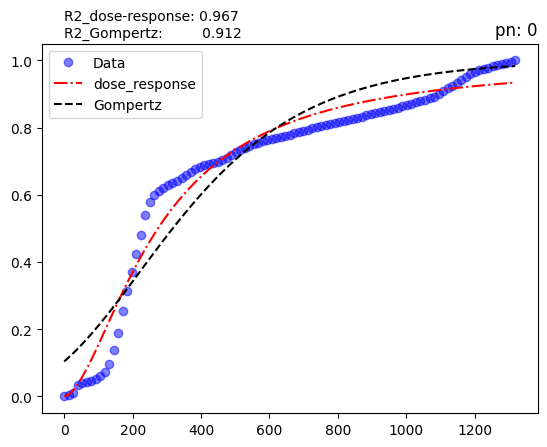

datapoint=  1
no=  2
The optimized parameters for dose-response are: [   3.866 1885.908]
The optimized parameters for Gompertz are: [ 749.893 1609.155]


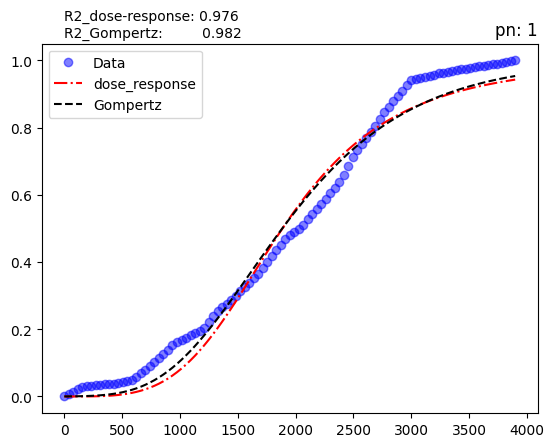

datapoint=  2
no=  3
The optimized parameters for dose-response are: [  2.165 582.503]
The optimized parameters for Gompertz are: [411.388 464.211]


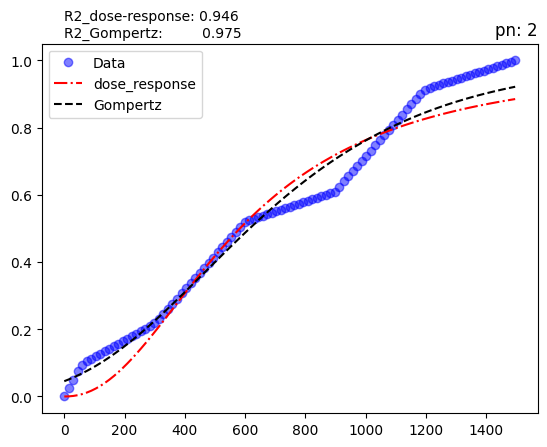

datapoint= 

 3
no=  4
The optimized parameters for dose-response are: [  2.14  690.176]
The optimized parameters for Gompertz are: [507.811 547.794]


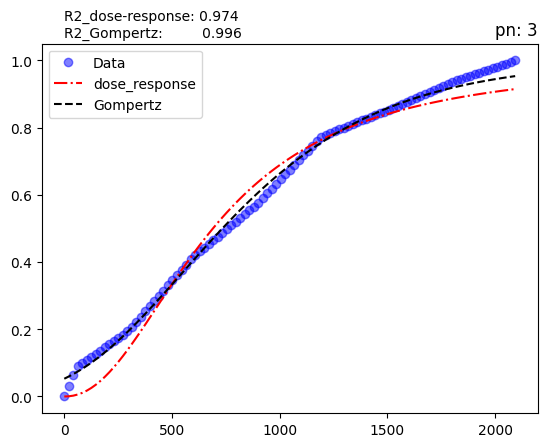

datapoint=  4
no=  5
The optimized parameters for dose-response are: [  1.775 842.165]
The optimized parameters for Gompertz are: [799.792 645.289]


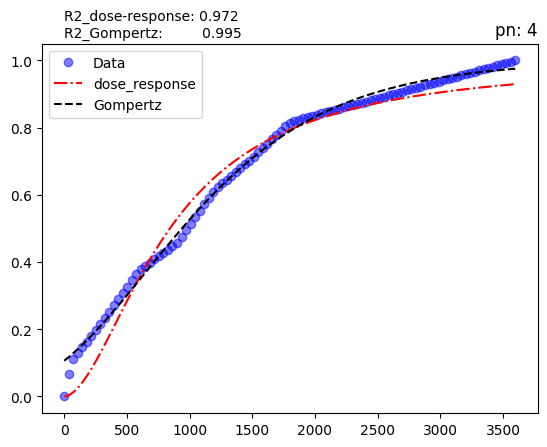

datapoint=  5
no=  7
The optimized parameters for dose-response are: [   2.18  1510.678]
The optimized parameters for Gompertz are: [1063.187 1215.686]


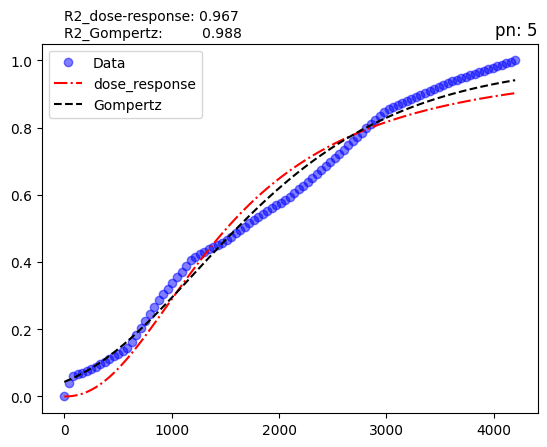

datapoint=  6
no=  9
The optimized parameters for dose-response are: [  1.241 497.237]
The optimized parameters for Gompertz are: [858.984 316.279]


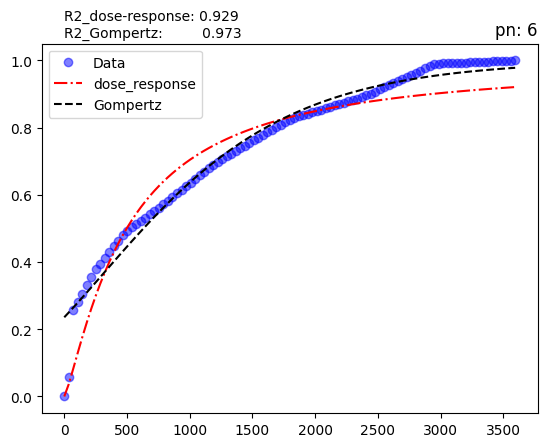

datapoint=  7
no=  10
The optimized parameters for dose-response are: [  1.564 248.588]
The optimized parameters for Gompertz are: [281.221 186.217]


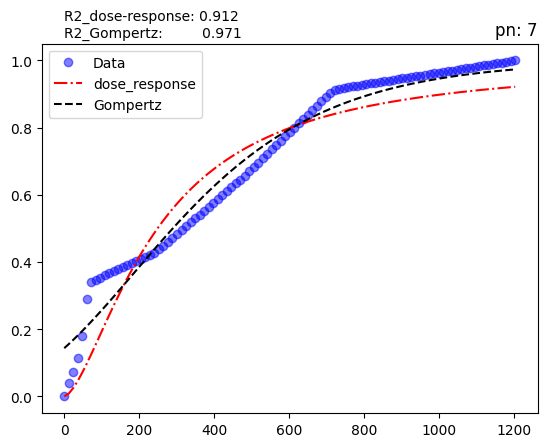

datapoint=  8
no=  11
The optimized parameters for dose-response are: [  2.519 415.669]
The optimized parameters for Gompertz are: [252.303 340.082]


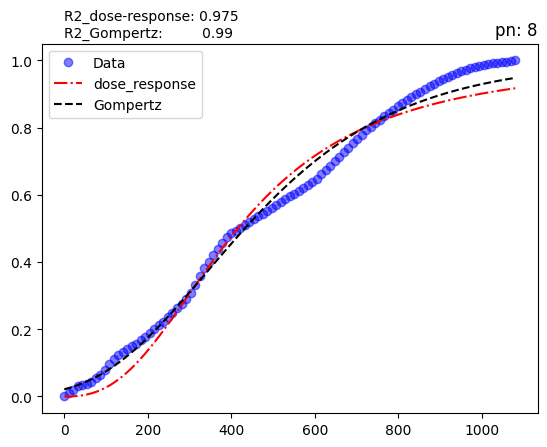

datapoint=  9
no=  12
The optimized parameters for dose-response are: [  2.629 385.368]
The optimized parameters for Gompertz are: [228.097 315.715]


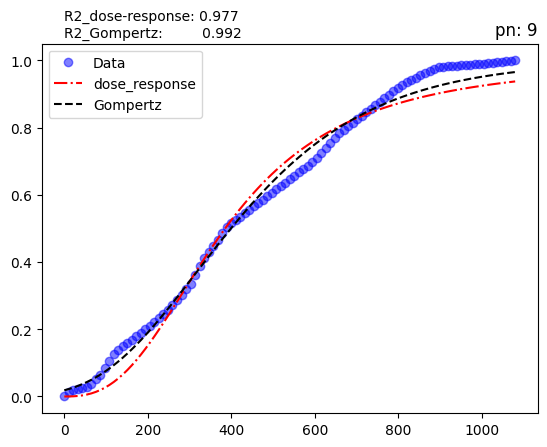

datapoint=  10
no=  13
The optimized parameters for dose-response are: [  2.648 336.369]
The optimized parameters for Gompertz are: [202.537 274.521]


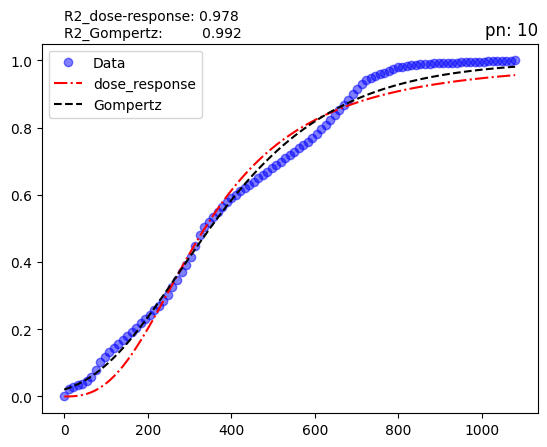

datapoint=  11
no=  14
The optimized parameters for dose-response are: [  2.956 510.579]
The optimized parameters for Gompertz are: [261.801 424.833]


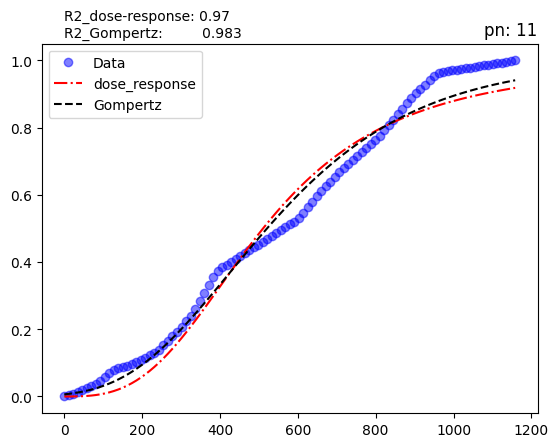

datapoint=  12
no=  15
The optimized parameters for dose-response are: [  2.881 484.459]
The optimized parameters for Gompertz are: [254.856 401.495]


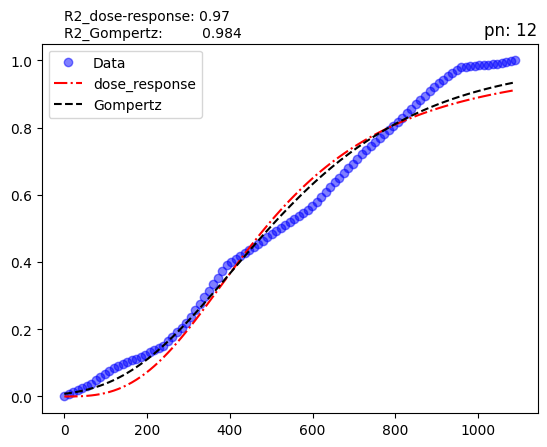

datapoint=  13
no=  16
The optimized parameters for dose-response are: [  2.657 420.858]
The optimized parameters for Gompertz are: [244.266 344.816]


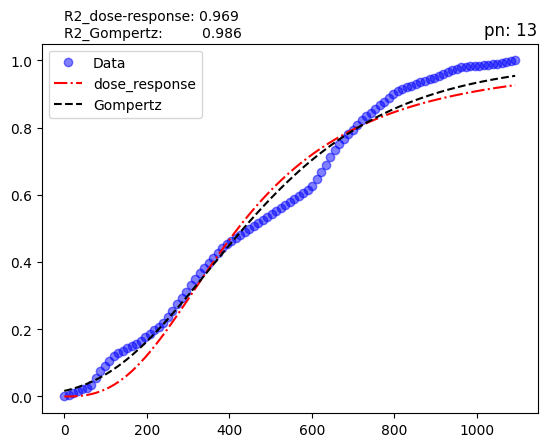

datapoint=  14
no=  17
The optimized parameters for dose-response are: [ 1.477 23.084]
The optimized parameters for Gompertz are: [17.266 19.684]


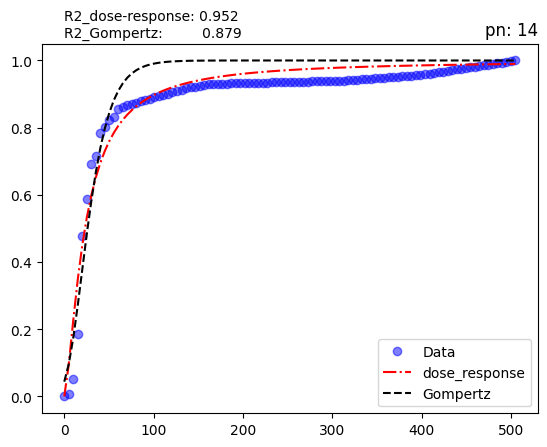

datapoint=  15
no=  18
The optimized parameters for dose-response are: [ 2.025 29.233]
The optimized parameters for Gompertz are: [19.921 24.373]


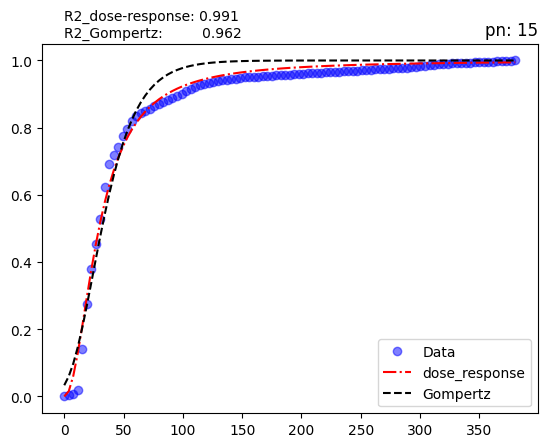

datapoint=  16
no=  19
The optimized parameters for dose-response are: [  2.696 243.07 ]
The optimized parameters for Gompertz are: [122.543 203.551]


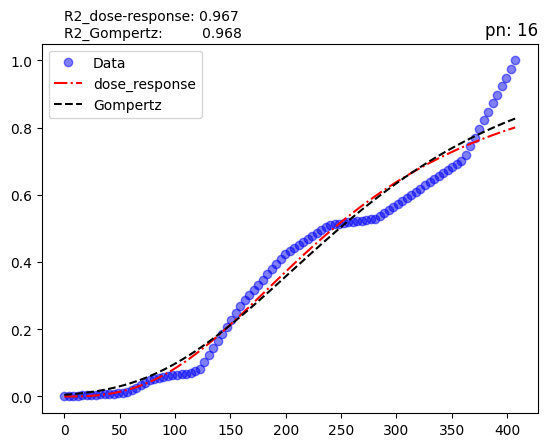

datapoint=  17
no=  20
The optimized parameters for dose-response are: [ 1.8   10.616]
The optimized parameters for Gompertz are: [9.562 8.504]


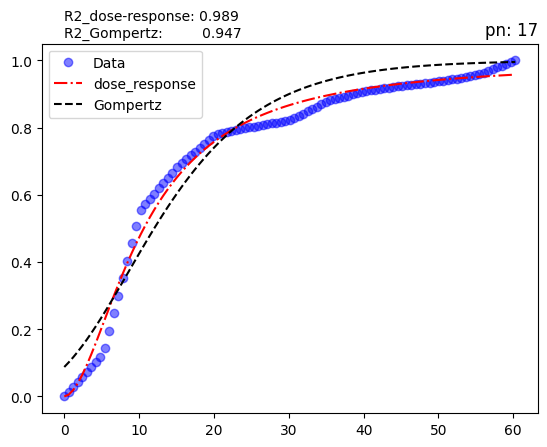

datapoint=  18
no=  21
The optimized parameters for dose-response are: [ 1.978 22.181]
The optimized parameters for Gompertz are: [17.094 18.287]


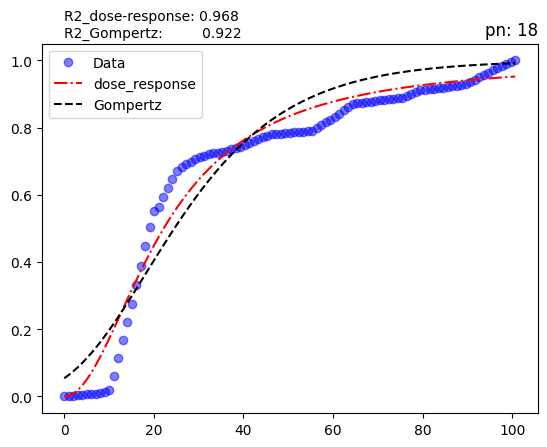

datapoint=  19
no=  22
The optimized parameters for dose-response are: [ 3.913 66.923]
The optimized parameters for Gompertz are: [25.469 58.028]


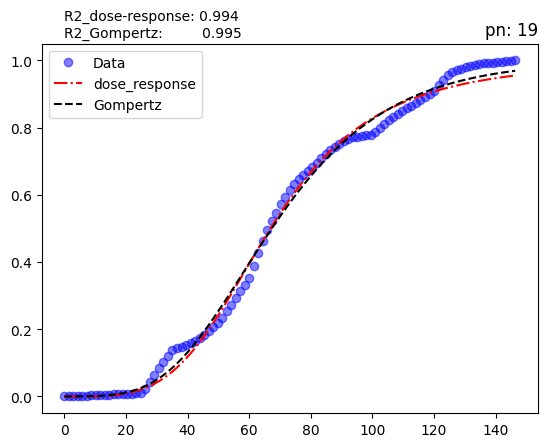

datapoint=  20
no=  23
The optimized parameters for dose-response are: [1.617 5.8  ]
The optimized parameters for Gompertz are: [6.385 4.44 ]


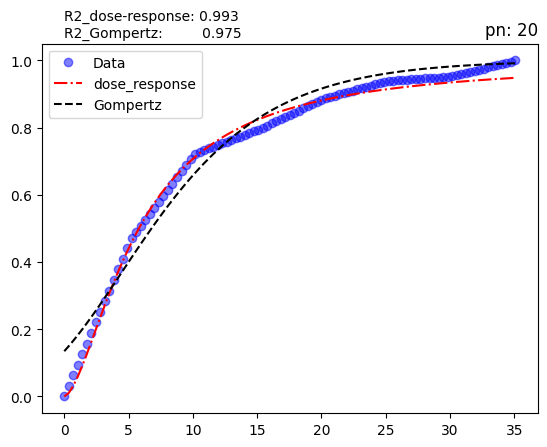

datapoint=  21
no=  24
The optimized parameters for dose-response are: [ 2.483 29.666]
The optimized parameters for Gompertz are: [17.972 24.818]


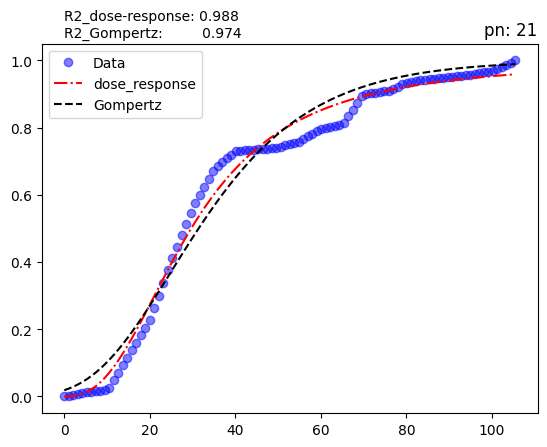

datapoint=  22
no=  25
The optimized parameters for dose-response are: [ 2.092 23.125]
The optimized parameters for Gompertz are: [17.663 18.865]


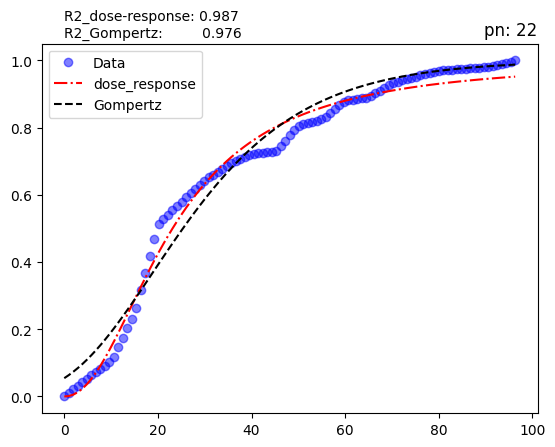

datapoint=  23
no=  26
The optimized parameters for dose-response are: [2.595 8.725]
The optimized parameters for Gompertz are: [4.989 7.284]


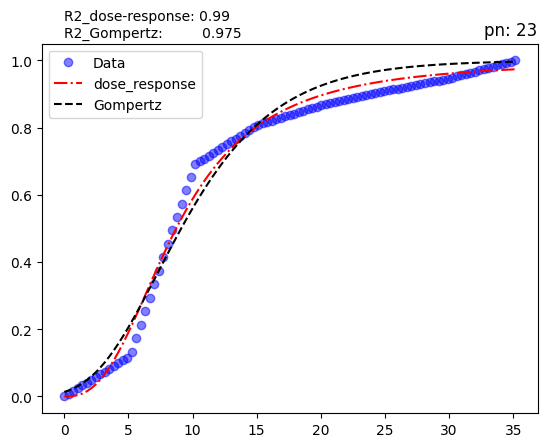

datapoint=  24
no=  27
The optimized parameters for dose-response are: [1.581 4.132]
The optimized parameters for Gompertz are: [4.833 3.109]


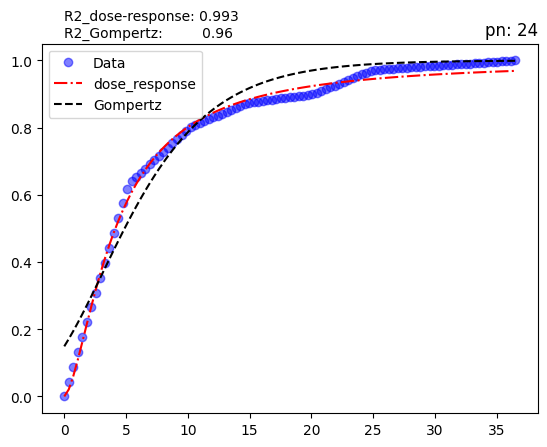

datapoint=  25
no=  28
The optimized parameters for dose-response are: [1.231 6.802]
The optimized parameters for Gompertz are: [12.451  4.102]


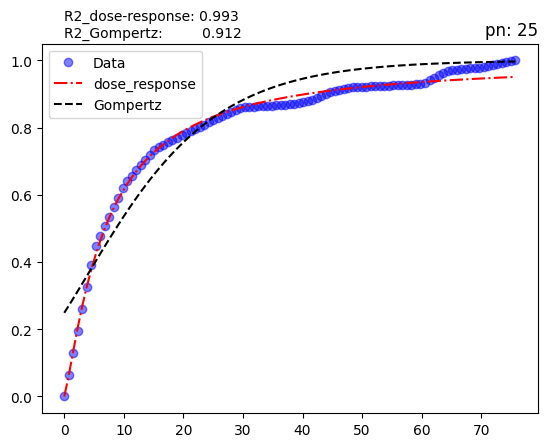

datapoint=  26
no=  29
The optimized parameters for dose-response are: [ 2.863 39.476]
The optimized parameters for Gompertz are: [20.655 33.239]


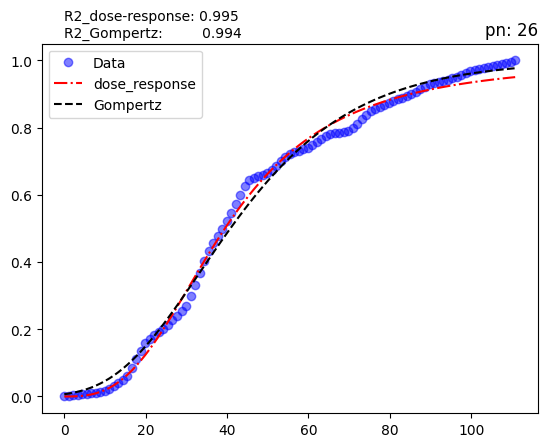

datapoint=  27
no=  30
The optimized parameters for dose-response are: [2.31  4.097]
The optimized parameters for Gompertz are: [2.875 3.284]


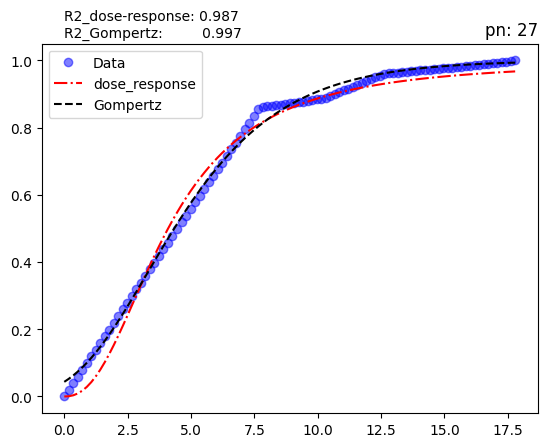

datapoint=  28
no=  31
The optimized parameters for dose-response are: [1.553 9.88 ]
The optimized parameters for Gompertz are: [11.432  7.514]


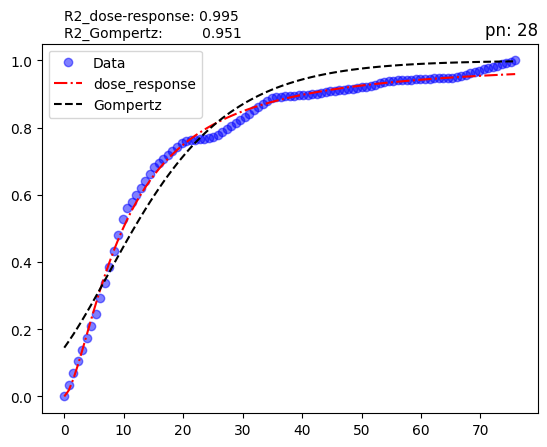

datapoint=  29
no=  32
The optimized parameters for dose-response are: [1.133 4.87 ]
The optimized parameters for Gompertz are: [11.077  2.244]


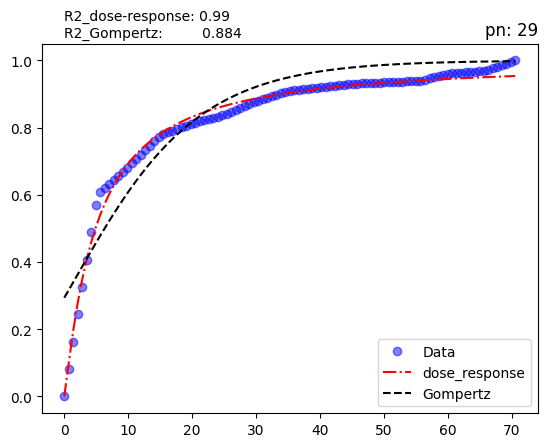

datapoint=  30
no=  33
The optimized parameters for dose-response are: [1.894 3.156]
The optimized parameters for Gompertz are: [2.757 2.494]


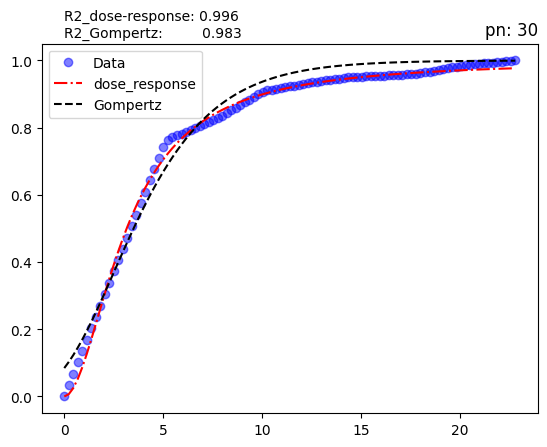

datapoint=  31
no=  34
The optimized parameters for dose-response are: [ 1.484 37.349]
The optimized parameters for Gompertz are: [45.573 28.131]


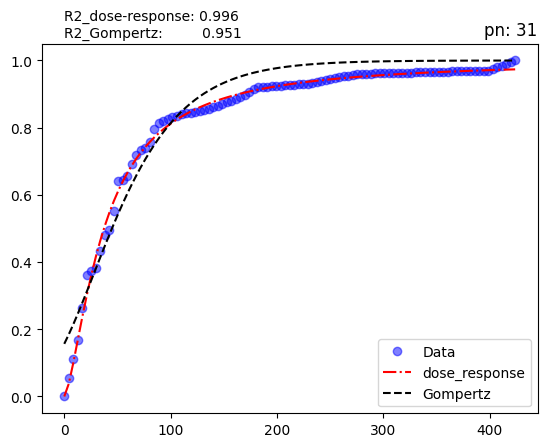

datapoint=  32
no=  35
The optimized parameters for dose-response are: [  1.586 129.852]
The optimized parameters for Gompertz are: [134.839 103.881]


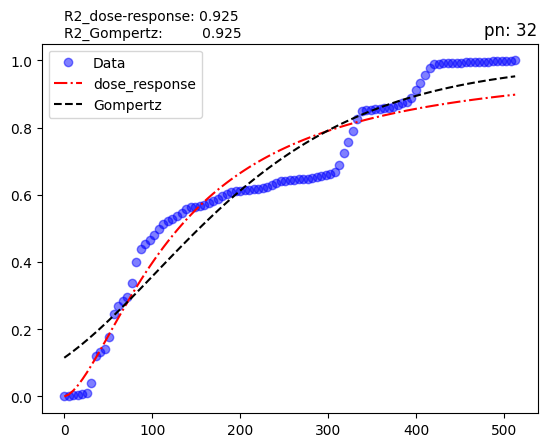

datapoint=  33
no=  36
The optimized parameters for dose-response are: [  7.072 409.215]
The optimized parameters for Gompertz are: [ 84.53  375.411]


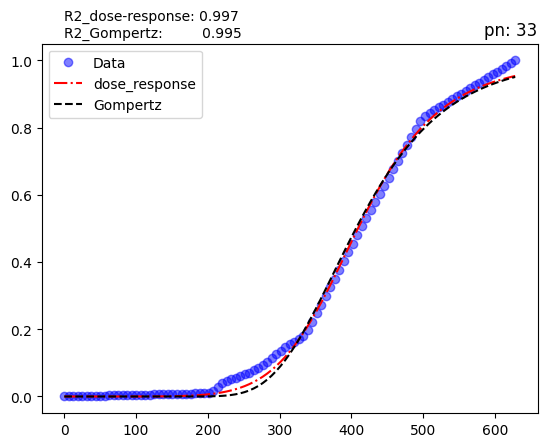

datapoint=  34
no=  37
The optimized parameters for dose-response are: [1.8745000e+01 4.1575249e+04]
The optimized parameters for Gompertz are: [ 3089.327 40267.041]


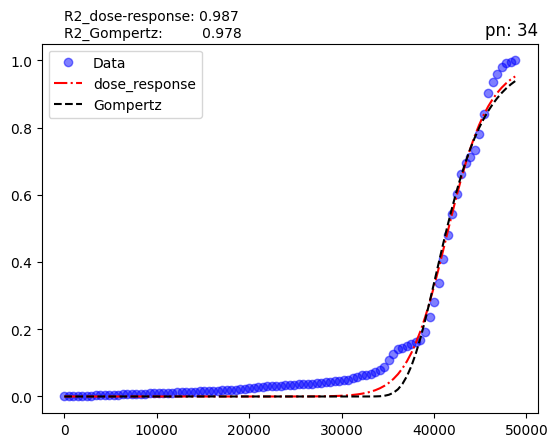

datapoint=  35
no=  38
The optimized parameters for dose-response are: [ 3.35  66.262]
The optimized parameters for Gompertz are: [28.627 56.948]


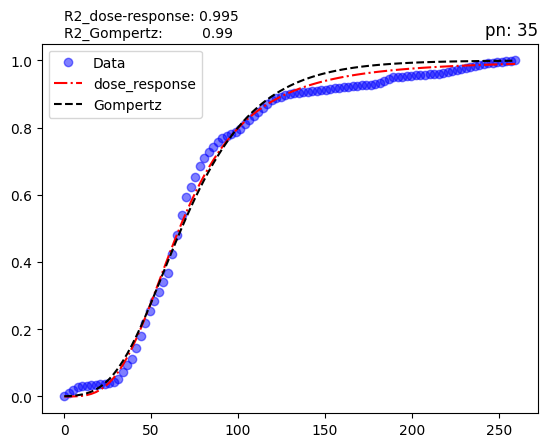

datapoint=  36
no=  39
The optimized parameters for dose-response are: [  7.173 496.18 ]
The optimized parameters for Gompertz are: [100.815 455.308]


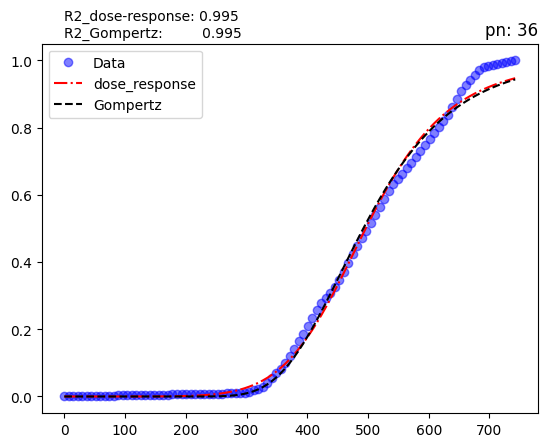

datapoint=  37
no=  40
The optimized parameters for dose-response are: [  8.134 578.59 ]
The optimized parameters for Gompertz are: [103.227 535.945]


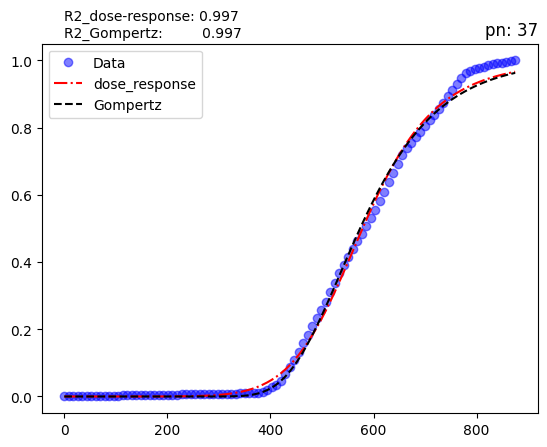

datapoint=  38
no=  41
The optimized parameters for dose-response are: [  8.827 704.384]
The optimized parameters for Gompertz are: [116.505 655.625]


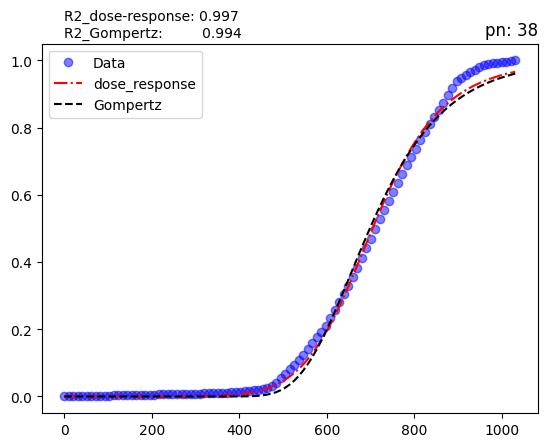

datapoint=  39
no=  42
The optimized parameters for dose-response are: [  7.2   803.428]
The optimized parameters for Gompertz are: [161.451 738.288]


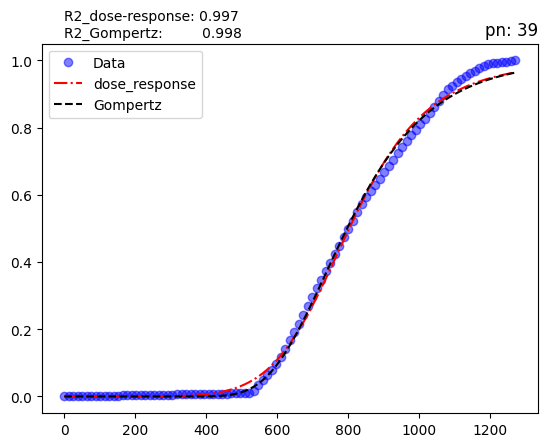

datapoint=  40
no=  43
The optimized parameters for dose-response are: [   6.166 1150.94 ]
The optimized parameters for Gompertz are: [ 271.36 1044.05]


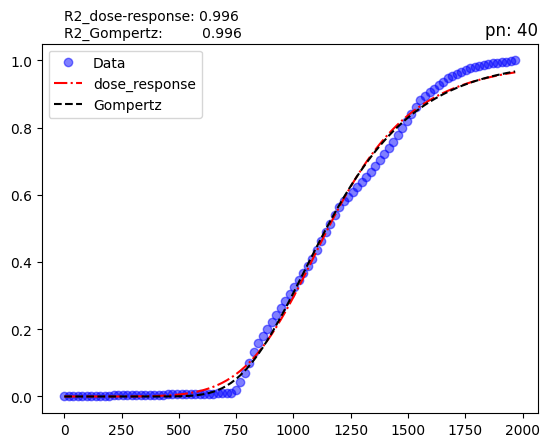

datapoint=  41
no=  44
The optimized parameters for dose-response are: [  9.554 385.49 ]
The optimized parameters for Gompertz are: [ 58.555 360.838]


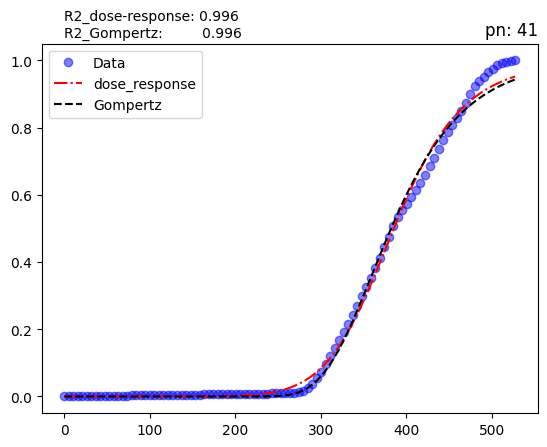

datapoint=  42
no=  45
The optimized parameters for dose-response are: [  6.67  240.344]
The optimized parameters for Gompertz are: [ 52.173 219.565]


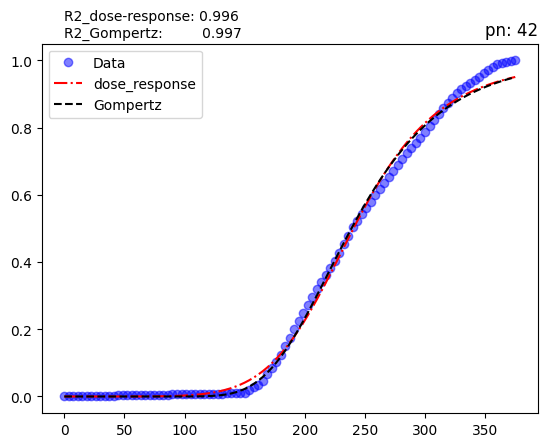

datapoint=  43
no=  46
The optimized parameters for dose-response are: [ 4.166 27.98 ]
The optimized parameters for Gompertz are: [ 8.834 24.811]


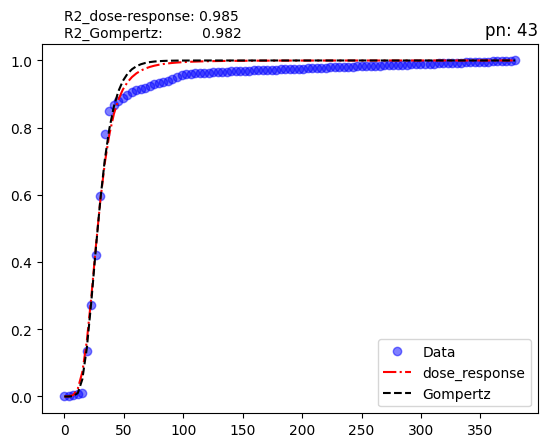

datapoint=  44
no=  47
The optimized parameters for dose-response are: [ 4.546 21.079]
The optimized parameters for Gompertz are: [ 5.76  18.918]


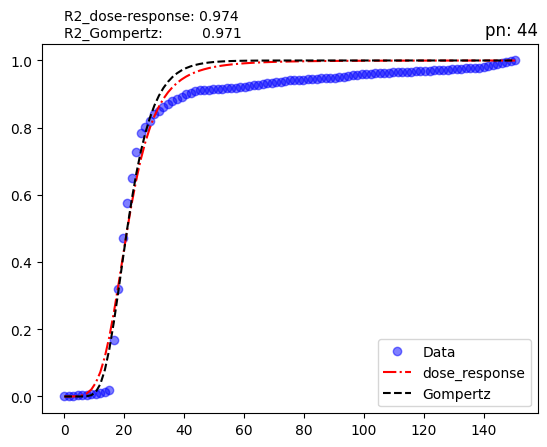

datapoint=  45
no=  48
The optimized parameters for dose-response are: [ 1.034 31.809]
The optimized parameters for Gompertz are: [27.055 33.616]


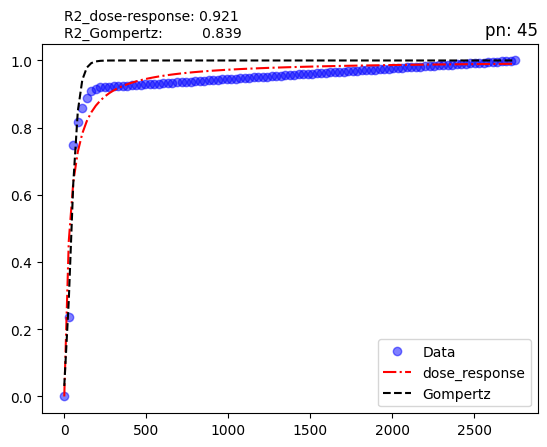

datapoint=  46
no=  49
The optimized parameters for dose-response are: [ 1.982 18.417]
The optimized parameters for Gompertz are: [12.179 15.385]


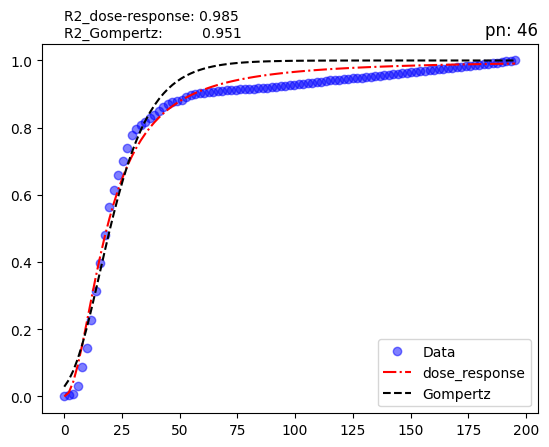

datapoint=  47
no=  50
The optimized parameters for dose-response are: [ 1.71  12.401]
The optimized parameters for Gompertz are: [ 8.186 10.534]


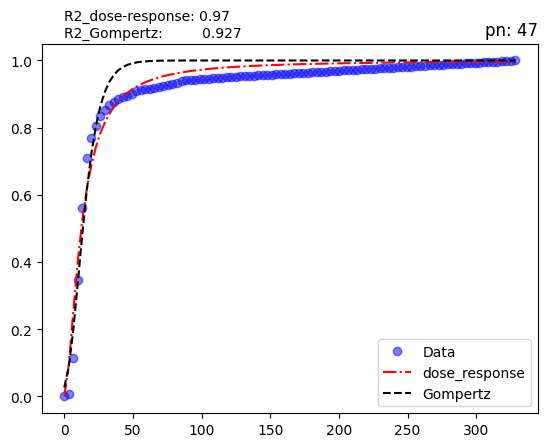

datapoint= 

 48
no=  57
The optimized parameters for dose-response are: [ 1.736 23.57 ]
The optimized parameters for Gompertz are: [22.659 18.63 ]


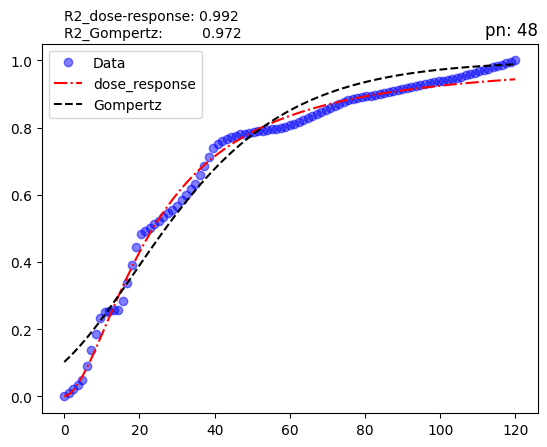

datapoint=  49
no=  61
The optimized parameters for dose-response are: [ 3.992 32.944]
The optimized parameters for Gompertz are: [12.824 28.111]


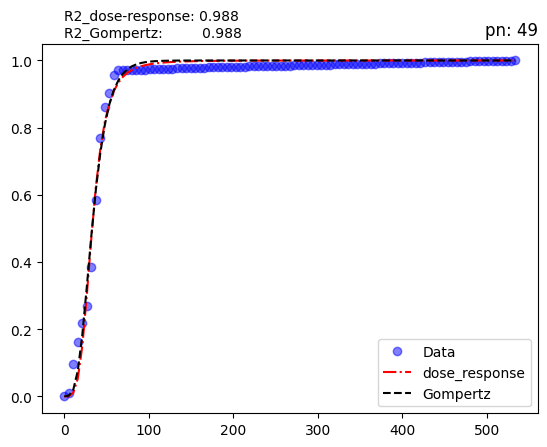

datapoint=  50
no=  62
The optimized parameters for dose-response are: [ 4.362 40.038]
The optimized parameters for Gompertz are: [13.624 34.999]


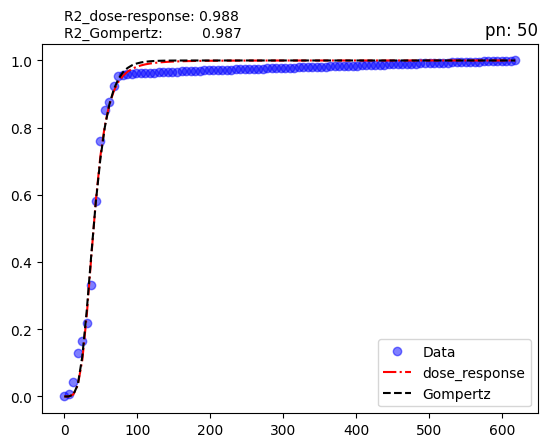

datapoint=  51
no=  64
The optimized parameters for dose-response are: [ 4.75  36.628]
The optimized parameters for Gompertz are: [12.025 31.906]


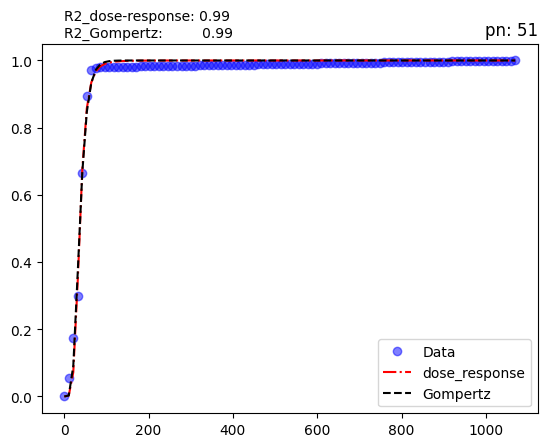

datapoint=  52
no=  65
The optimized parameters for dose-response are: [ 5.437 40.456]
The optimized parameters for Gompertz are: [11.208 36.123]


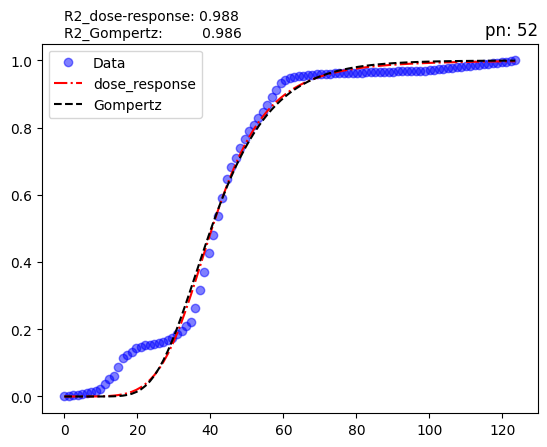

datapoint=  53
no=  66
The optimized parameters for dose-response are: [ 5.56  57.561]
The optimized parameters for Gompertz are: [16.22  50.852]


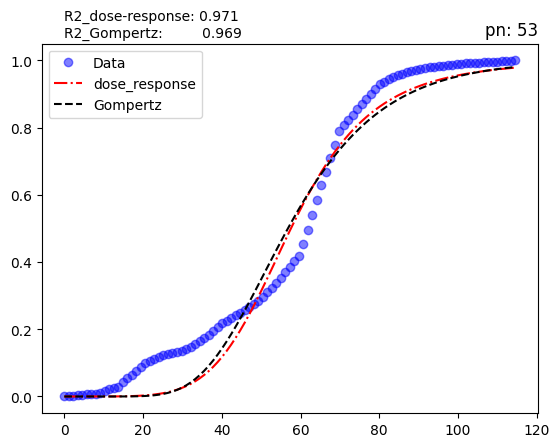

datapoint=  54
no=  67
The optimized parameters for dose-response are: [ 5.024 51.362]
The optimized parameters for Gompertz are: [16.202 44.744]


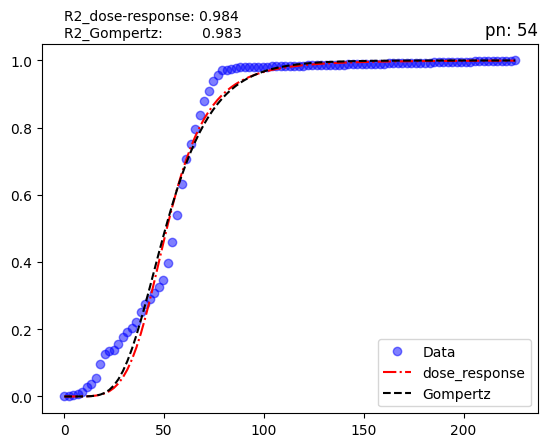

datapoint=  55
no=  68
The optimized parameters for dose-response are: [  1.066 151.845]
The optimized parameters for Gompertz are: [436.535  36.527]


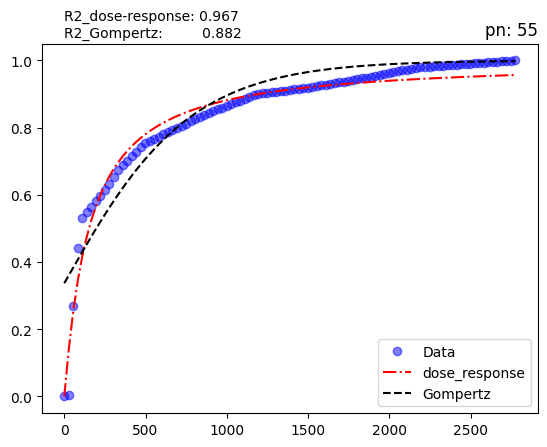

datapoint=  56
no=  69
The optimized parameters for dose-response are: [  1.336 465.632]
The optimized parameters for Gompertz are: [715.064 329.328]


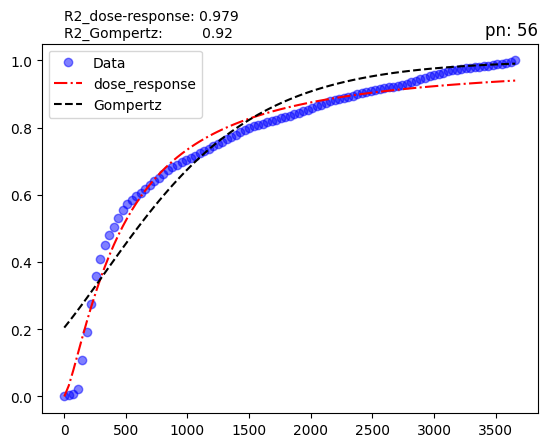

datapoint=  57
no=  70
The optimized parameters for dose-response are: [   3.159 1939.044]
The optimized parameters for Gompertz are: [ 896.385 1648.912]


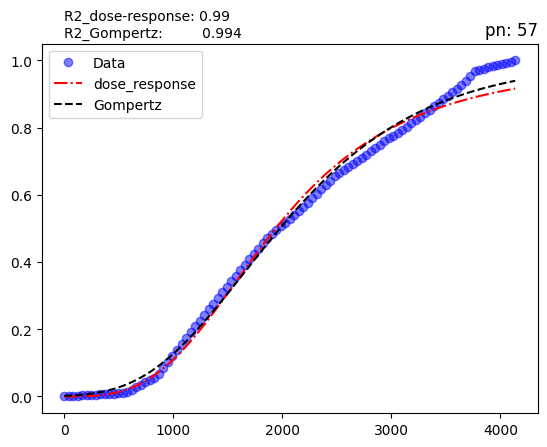

datapoint=  58
no=  71
The optimized parameters for dose-response are: [  5.824 382.183]
The optimized parameters for Gompertz are: [ 97.253 344.07 ]


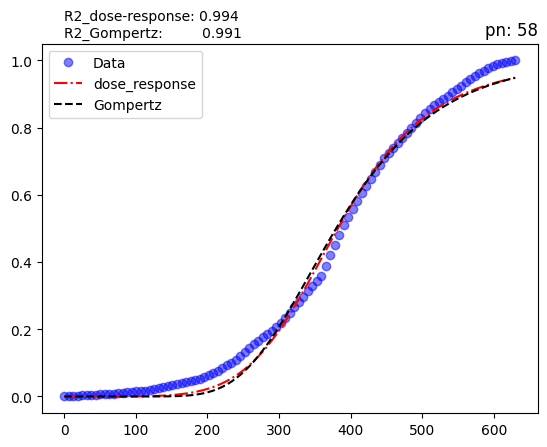

datapoint=  59
no=  72
The optimized parameters for dose-response are: [  5.015 353.167]
The optimized parameters for Gompertz are: [104.358 313.388]


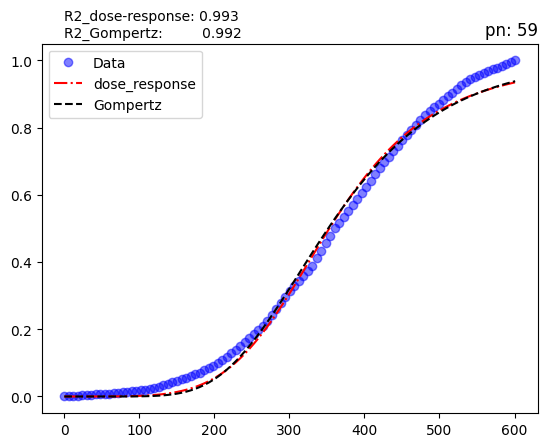

datapoint=  60
no=  73
The optimized parameters for dose-response are: [  3.68  156.115]
The optimized parameters for Gompertz are: [ 63.005 134.773]


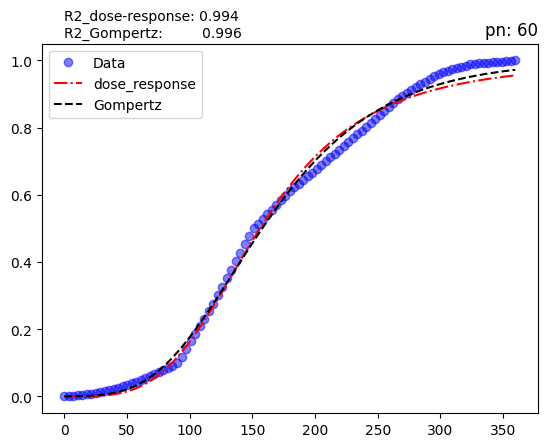

datapoint=  61
no=  74
The optimized parameters for dose-response are: [  5.999 467.316]
The optimized parameters for Gompertz are: [116.162 420.993]


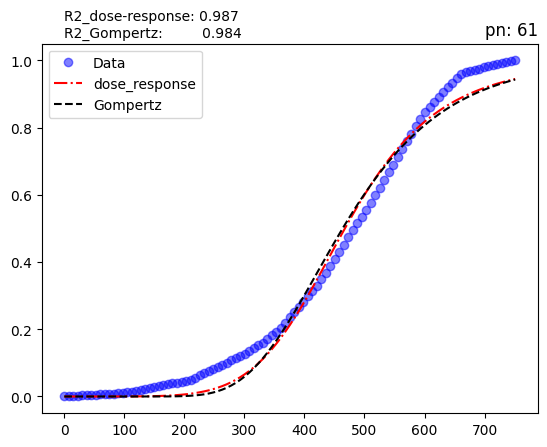

datapoint=  62
no=  77
The optimized parameters for dose-response are: [ 1.933 43.931]
The optimized parameters for Gompertz are: [21.712 37.738]


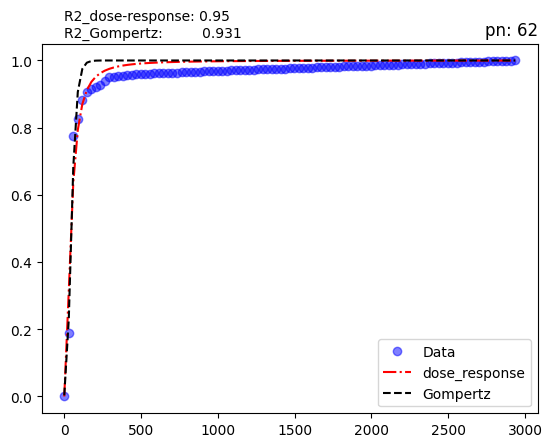

datapoint=  63
no=  78
The optimized parameters for dose-response are: [ 3.456 18.668]
The optimized parameters for Gompertz are: [ 7.425 16.203]


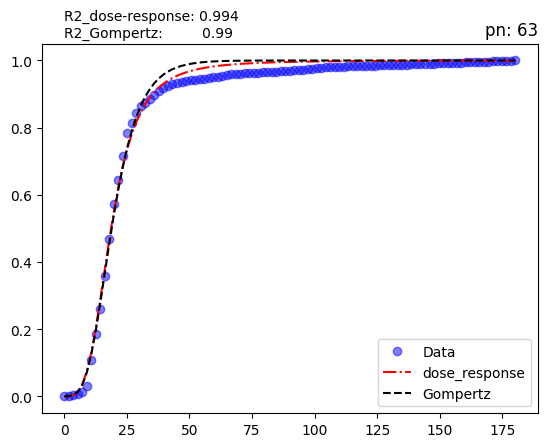

datapoint=  64
no=  79
The optimized parameters for dose-response are: [ 5.214 14.438]
The optimized parameters for Gompertz are: [ 3.901 12.997]


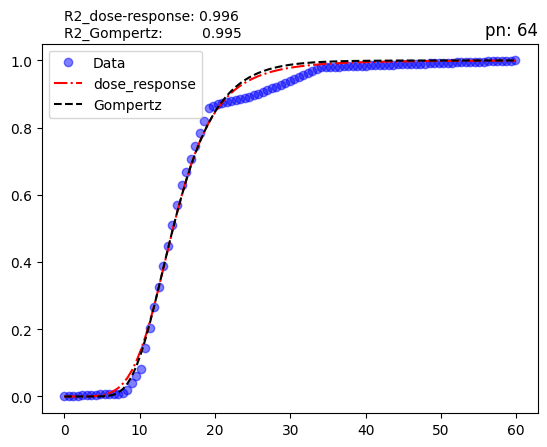

datapoint=  65
no=  80
The optimized parameters for dose-response are: [ 4.698 14.009]
The optimized parameters for Gompertz are: [ 4.213 12.496]


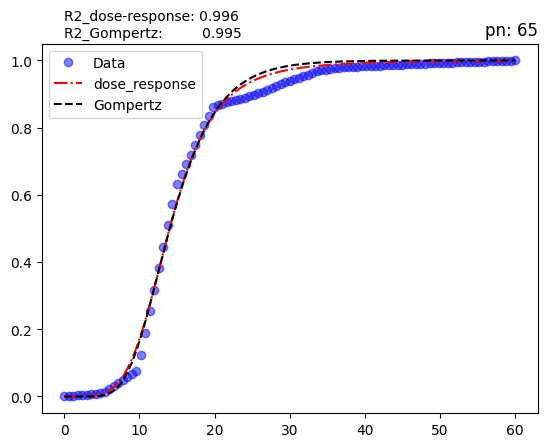

datapoint=  66
no=  81
The optimized parameters for dose-response are: [3.862 3.324]
The optimized parameters for Gompertz are: [1.211 2.904]


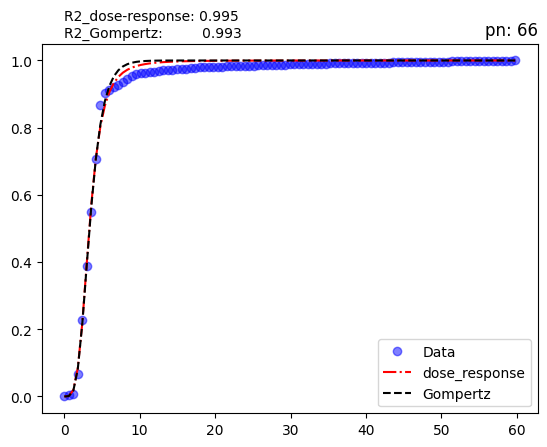

datapoint=  67
no=  82
The optimized parameters for dose-response are: [0.623 0.281]
The optimized parameters for Gompertz are: [1.668 2.725]


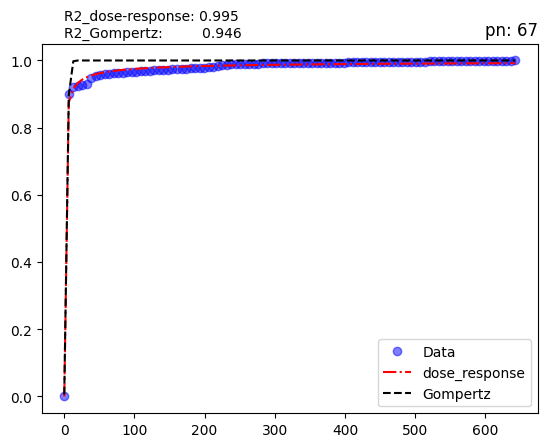

datapoint= 

 68
no=  83
The optimized parameters for dose-response are: [2.3   3.687]
The optimized parameters for Gompertz are: [2.177 3.051]


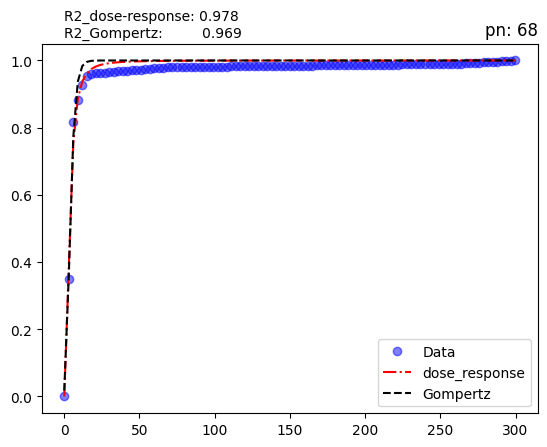

datapoint=  69
no=  84
The optimized parameters for dose-response are: [0.454 0.287]
The optimized parameters for Gompertz are: [1.843 2.366]


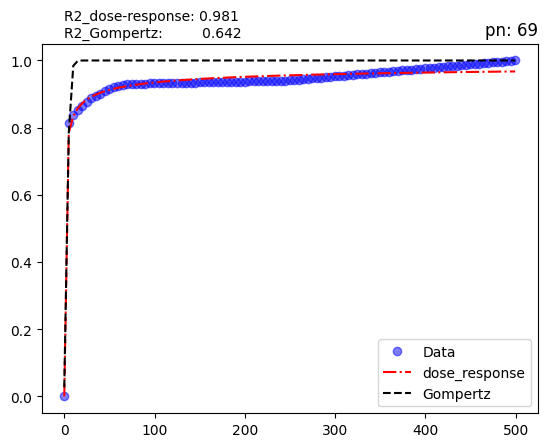

datapoint=  70
no=  85
The optimized parameters for dose-response are: [0.485 0.103]
The optimized parameters for Gompertz are: [1.431 2.321]


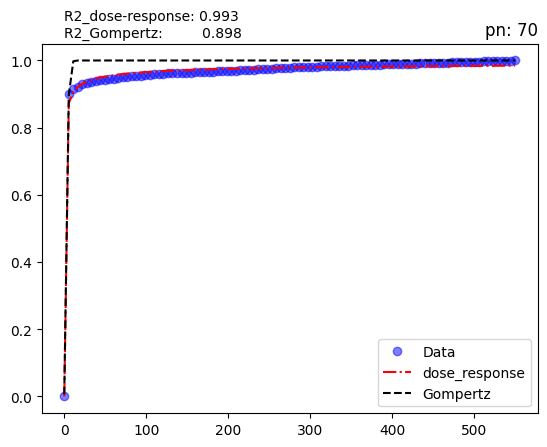

datapoint=  71
no=  6
The optimized parameters for dose-response are: [   3.326 1459.025]
The optimized parameters for Gompertz are: [ 681.021 1219.624]


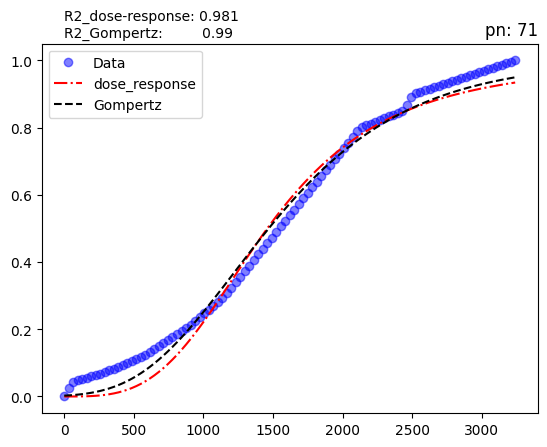

datapoint=  72
no=  8
The optimized parameters for dose-response are: [  3.426 774.246]
The optimized parameters for Gompertz are: [355.809 643.025]


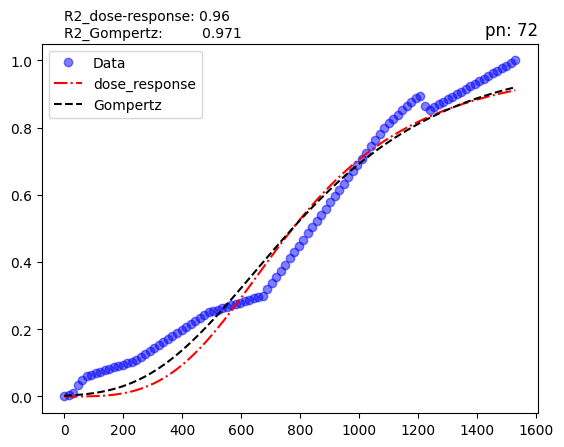

datapoint=  73
no=  51
The optimized parameters for dose-response are: [ 1.956 39.809]
The optimized parameters for Gompertz are: [21.734 34.38 ]


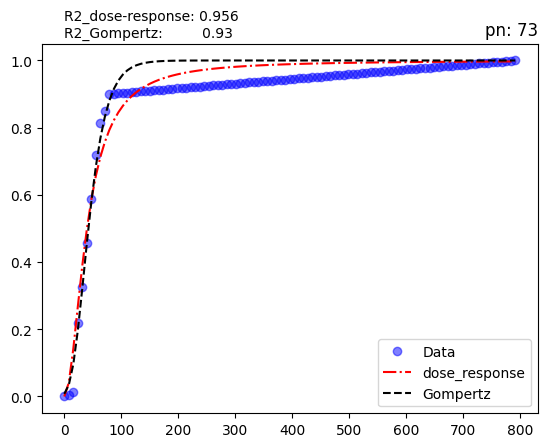

datapoint=  74
no=  52
The optimized parameters for dose-response are: [ 1.806 43.891]
The optimized parameters for Gompertz are: [24.89  37.902]


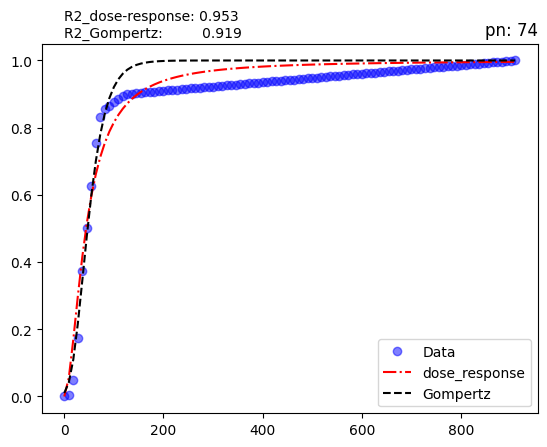

datapoint=  75
no=  53
The optimized parameters for dose-response are: [ 2.388 34.043]
The optimized parameters for Gompertz are: [19.374 28.731]


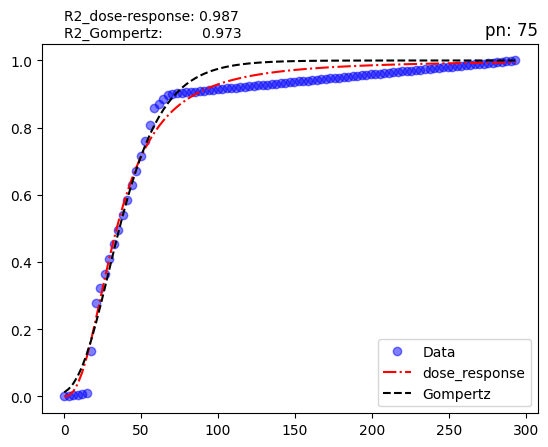

datapoint=  76
no=  54
The optimized parameters for dose-response are: [ 2.163 53.157]
The optimized parameters for Gompertz are: [28.    45.324]


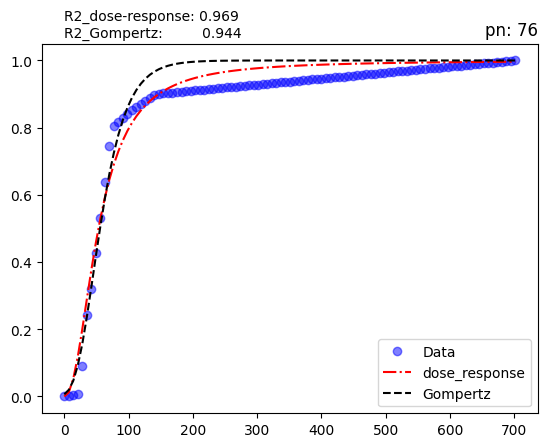

datapoint=  77
no=  55
The optimized parameters for dose-response are: [ 2.545 30.319]
The optimized parameters for Gompertz are: [18.627 24.812]


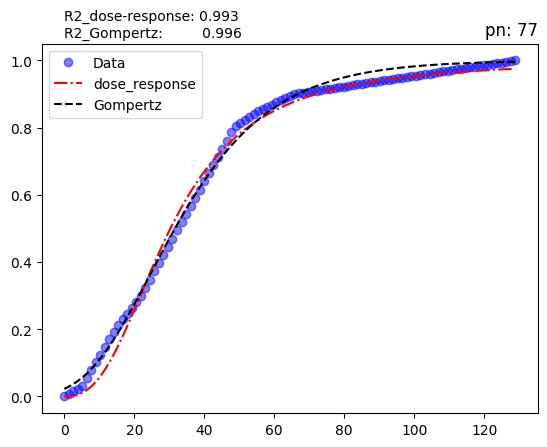

datapoint=  78
no=  56
The optimized parameters for dose-response are: [ 2.348 33.568]
The optimized parameters for Gompertz are: [19.494 28.3  ]


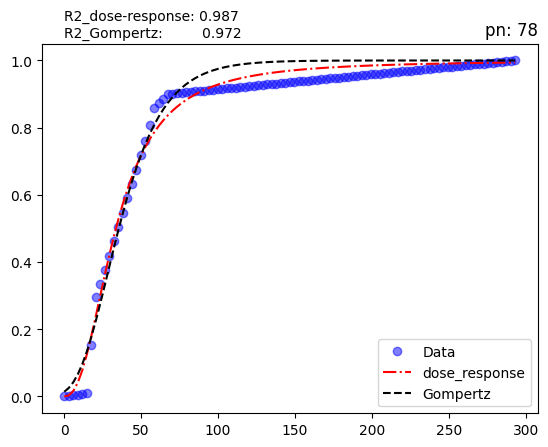

datapoint=  79
no=  58
The optimized parameters for dose-response are: [ 2.707 54.815]
The optimized parameters for Gompertz are: [32.544 43.963]


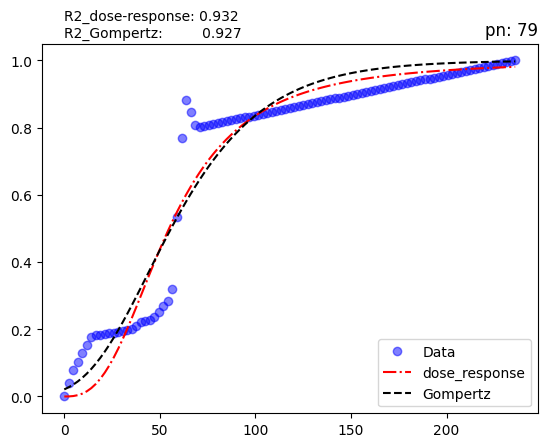

datapoint=  80
no=  59
The optimized parameters for dose-response are: [ 2.515 30.216]
The optimized parameters for Gompertz are: [18.843 24.676]


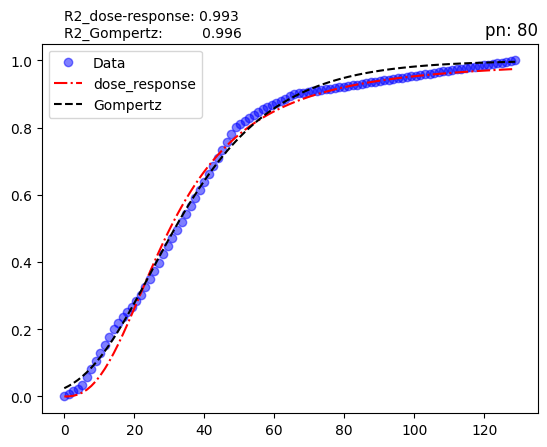

datapoint=  81
no=  60
The optimized parameters for dose-response are: [   3.903 2003.772]
The optimized parameters for Gompertz are: [ 759.549 1735.161]


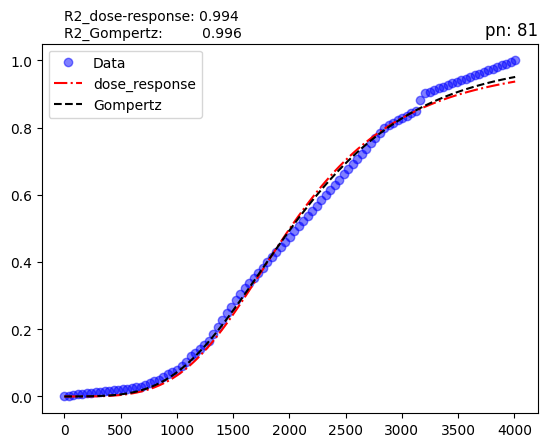

datapoint=  82
no=  63
The optimized parameters for dose-response are: [ 3.203 58.216]
The optimized parameters for Gompertz are: [25.675 49.722]


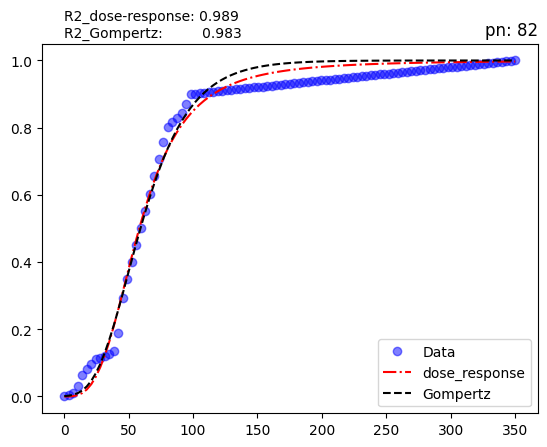

datapoint=  83
no=  75
The optimized parameters for dose-response are: [  4.714 258.421]
The optimized parameters for Gompertz are: [ 79.422 229.485]


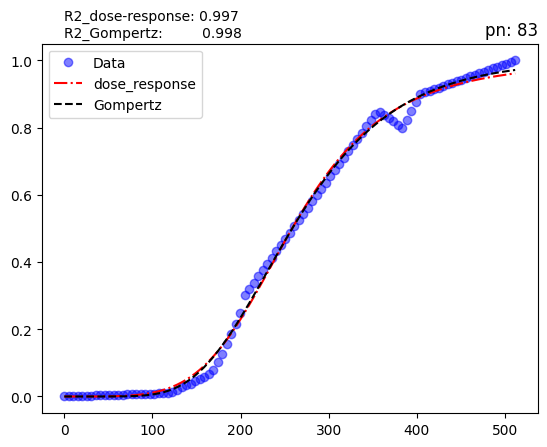

datapoint=  84
no=  76
The optimized parameters for dose-response are: [  5.292 328.245]
The optimized parameters for Gompertz are: [ 89.132 294.651]


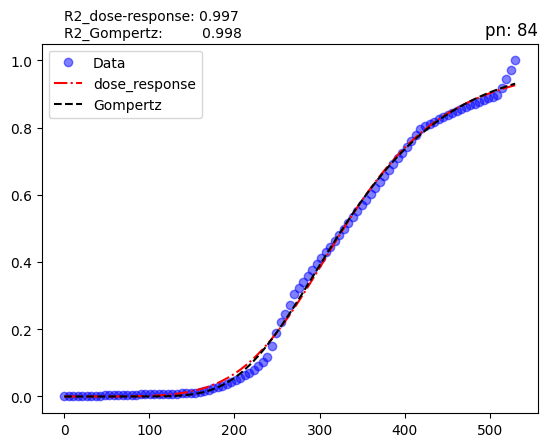

In [26]:

#-------------------------------------------------------------
import os
os.makedirs('Data Fitting', exist_ok=True)
data={'a': [], 'b':[], 'K': [], 'T':[], 'R2_dose-response': [], 'R2-Gompertz': []}
Coefficent_data = pd.DataFrame(data)
#-------------------------------------------------------------
for i in range(0,len(Final_DF)):
    # Define the model equation to fit to the data


    # Generate some sample data
    x_data = np.asanyarray(Final_DF[i]['t'])
    y_data = np.asanyarray(Final_DF[i]['C'])

#---------------------------------------------------------------------
# Define the number of points to interpolate
    num_interp_points = 101

# Create a new array of x values with the desired number of points
    x_interp = np.linspace(x_data.min(), x_data.max(), num=num_interp_points)

# Create an interpolation function for the y values
    interp_func = interp1d(x_data, y_data, kind='linear')

# Interpolate the y values at the new x values
    y_interp = interp_func(x_interp)
#----------------------------------------------------------------------------------

# Fit the model equation to the data
    popt_dr, pcov_dr = curve_fit(dose_response, x_interp, y_interp, bounds=[0,100000000], method='trf', p0 =[1, x_interp[np.argmin(abs(y_interp-0.5))]])
#    popt_clark, pcov_clark = curve_fit(Clark, x_interp, y_interp,  bounds=[0,10000000], method='trf', p0 =[1,0.5])
    popt_gompertz, pcov_gompertz = curve_fit(Gompertz, x_interp, y_interp, bounds=[0,100000000], method='trf', p0 =[0.1*x_interp[np.argmin(abs(y_interp-0.5))], x_interp[np.argmin(abs(y_interp-0.5))]])
    
    #Calculate the r2 score
    R2_dr= r2_score(y_interp, dose_response(x_interp, *popt_dr))
#    R2_clark= r2_score(y_interp, Clark(x_interp, *popt_clark))
    R2_gompertz= r2_score(y_interp, Gompertz(x_interp, *popt_gompertz))
    
    # Add a new row to the DataFrame
    new_row = {'a': popt_dr[0], 'b': popt_dr[1],
               'K': popt_gompertz[0], 'T': popt_gompertz[1],
              'R2_dose-response': R2_dr,  'R2-Gompertz': R2_gompertz}
    Coefficent_data.loc[len(Coefficent_data)] = new_row
    #Calculate the r2 score
    R2_dr= r2_score(y_interp, dose_response(x_interp, *popt_dr))
#    R2_clark= r2_score(y_interp, Clark(x_interp, *popt_clark))
    R2_gompertz= r2_score(y_interp, Gompertz(x_interp, *popt_gompertz))
    
# Print the optimized parameters
    print('datapoint= ', i)
    print('no= ', sorted_df['no'].iloc[i])
    print(f"The optimized parameters for dose-response are: {popt_dr.round(3)}")
#    print(f"The optimized parameters for clark are: {popt_clark.round(3)}")
    print(f"The optimized parameters for Gompertz are: {popt_gompertz.round(3)}")


# Plot the data and the fitted equation
    plt.plot(x_interp, y_interp, 'bo', label='Data', alpha=0.5)
    plt.plot(x_interp, dose_response(x_interp, *popt_dr), 'r-.', label='dose_response')
#    plt.plot(x_interp, Clark(x_interp, *popt_clark), 'g-', label='Clark') 
    plt.plot(x_interp, Gompertz(x_interp, *popt_gompertz), 'k--', label='Gompertz') 
    plt.text(x_data.max()*0.00, 1.12,  ('R2_dose-response: ' + str(round(R2_dr, 3))))
#    plt.text(x_data.max()*0.00,1.15,  ('R2_Clark:                ' + str(round(R2_clark, 3))))
    plt.text(x_data.max()*0.00, 1.07,  ('R2_Gompertz:         ' + str(round(R2_gompertz, 3))))
    plt.legend()
    plt.title('pn: ' + str(i), loc='right')
    picname= 'Data Fitting/'+str(i) + ' no' +  str(sorted_df['no'].iloc[i]) 
    plt.savefig(picname, dpi=150)
    plt.show()


In [27]:
sorted_df.sort_values(['no'],ignore_index=False)

,no,ph_sol,initial_concentration,flowrate,pyrolysis_temp,pyrolysis_time,S_Bet,particle_size,bc_weight,col_d,col_h,BC,sort,Modified_BC
0,1,6.0,50.00,1.206642,600.0,60.0,154.25,0.25,0.3,16.998275,38.733061,t C 0 0.000000 0.0...,0,t C 0 0.00 0.00 1 2...
1,2,6.0,50.00,0.600000,600.0,60.0,170.34,0.25,0.3,17.816205,38.679527,t C 0 0.000000 0.0...,0,t C 0 0.00 0.00 1 5...
2,3,3.0,50.00,0.845751,600.0,60.0,170.34,0.25,0.3,30.367346,27.083182,t C 0 0.000000 0.000...,0,t C 0 0.00 0.00 1 ...
3,4,4.0,50.00,0.845751,600.0,60.0,170.34,0.25,0.3,30.367346,27.083182,t C 0 0.000000 0.000...,0,t C 0 0.00 0.00 1 ...
4,5,5.0,50.00,0.845751,600.0,60.0,170.34,0.25,0.3,30.367346,27.083182,t C 0 0.000000 0.0...,0,t C 0 0.00 0.00 1 ...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66,81,5.9,112.41,15.000000,350.0,150.0,72.70,0.46,6.8,6.000000,300.000000,t C 0 0.000000 0.00000...,0,t C 0 0.00 0.00 1 1.57 ...
67,82,5.9,224.82,15.000000,350.0,150.0,72.70,0.46,6.8,6.000000,300.000000,t C 0 0.000000 0.000...,0,t C 0 0.00 0.00 1 0.3...
68,83,5.9,112.41,15.000000,350.0,150.0,72.70,0.46,2.5,6.000000,100.000000,t C 0 0.000000 0.000...,0,t C 0 0.00 0.00 1 1.5...
69,84,5.9,112.41,15.000000,350.0,150.0,72.70,0.46,4.5,6.000000,200.000000,t C 0 0.000000 0.000...,0,t C 0 0.00 0.00 1 1.7...


In [28]:
df=pd.concat([sorted_df, Coefficent_data], axis=1)
df=df.sort_values(['no'],ignore_index=False)
dropp= [37]   # sample numbers ('no') to exclude. 37 = extreme outlier (curve ~10x longer than any other, T~40000); set dropp= [] to keep it
for i in dropp:
    df=df[df['no']!=i]


In [29]:
df[['a', 'b', 'K', 'T', 'R2_dose-response', 'R2-Gompertz']].describe().round(3)

,a,b,K,T,R2_dose-response,R2-Gompertz
count,84.000,84.000,84.000,84.000,84.000,84.000
mean,3.227,288.468,150.979,243.235,0.980,0.965
std,1.957,450.474,245.524,383.752,0.019,0.049
min,0.454,0.103,1.211,2.244,0.912,0.642
25%,1.805,22.859,12.140,18.807,0.971,0.951
50%,2.612,52.259,25.572,40.933,0.988,0.983
75%,4.215,410.828,171.722,341.079,0.994,0.994
max,9.554,2003.772,1063.187,1735.161,0.997,0.998


In [30]:
df.to_pickle("df_coeff.pkl")

In [31]:
df.head(5)

,no,ph_sol,initial_concentration,flowrate,pyrolysis_temp,pyrolysis_time,S_Bet,particle_size,bc_weight,col_d,col_h,BC,sort,Modified_BC,a,b,K,T,R2_dose-response,R2-Gompertz
0,1,6.0,50.0,1.206642,600.0,60.0,154.25,0.25,0.3,16.998275,38.733061,t C 0 0.000000 0.0...,0,t C 0 0.00 0.00 1 2...,1.687546,273.903085,268.300685,218.662858,0.967116,0.911566
1,2,6.0,50.0,0.600000,600.0,60.0,170.34,0.25,0.3,17.816205,38.679527,t C 0 0.000000 0.0...,0,t C 0 0.00 0.00 1 5...,3.865591,1885.907647,749.893442,1609.155347,0.975882,0.981954
2,3,3.0,50.0,0.845751,600.0,60.0,170.34,0.25,0.3,30.367346,27.083182,t C 0 0.000000 0.000...,0,t C 0 0.00 0.00 1 ...,2.165379,582.503009,411.388211,464.210519,0.946060,0.974650
3,4,4.0,50.0,0.845751,600.0,60.0,170.34,0.25,0.3,30.367346,27.083182,t C 0 0.000000 0.000...,0,t C 0 0.00 0.00 1 ...,2.139914,690.175718,507.811152,547.794338,0.974346,0.996359
4,5,5.0,50.0,0.845751,600.0,60.0,170.34,0.25,0.3,30.367346,27.083182,t C 0 0.000000 0.0...,0,t C 0 0.00 0.00 1 ...,1.775402,842.165158,799.791750,645.288674,0.972195,0.995453


datapoint=  0
no=  1
The optimized parameters for dose-response are: [  1.688 273.903]
The optimized parameters for Gompertz are: [268.301 218.663]


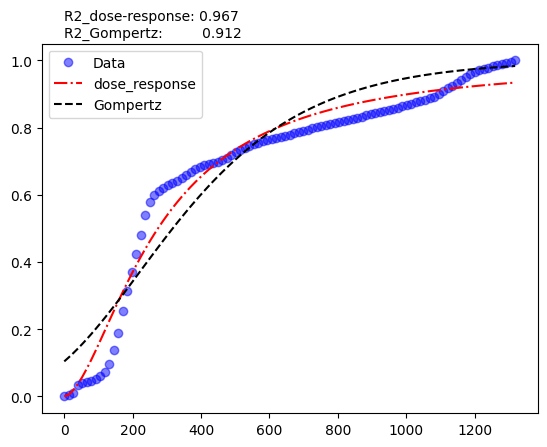

datapoint=  1
no=  2
The optimized parameters for dose-response are: [   3.866 1885.908]
The optimized parameters for Gompertz are: [ 749.893 1609.155]


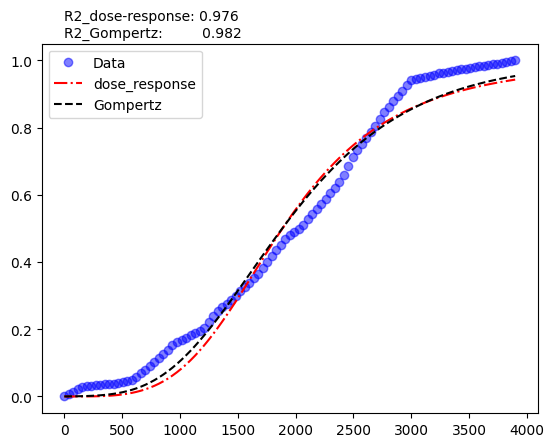

datapoint=  2
no=  3
The optimized parameters for dose-response are: [  2.165 582.503]
The optimized parameters for Gompertz are: [411.388 464.211]


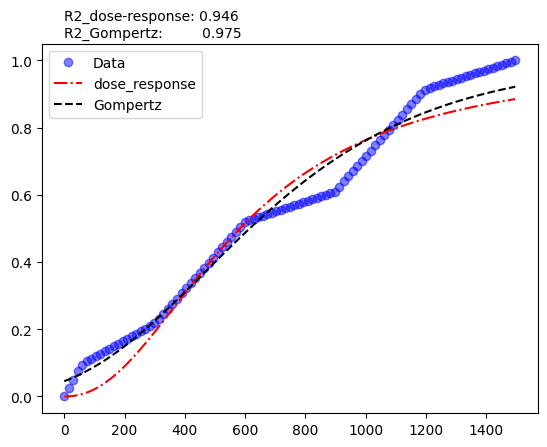

datapoint=  3
no=  4
The optimized parameters for dose-response are: [  2.14  690.176]
The optimized parameters for Gompertz are: [507.811 547.794]


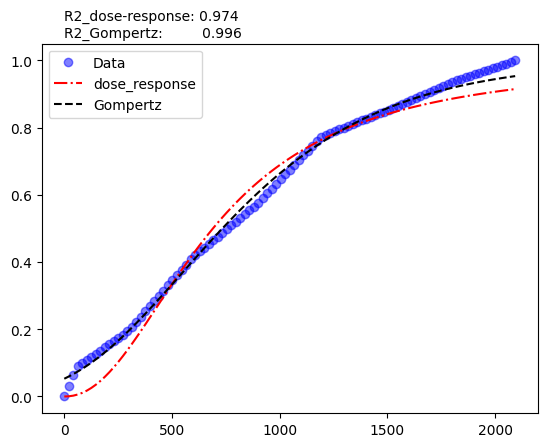

datapoint=  4
no=  5
The optimized parameters for dose-response are: [  1.775 842.165]
The optimized parameters for Gompertz are: [799.792 645.289]


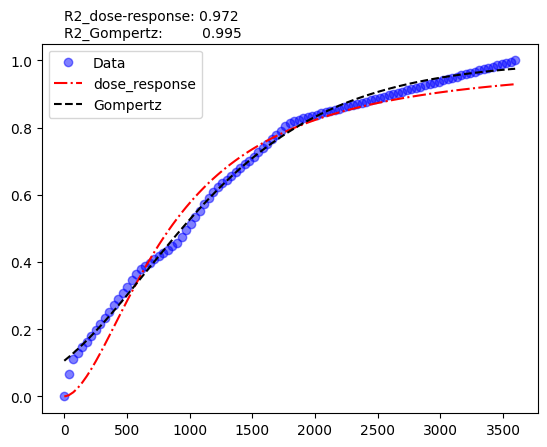

datapoint=  5
no=  6
The optimized parameters for dose-response are: [   3.326 1459.025]
The optimized parameters for Gompertz are: [ 681.021 1219.624]


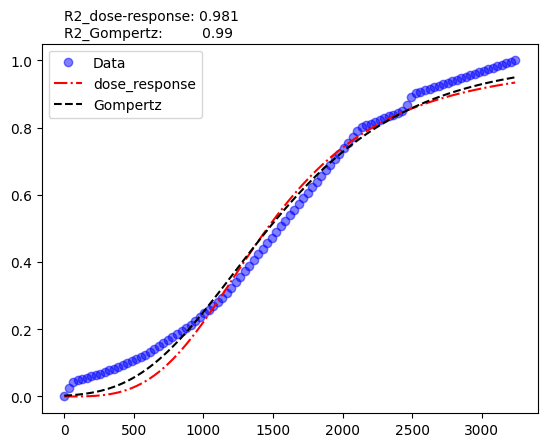

datapoint=  6
no=  7
The optimized parameters for dose-response are: [   2.18  1510.678]
The optimized parameters for Gompertz are: [1063.187 1215.686]


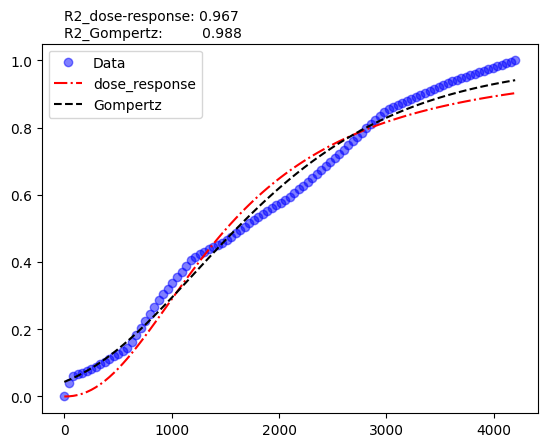

datapoint=  7
no=  8
The optimized parameters for dose-response are: [  3.426 774.246]
The optimized parameters for Gompertz are: [355.809 643.025]


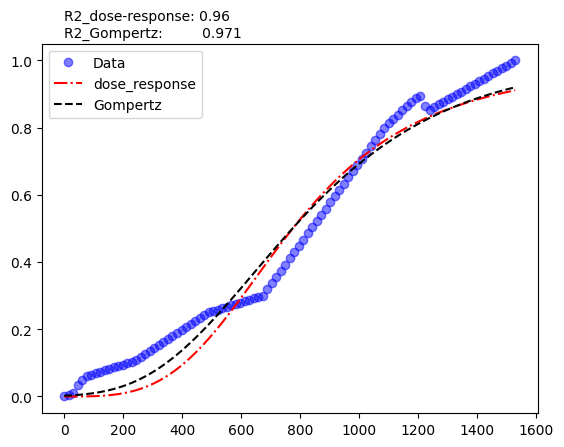

datapoint=  8
no=  9
The optimized parameters for dose-response are: [  1.241 497.237]
The optimized parameters for Gompertz are: [858.984 316.279]


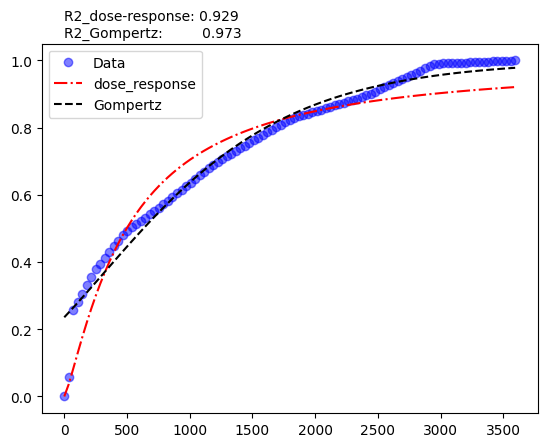

datapoint=  9
no=  10
The optimized parameters for dose-response are: [  1.564 248.588]
The optimized parameters for Gompertz are: [281.221 186.217]


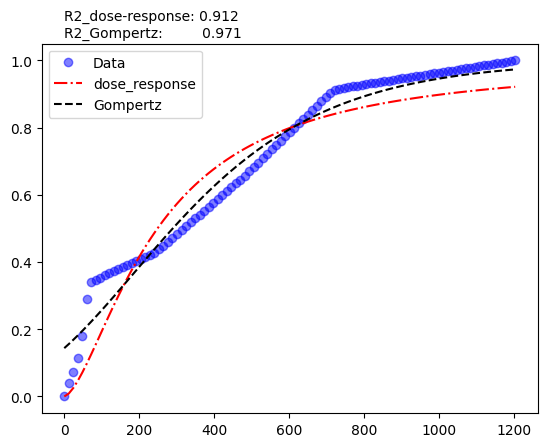

datapoint=  10
no=  11
The optimized parameters for dose-response are: [  2.519 415.669]
The optimized parameters for Gompertz are: [252.303 340.082]


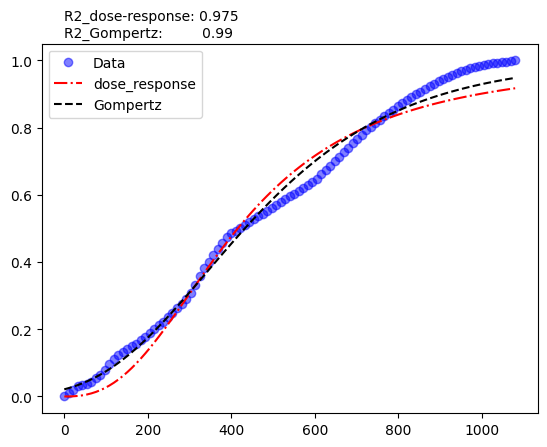

datapoint=  11
no=  12
The optimized parameters for dose-response are: [  2.629 385.368]
The optimized parameters for Gompertz are: [228.097 315.715]


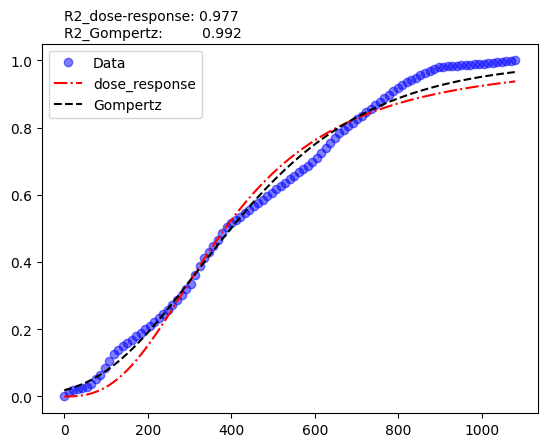

datapoint=  12
no=  13
The optimized parameters for dose-response are: [  2.648 336.369]
The optimized parameters for Gompertz are: [202.537 274.521]


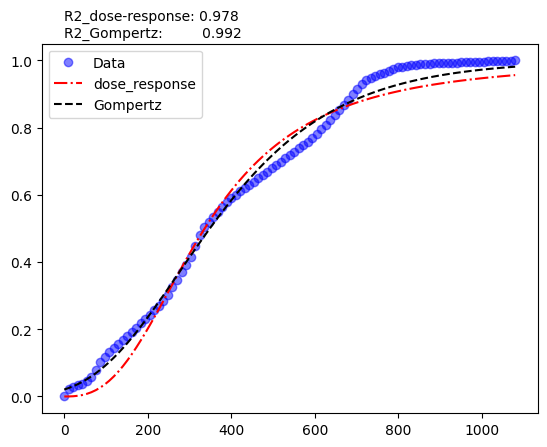

datapoint=  13
no=  14
The optimized parameters for dose-response are: [  2.956 510.579]
The optimized parameters for Gompertz are: [261.801 424.833]


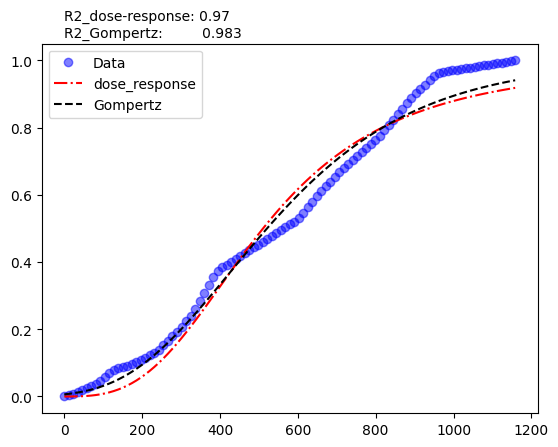

datapoint=  14
no=  15
The optimized parameters for dose-response are: [  2.881 484.459]
The optimized parameters for Gompertz are: [254.856 401.495]


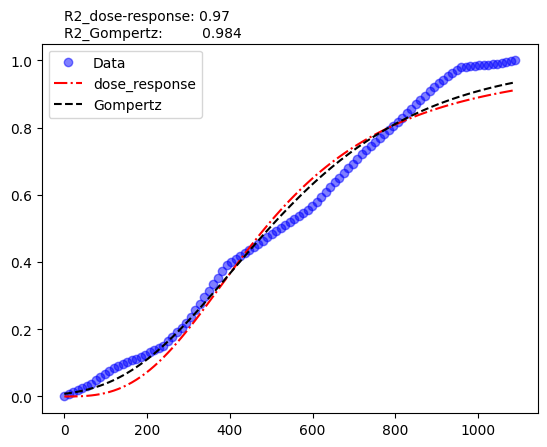

datapoint=  15
no=  16
The optimized parameters for dose-response are: [  2.657 420.858]
The optimized parameters for Gompertz are: [244.266 344.816]


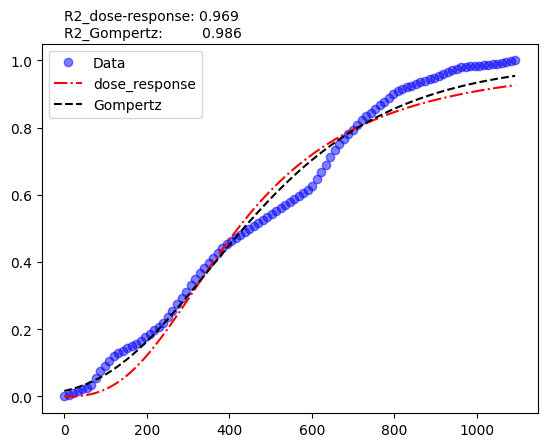

datapoint=  16
no=  17
The optimized parameters for dose-response are: [ 1.477 23.084]
The optimized parameters for Gompertz are: [17.266 19.684]


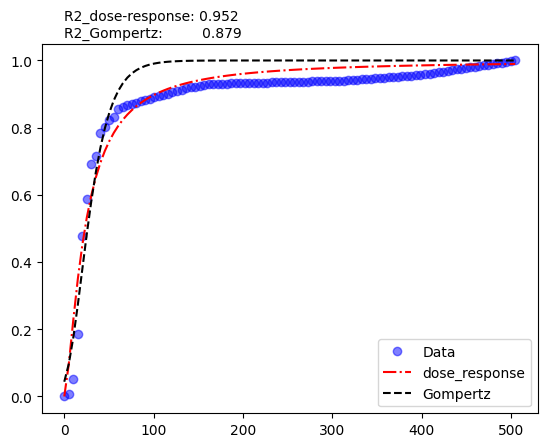

datapoint=  17
no=  18
The optimized parameters for dose-response are: [ 2.025 29.233]
The optimized parameters for Gompertz are: [19.921 24.373]


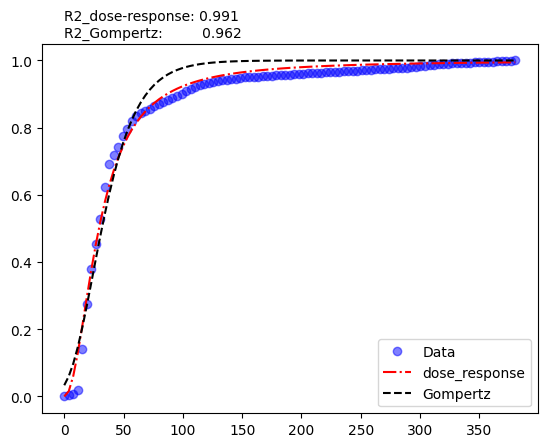

datapoint=  18
no=  19
The optimized parameters for dose-response are: [  2.696 243.07 ]
The optimized parameters for Gompertz are: [122.543 203.551]


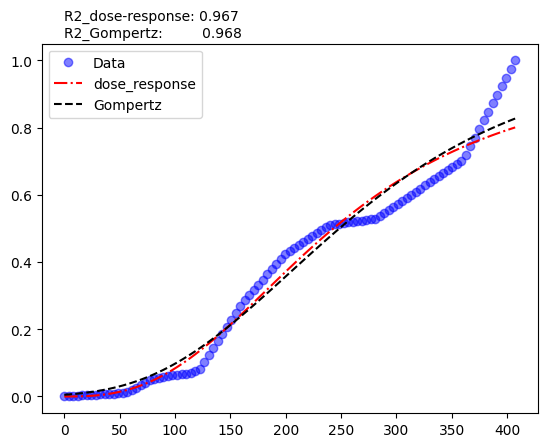

datapoint=  19
no=  20
The optimized parameters for dose-response are: [ 1.8   10.616]
The optimized parameters for Gompertz are: [9.562 8.504]


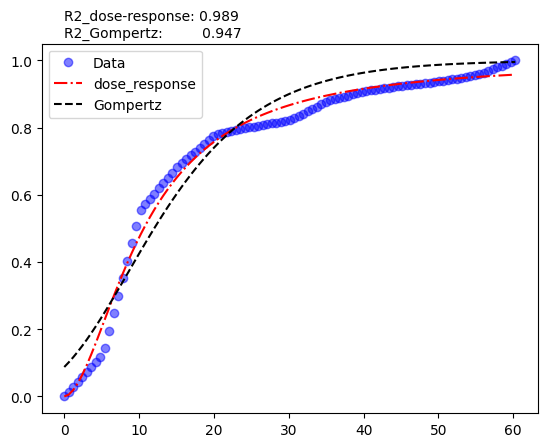

datapoint=  20
no=  21
The optimized parameters for dose-response are: [ 1.978 22.181]
The optimized parameters for Gompertz are: [17.094 18.287]


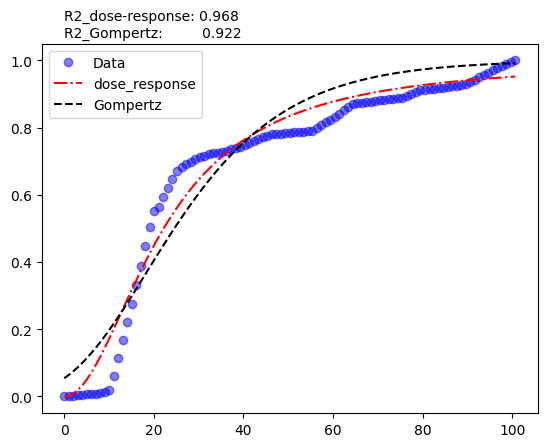

datapoint=  21
no=  22
The optimized parameters for dose-response are: [ 3.913 66.923]
The optimized parameters for Gompertz are: [25.469 58.028]


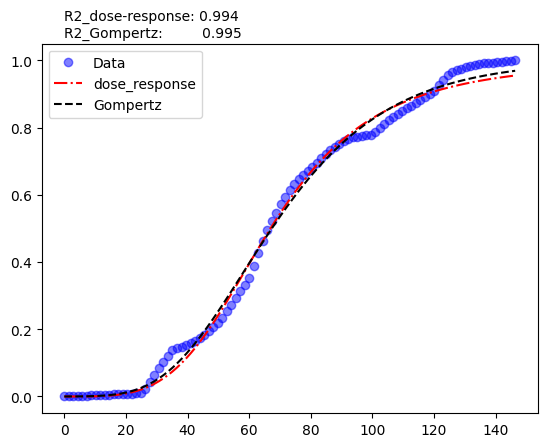

datapoint=  22
no=  23
The optimized parameters for dose-response are: [1.617 5.8  ]
The optimized parameters for Gompertz are: [6.385 4.44 ]


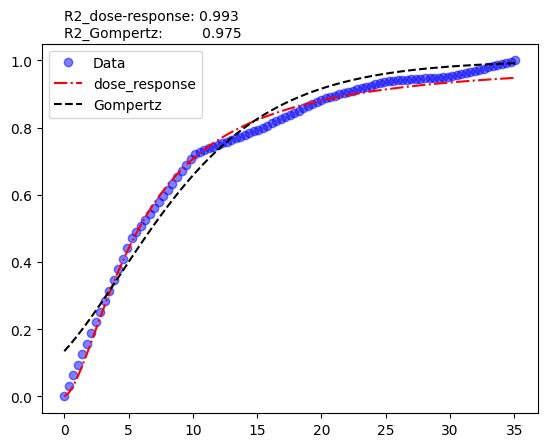

datapoint=  23
no=  24
The optimized parameters for dose-response are: [ 2.483 29.666]
The optimized parameters for Gompertz are: [17.972 24.818]


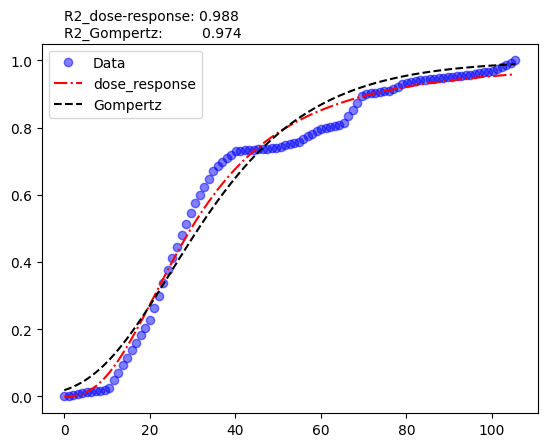

datapoint=  24
no=  25
The optimized parameters for dose-response are: [ 2.092 23.125]
The optimized parameters for Gompertz are: [17.663 18.865]


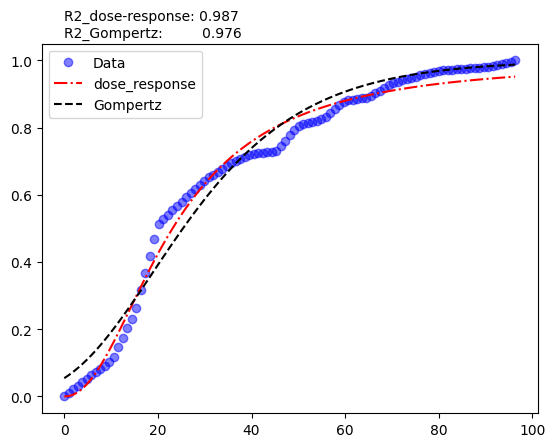

datapoint=  25
no=  26
The optimized parameters for dose-response are: [2.595 8.725]
The optimized parameters for Gompertz are: [4.989 7.284]


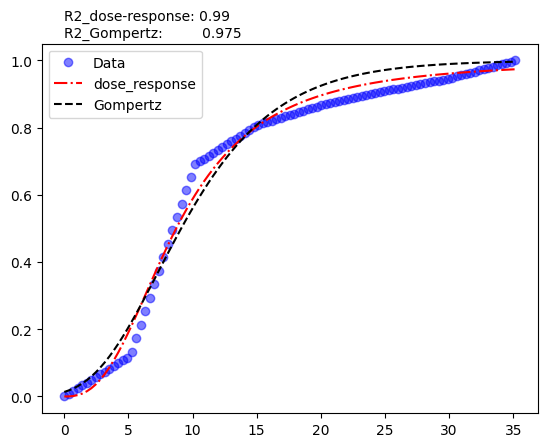

datapoint=  26
no=  27
The optimized parameters for dose-response are: [1.581 4.132]
The optimized parameters for Gompertz are: [4.833 3.109]


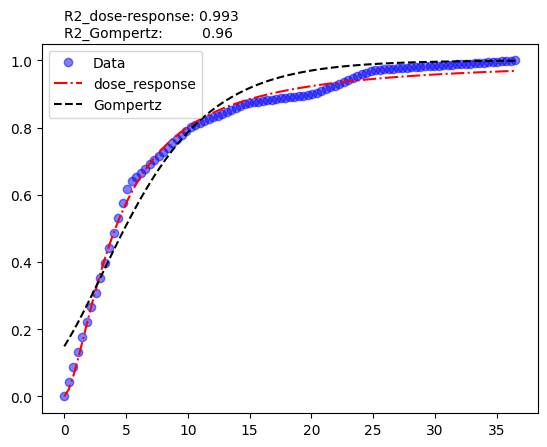

datapoint=  27
no=  28
The optimized parameters for dose-response are: [1.231 6.802]
The optimized parameters for Gompertz are: [12.451  4.102]


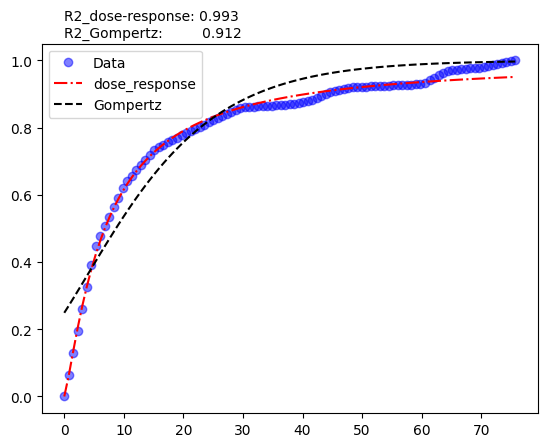

datapoint=  28
no=  29
The optimized parameters for dose-response are: [ 2.863 39.476]
The optimized parameters for Gompertz are: [20.655 33.239]


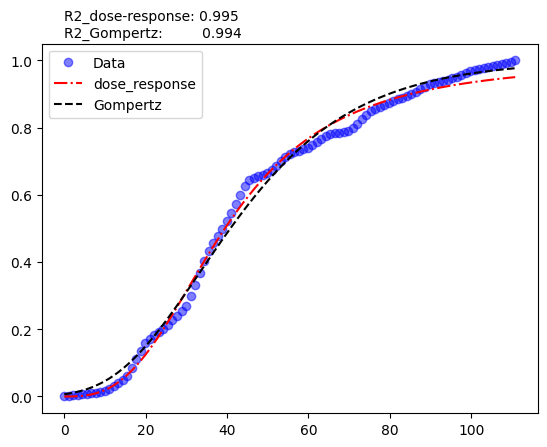

datapoint=  29
no=  30
The optimized parameters for dose-response are: [2.31  4.097]
The optimized parameters for Gompertz are: [2.875 3.284]


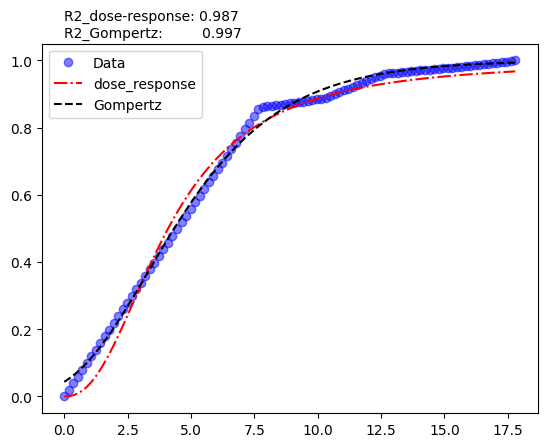

datapoint=  30
no=  31
The optimized parameters for dose-response are: [1.553 9.88 ]
The optimized parameters for Gompertz are: [11.432  7.514]


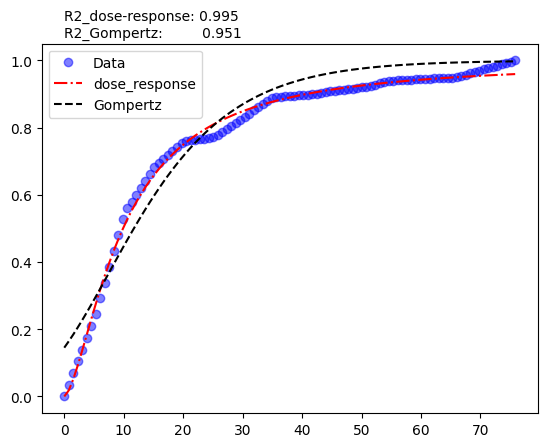

datapoint=  31
no=  32
The optimized parameters for dose-response are: [1.133 4.87 ]
The optimized parameters for Gompertz are: [11.077  2.244]


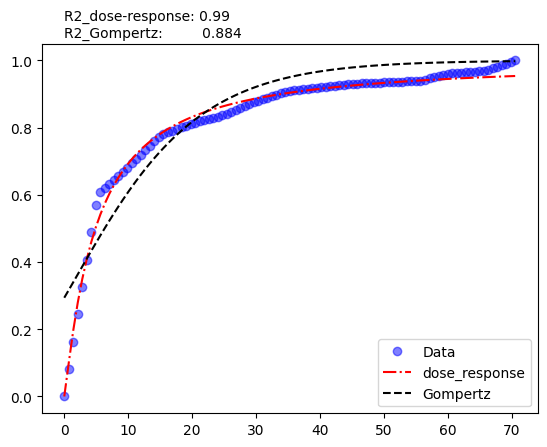

datapoint=  32
no=  33
The optimized parameters for dose-response are: [1.894 3.156]
The optimized parameters for Gompertz are: [2.757 2.494]


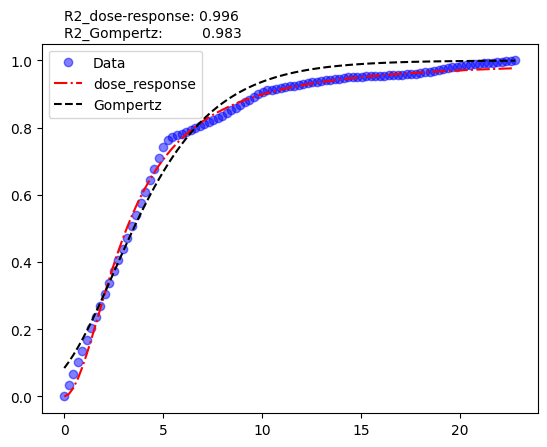

datapoint=  33
no=  34
The optimized parameters for dose-response are: [ 1.484 37.349]
The optimized parameters for Gompertz are: [45.573 28.131]


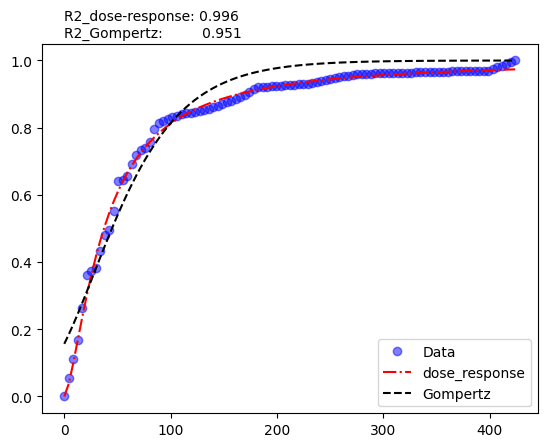

datapoint=  34
no=  35
The optimized parameters for dose-response are: [  1.586 129.852]
The optimized parameters for Gompertz are: [134.839 103.881]


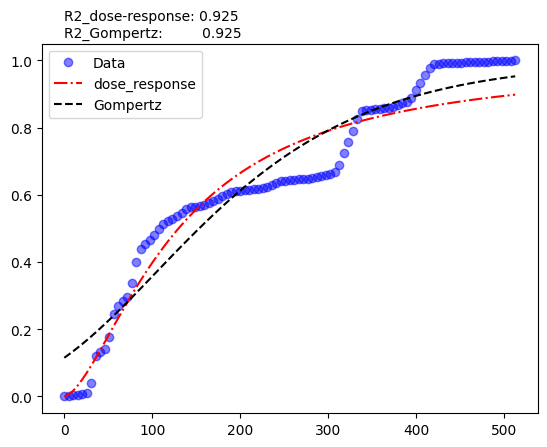

datapoint=  35
no=  36
The optimized parameters for dose-response are: [  7.072 409.215]
The optimized parameters for Gompertz are: [ 84.53  375.411]


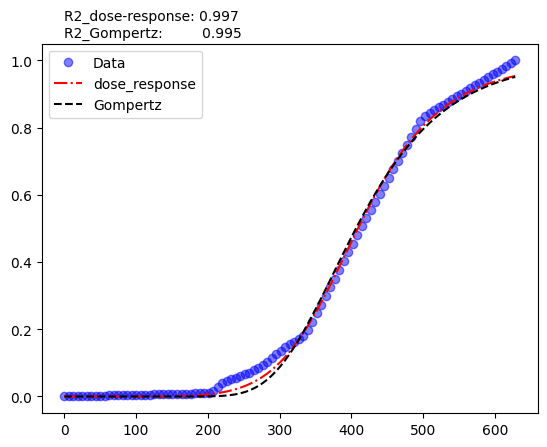

datapoint=  36
no=  38
The optimized parameters for dose-response are: [ 3.35  66.262]
The optimized parameters for Gompertz are: [28.627 56.948]


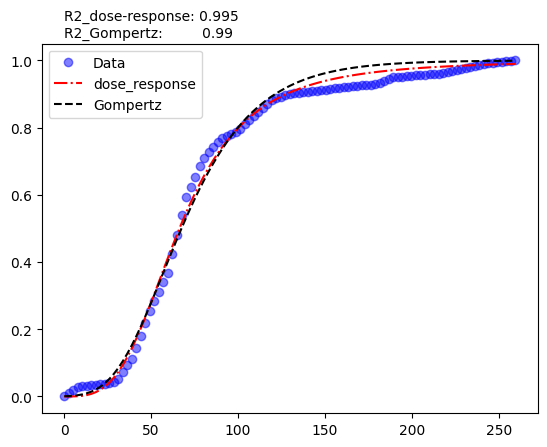

datapoint=  37
no=  39
The optimized parameters for dose-response are: [  7.173 496.18 ]
The optimized parameters for Gompertz are: [100.815 455.308]


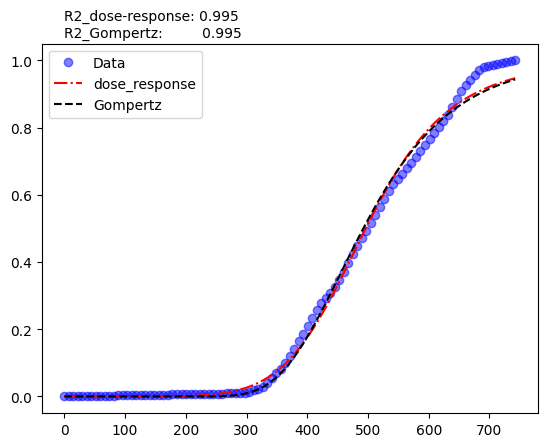

datapoint=  38
no=  40
The optimized parameters for dose-response are: [  8.134 578.59 ]
The optimized parameters for Gompertz are: [103.227 535.945]


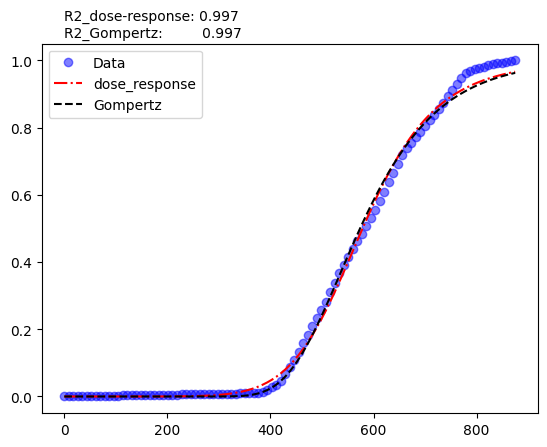

datapoint=  39
no=  41
The optimized parameters for dose-response are: [  8.827 704.384]
The optimized parameters for Gompertz are: [116.505 655.625]


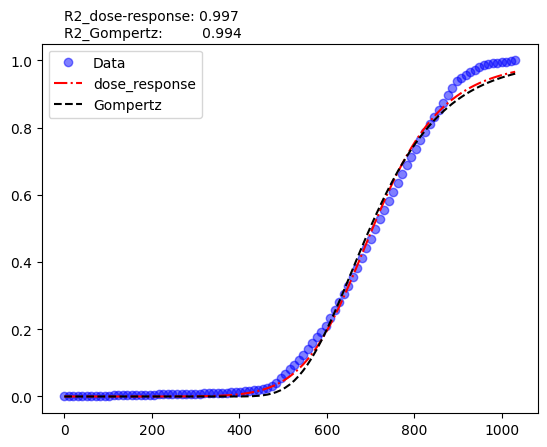

datapoint=  40
no=  42
The optimized parameters for dose-response are: [  7.2   803.428]
The optimized parameters for Gompertz are: [161.451 738.288]


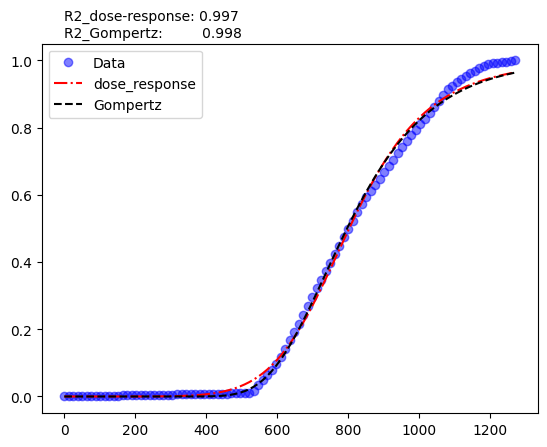

datapoint=  41
no=  43
The optimized parameters for dose-response are: [   6.166 1150.94 ]
The optimized parameters for Gompertz are: [ 271.36 1044.05]


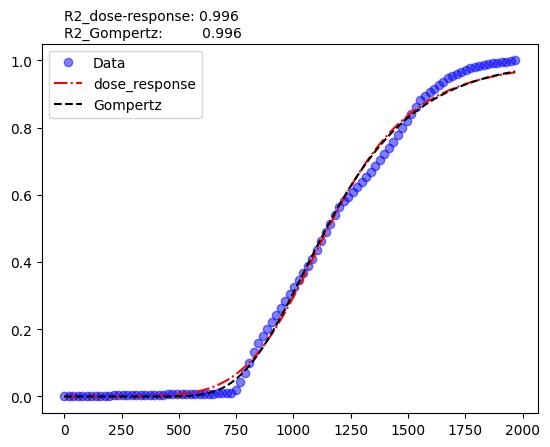

datapoint=  42
no=  44
The optimized parameters for dose-response are: [  9.554 385.49 ]
The optimized parameters for Gompertz are: [ 58.555 360.838]


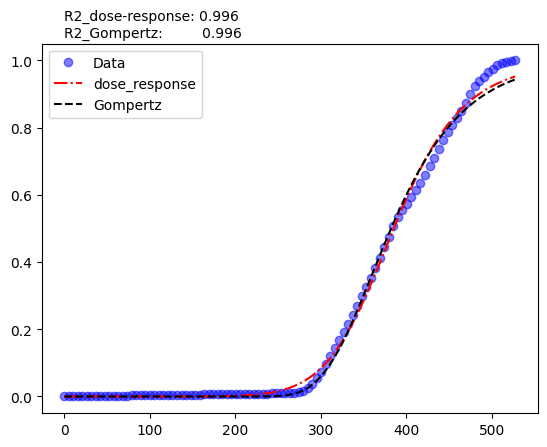

datapoint=  43
no=  45
The optimized parameters for dose-response are: [  6.67  240.344]
The optimized parameters for Gompertz are: [ 52.173 219.565]


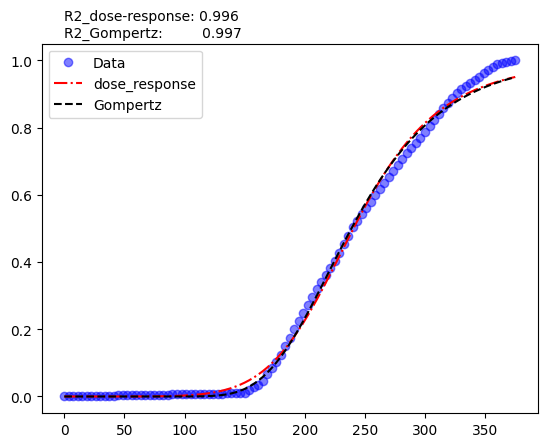

datapoint=  44
no=  46
The optimized parameters for dose-response are: [ 4.166 27.98 ]
The optimized parameters for Gompertz are: [ 8.834 24.811]


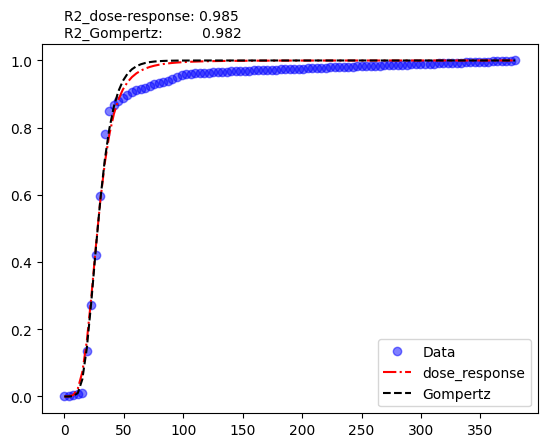

datapoint=  45
no=  47
The optimized parameters for dose-response are: [ 4.546 21.079]
The optimized parameters for Gompertz are: [ 5.76  18.918]


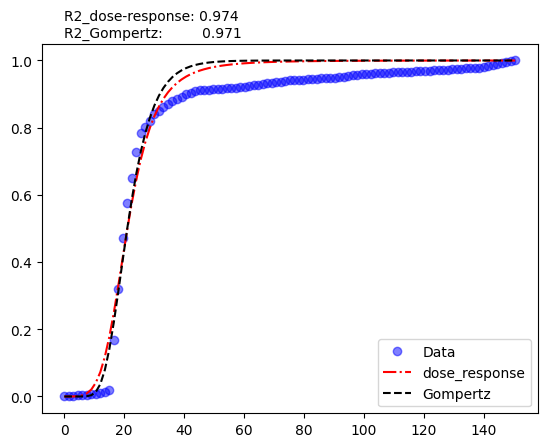

datapoint=  46
no=  48
The optimized parameters for dose-response are: [ 1.034 31.809]
The optimized parameters for Gompertz are: [27.055 33.616]


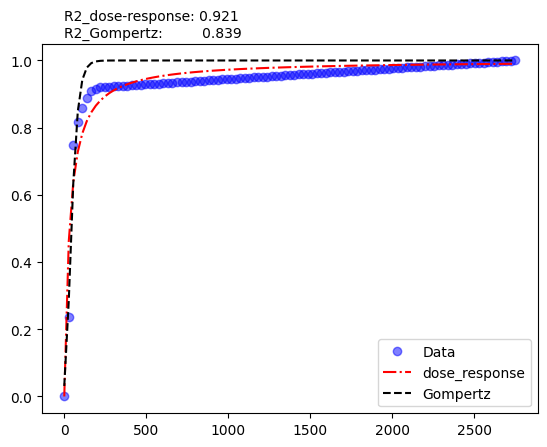

datapoint=  47
no=  49
The optimized parameters for dose-response are: [ 1.982 18.417]
The optimized parameters for Gompertz are: [12.179 15.385]


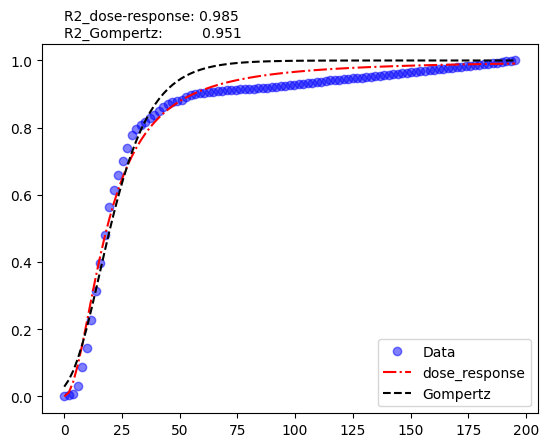

datapoint=  48
no=  50
The optimized parameters for dose-response are: [ 1.71  12.401]
The optimized parameters for Gompertz are: [ 8.186 10.534]


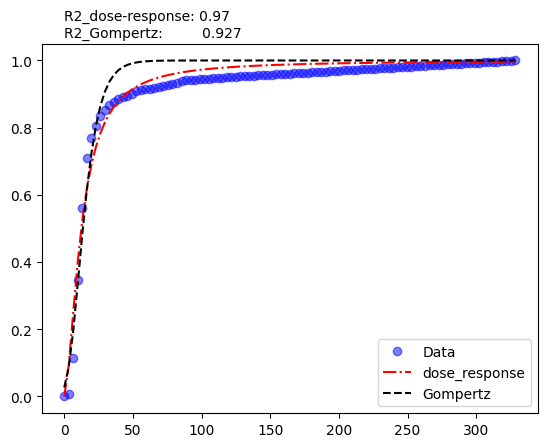

datapoint=  49
no=  51
The optimized parameters for dose-response are: [ 1.956 39.809]
The optimized parameters for Gompertz are: [21.734 34.38 ]


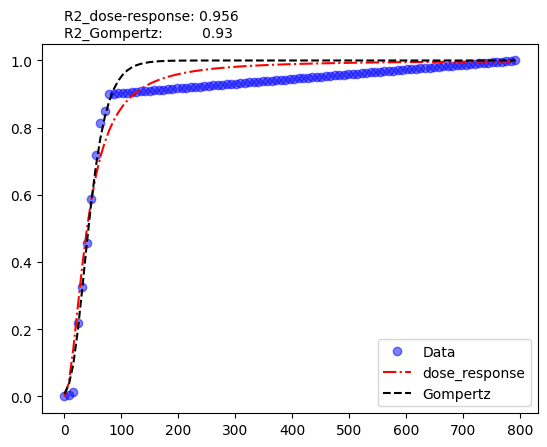

datapoint=  50
no=  52
The optimized parameters for dose-response are: [ 1.806 43.891]
The optimized parameters for Gompertz are: [24.89  37.902]


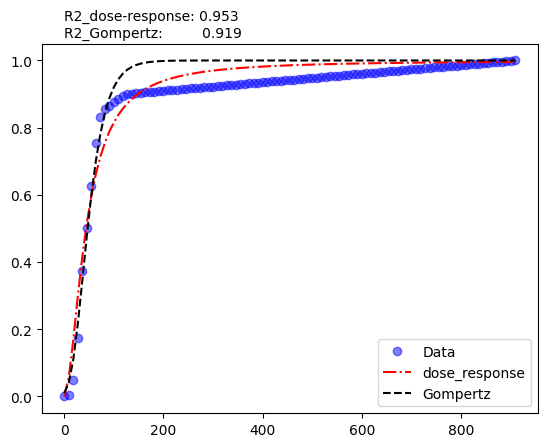

datapoint=  51
no=  53
The optimized parameters for dose-response are: [ 2.388 34.043]
The optimized parameters for Gompertz are: [19.374 28.731]


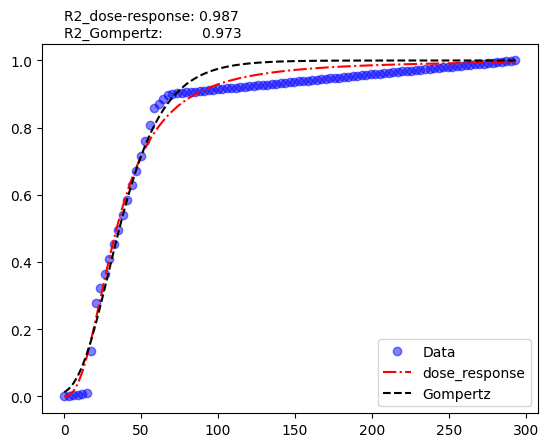

datapoint=  52
no=  54
The optimized parameters for dose-response are: [ 2.163 53.157]
The optimized parameters for Gompertz are: [28.    45.324]


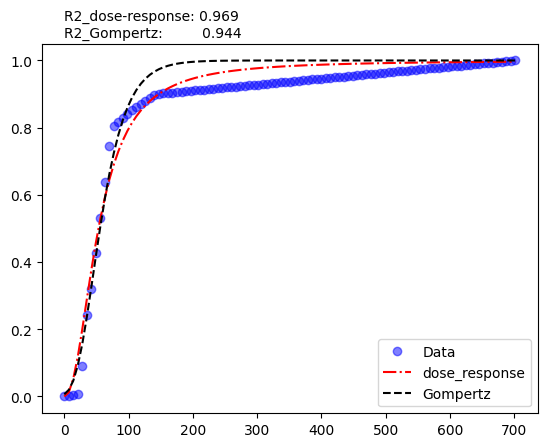

datapoint=  53
no=  55
The optimized parameters for dose-response are: [ 2.545 30.319]
The optimized parameters for Gompertz are: [18.627 24.812]


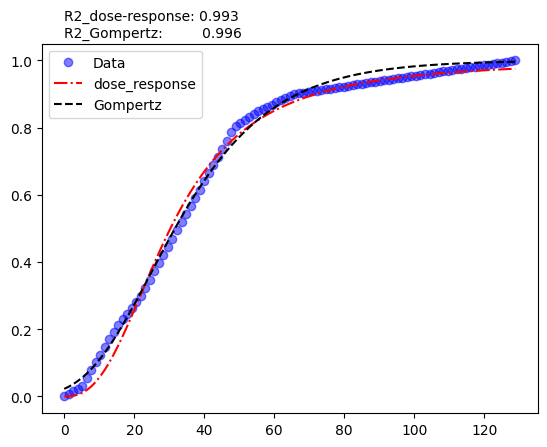

datapoint=  54
no=  56
The optimized parameters for dose-response are: [ 2.348 33.568]
The optimized parameters for Gompertz are: [19.494 28.3  ]


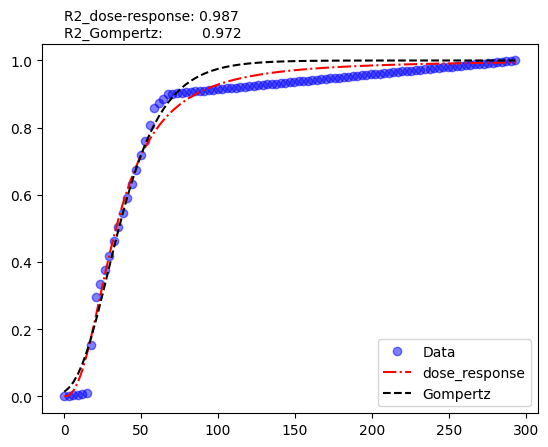

datapoint=  55
no=  57
The optimized parameters for dose-response are: [ 1.736 23.57 ]
The optimized parameters for Gompertz are: [22.659 18.63 ]


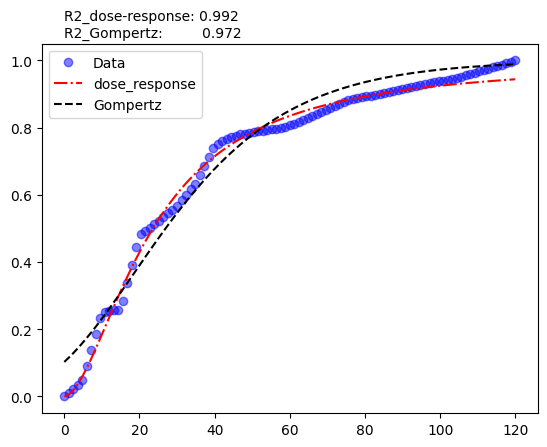

datapoint=  56
no=  58
The optimized parameters for dose-response are: [ 2.707 54.815]
The optimized parameters for Gompertz are: [32.544 43.963]


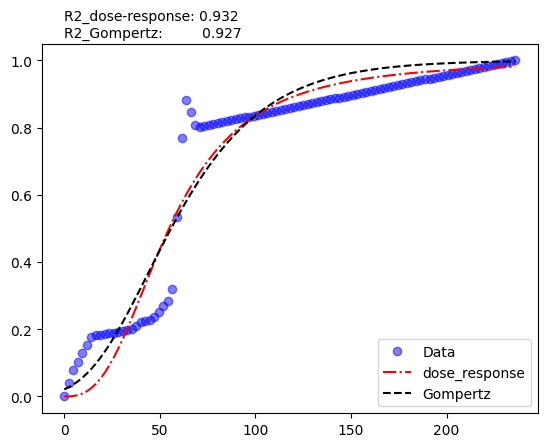

datapoint=  57
no=  59
The optimized parameters for dose-response are: [ 2.515 30.216]
The optimized parameters for Gompertz are: [18.843 24.676]


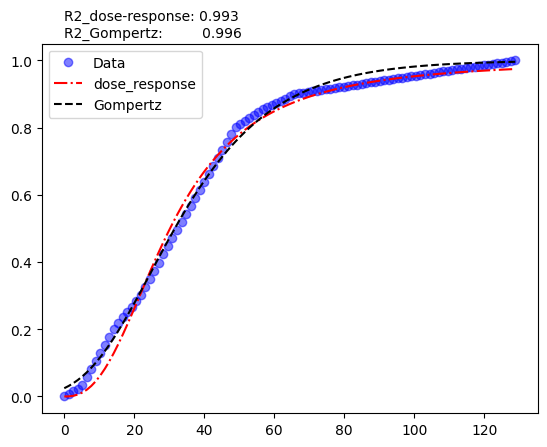

datapoint=  58
no=  60
The optimized parameters for dose-response are: [   3.903 2003.772]
The optimized parameters for Gompertz are: [ 759.549 1735.161]


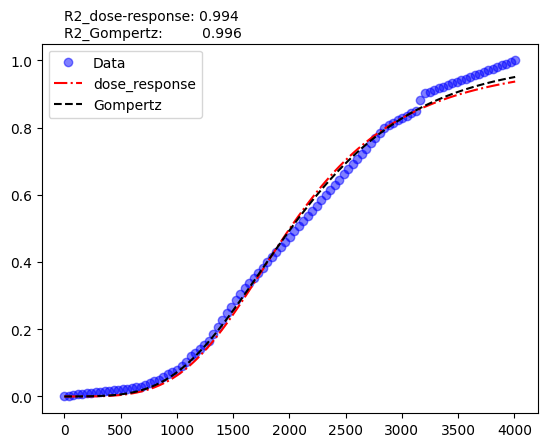

datapoint=  59
no=  61
The optimized parameters for dose-response are: [ 3.992 32.944]
The optimized parameters for Gompertz are: [12.824 28.111]


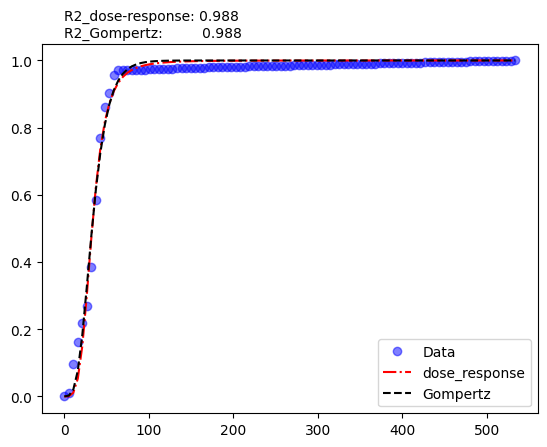

datapoint=  60
no=  62
The optimized parameters for dose-response are: [ 4.362 40.038]
The optimized parameters for Gompertz are: [13.624 34.999]


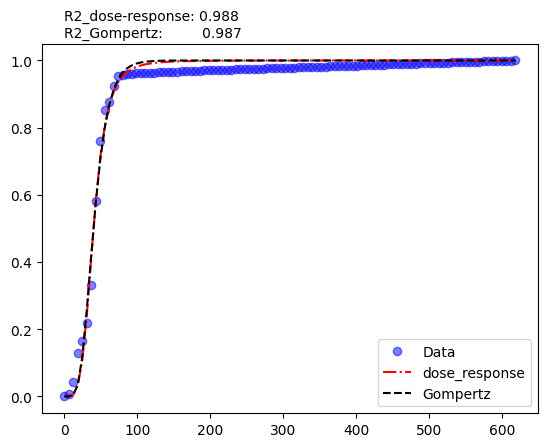

datapoint=  61
no=  63
The optimized parameters for dose-response are: [ 3.203 58.216]
The optimized parameters for Gompertz are: [25.675 49.722]


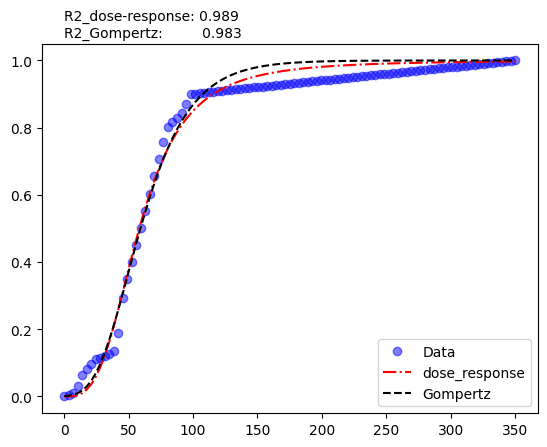

datapoint=  62
no=  64
The optimized parameters for dose-response are: [ 4.75  36.628]
The optimized parameters for Gompertz are: [12.025 31.906]


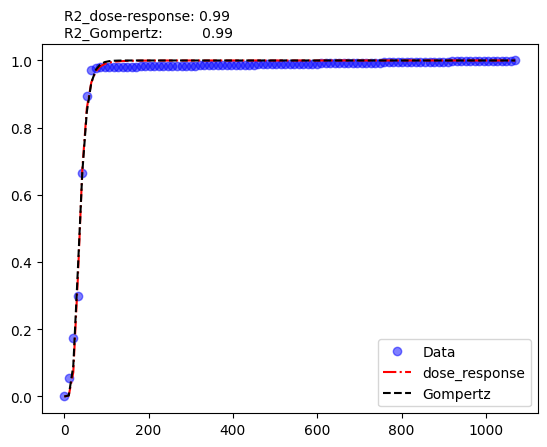

datapoint=  63
no=  65
The optimized parameters for dose-response are: [ 5.437 40.456]
The optimized parameters for Gompertz are: [11.208 36.123]


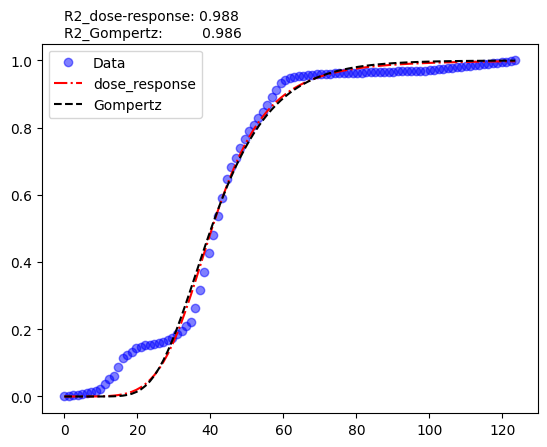

datapoint=  64
no=  66
The optimized parameters for dose-response are: [ 5.56  57.561]
The optimized parameters for Gompertz are: [16.22  50.852]


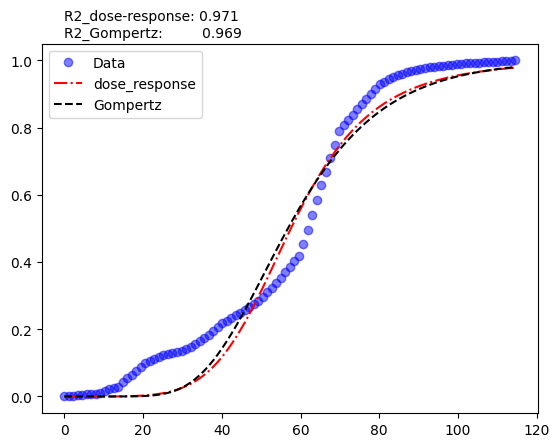

datapoint=  65
no=  67
The optimized parameters for dose-response are: [ 5.024 51.362]
The optimized parameters for Gompertz are: [16.202 44.744]


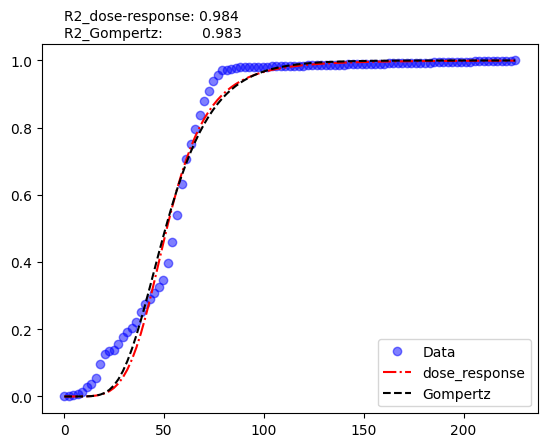

datapoint=  66
no=  68
The optimized parameters for dose-response are: [  1.066 151.845]
The optimized parameters for Gompertz are: [436.535  36.527]


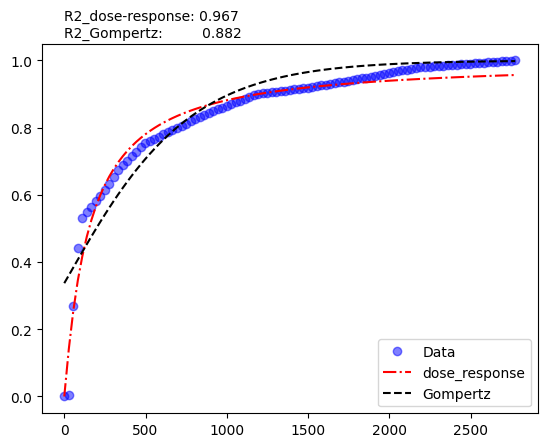

datapoint=  67
no=  69
The optimized parameters for dose-response are: [  1.336 465.632]
The optimized parameters for Gompertz are: [715.064 329.328]


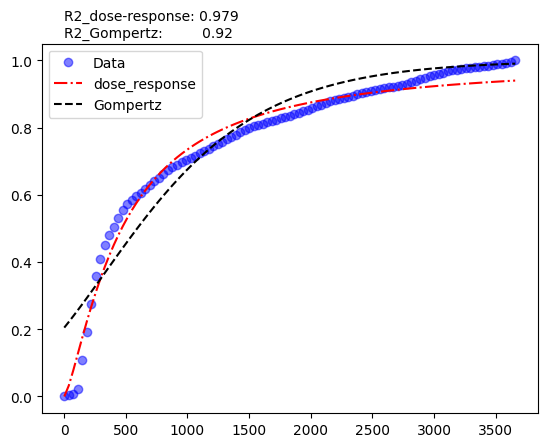

datapoint=  68
no=  70
The optimized parameters for dose-response are: [   3.159 1939.044]
The optimized parameters for Gompertz are: [ 896.385 1648.912]


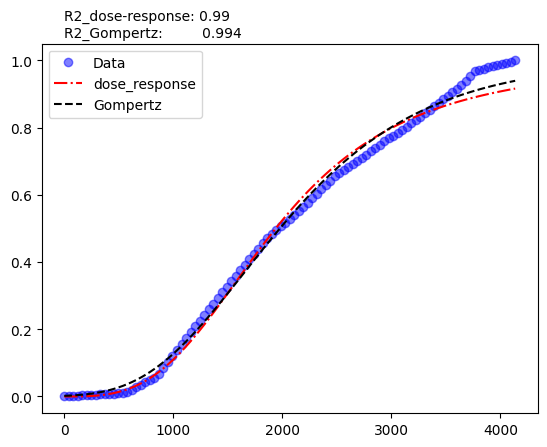

datapoint=  69
no=  71
The optimized parameters for dose-response are: [  5.824 382.183]
The optimized parameters for Gompertz are: [ 97.253 344.07 ]


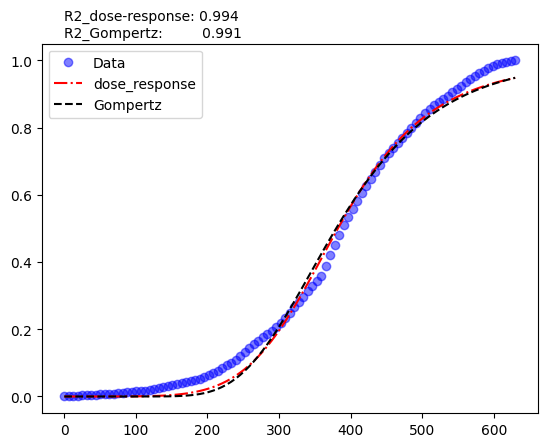

datapoint=  70
no=  72
The optimized parameters for dose-response are: [  5.015 353.167]
The optimized parameters for Gompertz are: [104.358 313.388]


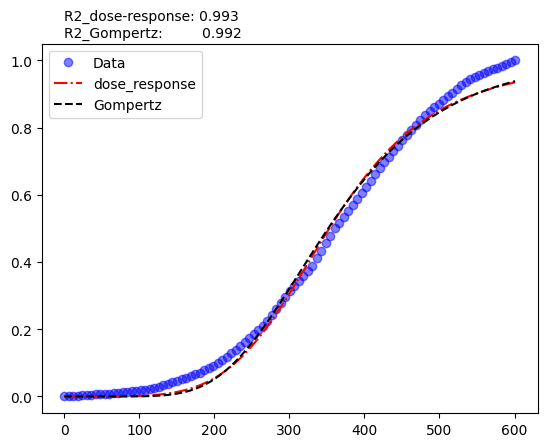

datapoint=  71
no=  73
The optimized parameters for dose-response are: [  3.68  156.115]
The optimized parameters for Gompertz are: [ 63.005 134.773]


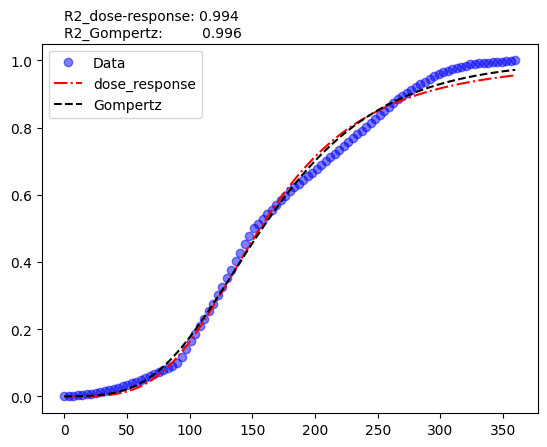

datapoint=  72
no=  74
The optimized parameters for dose-response are: [  5.999 467.316]
The optimized parameters for Gompertz are: [116.162 420.993]


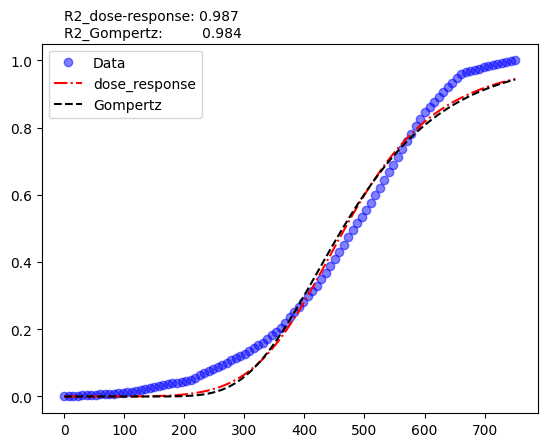

datapoint=  73
no=  75
The optimized parameters for dose-response are: [  4.714 258.421]
The optimized parameters for Gompertz are: [ 79.422 229.485]


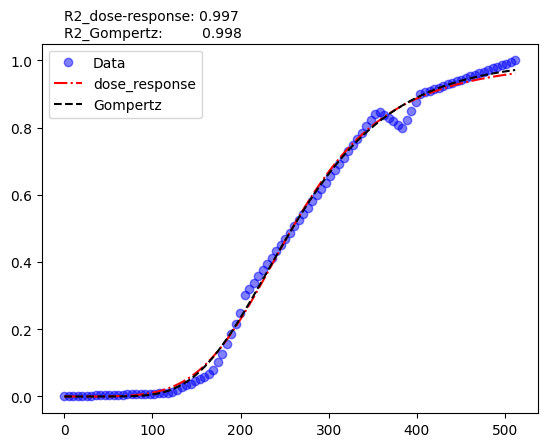

datapoint=  74
no=  76
The optimized parameters for dose-response are: [  5.292 328.245]
The optimized parameters for Gompertz are: [ 89.132 294.651]


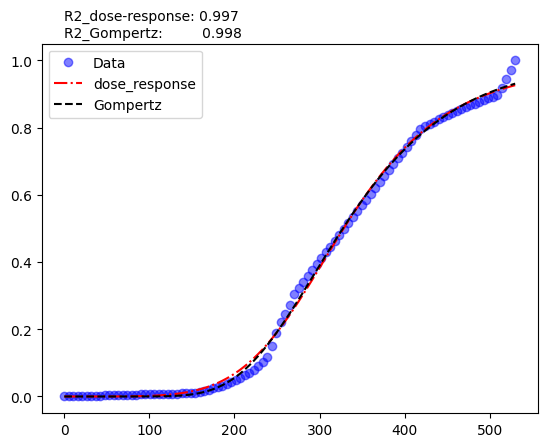

datapoint=  75
no=  77
The optimized parameters for dose-response are: [ 1.933 43.931]
The optimized parameters for Gompertz are: [21.712 37.738]


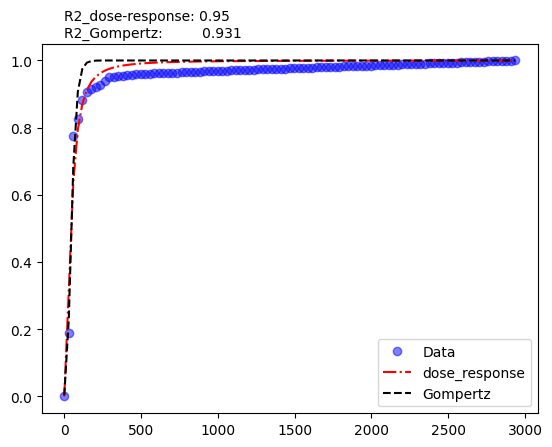

datapoint=  76
no=  78
The optimized parameters for dose-response are: [ 3.456 18.668]
The optimized parameters for Gompertz are: [ 7.425 16.203]


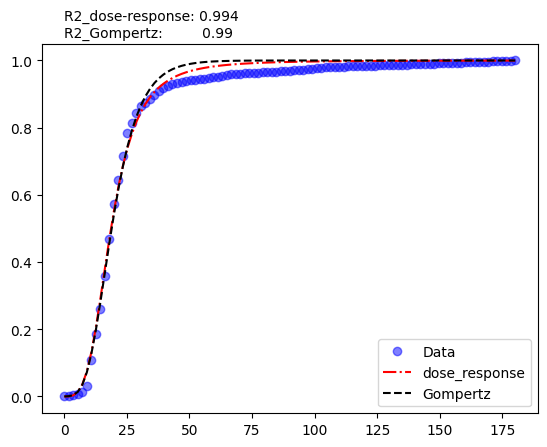

datapoint=  77
no=  79
The optimized parameters for dose-response are: [ 5.214 14.438]
The optimized parameters for Gompertz are: [ 3.901 12.997]


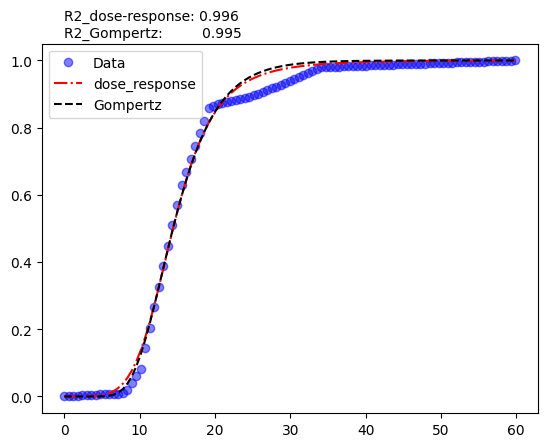

datapoint=  78
no=  80
The optimized parameters for dose-response are: [ 4.698 14.009]
The optimized parameters for Gompertz are: [ 4.213 12.496]


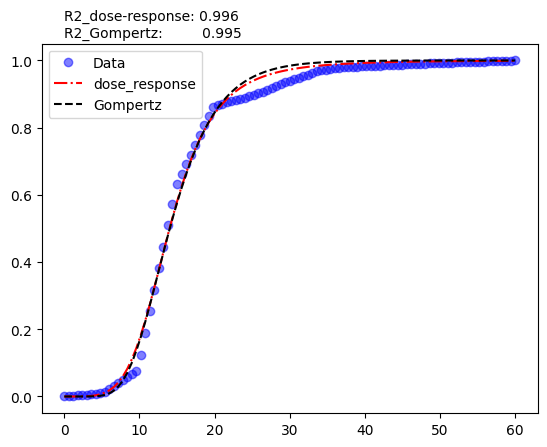

datapoint=  79
no=  81
The optimized parameters for dose-response are: [3.862 3.324]
The optimized parameters for Gompertz are: [1.211 2.904]


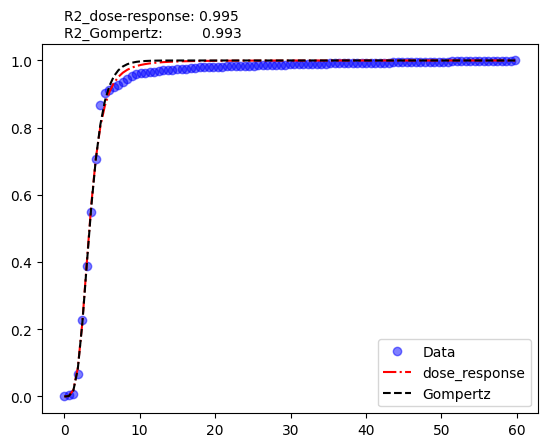

datapoint=  80
no=  82
The optimized parameters for dose-response are: [0.623 0.281]
The optimized parameters for Gompertz are: [1.668 2.725]


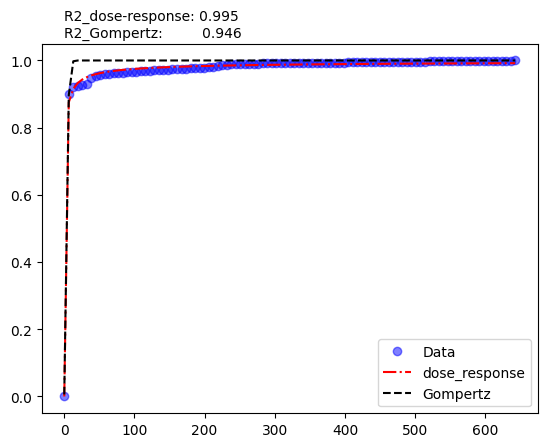

datapoint= 

 81
no=  83
The optimized parameters for dose-response are: [2.3   3.687]
The optimized parameters for Gompertz are: [2.177 3.051]


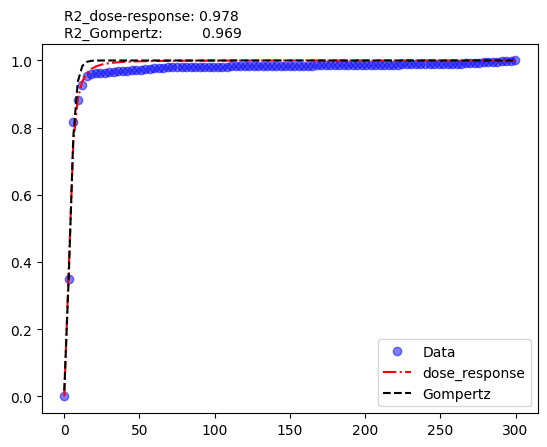

datapoint=  82
no=  84
The optimized parameters for dose-response are: [0.454 0.287]
The optimized parameters for Gompertz are: [1.843 2.366]


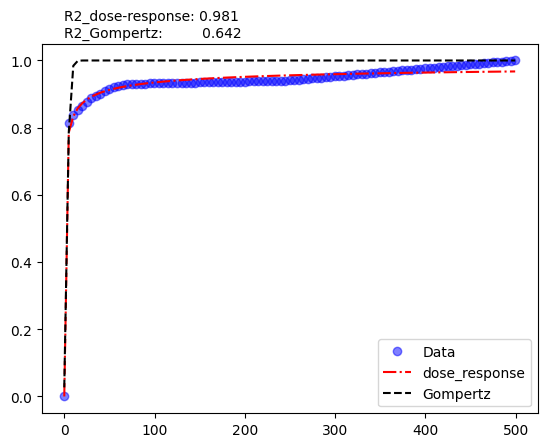

datapoint=  83
no=  85
The optimized parameters for dose-response are: [0.485 0.103]
The optimized parameters for Gompertz are: [1.431 2.321]


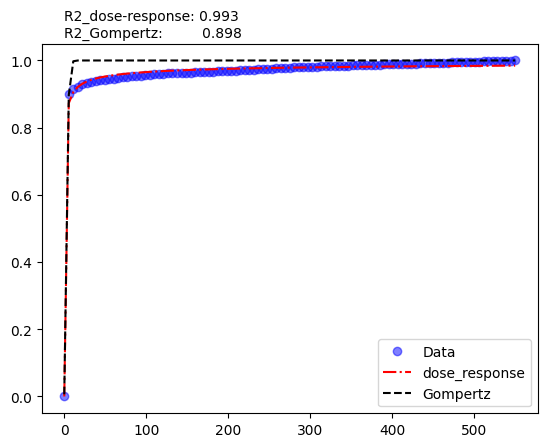

In [32]:

#-------------------------------------------------------------
data={'a': [], 'b':[], 'K': [], 'T':[], 'R2_dose-response': [], 'R2-Gompertz': []}
Coefficent_data = pd.DataFrame(data)
#-------------------------------------------------------------
for i in range(0,df.shape[0]):
    # Define the model equation to fit to the data


    # Generate some sample data
    x_data = np.asanyarray(df['Modified_BC'].iloc[i]['t'])
    y_data = np.asanyarray(df['Modified_BC'].iloc[i]['C'])

#---------------------------------------------------------------------
# Define the number of points to interpolate
    num_interp_points = 101

# Create a new array of x values with the desired number of points
    x_interp = np.linspace(x_data.min(), x_data.max(), num=num_interp_points)

# Create an interpolation function for the y values
    interp_func = interp1d(x_data, y_data, kind='linear')

# Interpolate the y values at the new x values
    y_interp = interp_func(x_interp)
#----------------------------------------------------------------------------------

# Fit the model equation to the data
    popt_dr, pcov_dr = curve_fit(dose_response, x_interp, y_interp, bounds=[0,100000000], method='trf', p0 =[1, x_interp[np.argmin(abs(y_interp-0.5))]])
#    popt_clark, pcov_clark = curve_fit(Clark, x_interp, y_interp,  bounds=[0,10000000], method='trf', p0 =[1,0.5])
    popt_gompertz, pcov_gompertz = curve_fit(Gompertz, x_interp, y_interp, bounds=[0,100000000], method='trf', p0 =[0.1*x_interp[np.argmin(abs(y_interp-0.5))], x_interp[np.argmin(abs(y_interp-0.5))]])
    
    #Calculate the r2 score
    R2_dr= r2_score(y_interp, dose_response(x_interp, *popt_dr))
#    R2_clark= r2_score(y_interp, Clark(x_interp, *popt_clark))
    R2_gompertz= r2_score(y_interp, Gompertz(x_interp, *popt_gompertz))
    
    # Add a new row to the DataFrame
    new_row = {'a': popt_dr[0], 'b': popt_dr[1],
               'K': popt_gompertz[0], 'T': popt_gompertz[1],
              'R2_dose-response': R2_dr,  'R2-Gompertz': R2_gompertz}
    Coefficent_data.loc[len(Coefficent_data)] = new_row
    #Calculate the r2 score
    R2_dr= r2_score(y_interp, dose_response(x_interp, *popt_dr))
#    R2_clark= r2_score(y_interp, Clark(x_interp, *popt_clark))
    R2_gompertz= r2_score(y_interp, Gompertz(x_interp, *popt_gompertz))
    
# Print the optimized parameters
    print('datapoint= ', i)
    print('no= ', df['no'].iloc[i])
    print(f"The optimized parameters for dose-response are: {popt_dr.round(3)}")
#    print(f"The optimized parameters for clark are: {popt_clark.round(3)}")
    print(f"The optimized parameters for Gompertz are: {popt_gompertz.round(3)}")


# Plot the data and the fitted equation
    plt.plot(x_interp, y_interp, 'bo', label='Data', alpha=0.5)
    plt.plot(x_interp, dose_response(x_interp, *popt_dr), 'r-.', label='dose_response')
#    plt.plot(x_interp, Clark(x_interp, *popt_clark), 'g-', label='Clark') 
    plt.plot(x_interp, Gompertz(x_interp, *popt_gompertz), 'k--', label='Gompertz') 
    plt.text(x_data.max()*0.00, 1.12,  ('R2_dose-response: ' + str(round(R2_dr, 3))))
#    plt.text(x_data.max()*0.00,1.15,  ('R2_Clark:                ' + str(round(R2_clark, 3))))
    plt.text(x_data.max()*0.00, 1.07,  ('R2_Gompertz:         ' + str(round(R2_gompertz, 3))))
    plt.legend()
    picname= 'Data Fitting/'+str(df['no'].iloc[i]) + ' no' + str(i)
    plt.savefig(picname, dpi=50)
    plt.show()

---
# Step 2 — Gompertz model parameter prediction (T and K)

In [33]:
import pandas as pd
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from xgboost import XGBRegressor as XGBR
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import GradientBoostingRegressor as GBR
from sklearn.ensemble import RandomForestRegressor as RF
from sklearn.neighbors import KNeighborsRegressor as KNN
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression
import math
import shap
import joblib
import mlxtend
from mlxtend.feature_selection import ExhaustiveFeatureSelector
from sklearn.preprocessing import MinMaxScaler
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

In [34]:
mdf = pd.read_pickle("df_coeff.pkl")
mdf = mdf.reset_index()
mdf=mdf.drop('index', axis=1)

In [35]:
fontdict1={'fontsize': 12, 'fontweight': 'bold', 'fontfamily': 'arial'}
fontdict2={'fontsize': 12, 'fontweight': 'bold', 'fontstyle': 'oblique', 'color': 'b', 'fontfamily': 'arial'}

In [36]:
mdf= mdf[['ph_sol', 'initial_concentration', 'flowrate', 'pyrolysis_temp', 'pyrolysis_time',
            'S_Bet', 'particle_size', 'bc_weight', 'col_d', 'col_h', 'a', 'b', 'K', 'T']]
Features= mdf[['ph_sol', 'initial_concentration', 'flowrate', 'pyrolysis_temp', 'pyrolysis_time',
            'S_Bet', 'particle_size', 'bc_weight', 'col_d', 'col_h']]
Target= mdf[['a', 'b', 'K', 'T']]
df=mdf[['ph_sol', 'initial_concentration', 'flowrate', 'pyrolysis_temp', 'pyrolysis_time',
            'S_Bet', 'particle_size', 'bc_weight', 'col_d', 'col_h', 'a', 'b', 'K', 'T']]
df = df.rename(columns={'ph_sol': 'pH'})
df = df.rename(columns={'initial_concentration': 'InitC'})
df = df.rename(columns={'flowrate': 'FlowR'})
df = df.rename(columns={'pyrolysis_temp': 'PTemp'})
df = df.rename(columns={'pyrolysis_time': 'PTime'})
df = df.rename(columns={'S_Bet': 'SBet'})
df = df.rename(columns={'particle_size': 'PSize'})
df = df.rename(columns={'bc_weight': 'SW'})
df = df.rename(columns={'col_d': 'ColD'})
df = df.rename(columns={'col_h': 'ColH'})
#df['K']=1/df['K']

In [37]:
Results_df=df.copy().round(3)

In [38]:
Results_df.head(5)

,pH,InitC,FlowR,PTemp,PTime,SBet,PSize,SW,ColD,ColH,a,b,K,T
0,6.0,50.0,1.207,600.0,60.0,154.25,0.25,0.3,16.998,38.733,1.688,273.903,268.301,218.663
1,6.0,50.0,0.600,600.0,60.0,170.34,0.25,0.3,17.816,38.680,3.866,1885.908,749.893,1609.155
2,3.0,50.0,0.846,600.0,60.0,170.34,0.25,0.3,30.367,27.083,2.165,582.503,411.388,464.211
3,4.0,50.0,0.846,600.0,60.0,170.34,0.25,0.3,30.367,27.083,2.140,690.176,507.811,547.794
4,5.0,50.0,0.846,600.0,60.0,170.34,0.25,0.3,30.367,27.083,1.775,842.165,799.792,645.289


In [39]:
from docx import Document
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.shared import Pt

doc = Document()
table = doc.add_table(Results_df.shape[0] + 1, Results_df.shape[1])
table.alignment = WD_ALIGN_PARAGRAPH.CENTER  # Center-align the table

# Set column widths (optional)
for cell in table.rows[0].cells:
    cell.width = Pt(100)  # Adjust the width as needed

# Add column headers
for i, column_name in enumerate(Results_df.columns):
    table.cell(0, i).text = column_name

# Add data to the table
for i in range(Results_df.shape[0]):
    for j in range(Results_df.shape[1]):
        table.cell(i + 1, j).text = str(Results_df.iloc[i, j])

# Save the document
doc.save('dataframe_table.docx')

# Determining T

# XGBR

In [40]:
# ===== Hyperparameter optimisation: T: XGBR =====
DEFAULTS['T_XGBR'] = dict(learning_rate =0.012, n_estimators=300, reg_alpha=0.071, reg_lambda=0.040, max_depth =7, random_state =7, tree_method='exact', base_score=0.5)   # original values (hand-set by the authors)
_X = df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW', 'ColD', 'ColH']]
_y = df['T']
_Xtr, _Xte, _ytr, _yte = train_test_split(_X, _y, test_size=0.15, random_state=71)   # same split as the training cell below
tune('T_XGBR', XGBR, 'xgb', _Xtr, _ytr)

[T_XGBR] saved tuned hyperparameters re-used   CV r2: original -1.080 -> tuned 0.109
          {'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 6, 'min_child_weight': 1, 'n_estimators': 100, 'reg_alpha': 1.0, 'reg_lambda': 0.1, 'subsample': 0.8}


In [41]:

X= df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW', 'ColD', 'ColH']]
y=df['T']
#-------------------------------------------------------------------------------------------------------------

for rs in [71]:                   # 19 71 248
    print('Random State: ', rs)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = rs) # Split the data



# Train the model on the training set

    est=XGBR(**hp('T_XGBR'))   # hyperparameters: see the tuning cell above
    est.fit(X_train, y_train)

# Make predictions on the testing set
    y_pred_test = est.predict(X_test).round(2)
    y_pred_train = est.predict(X_train).round(2)
    
       
    r2_a_train = r2_score(y_train, y_pred_train)
    r2_a_test = r2_score(y_test,   y_pred_test)
    CV5_scores = cross_val_score(est, X_train, y_train, cv=5)

    print('train: R2 score for predicting b coeff = ', round(r2_a_train, 3))
    print('test: R2 score for predicting b coeff = ', round(r2_a_test, 3))
    print('cv5: R2 score for predicting b coeff = ', CV5_scores.mean().round(3))
    print('---')
    
    #---------------------------------------------------------------------------------------------------------------
SCORES['T_XGBR'] = dict(train=float(r2_a_train), test=float(r2_a_test), cv5=float(CV5_scores.mean()))
joblib.dump(est, 'XGBR_G_full.sav')

Random State:  71


train: R2 score for predicting b coeff =  0.713
test: R2 score for predicting b coeff =  0.436
cv5: R2 score for predicting b coeff =  0.037
---


['XGBR_G_full.sav']

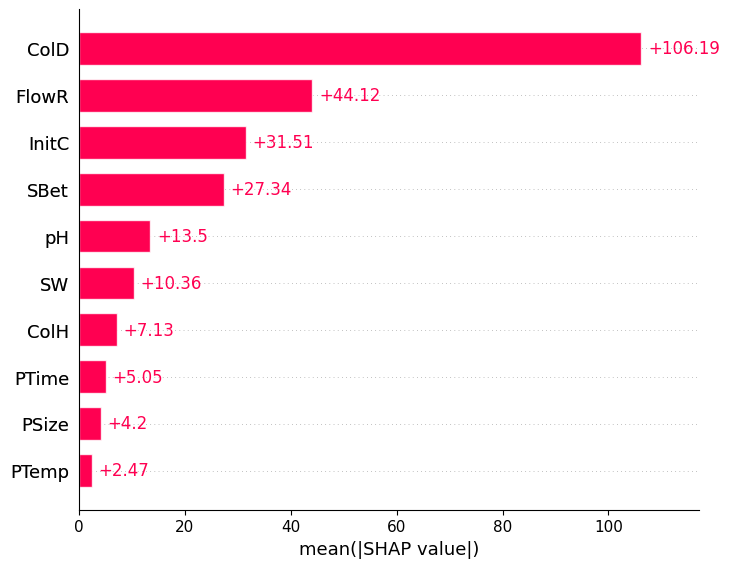

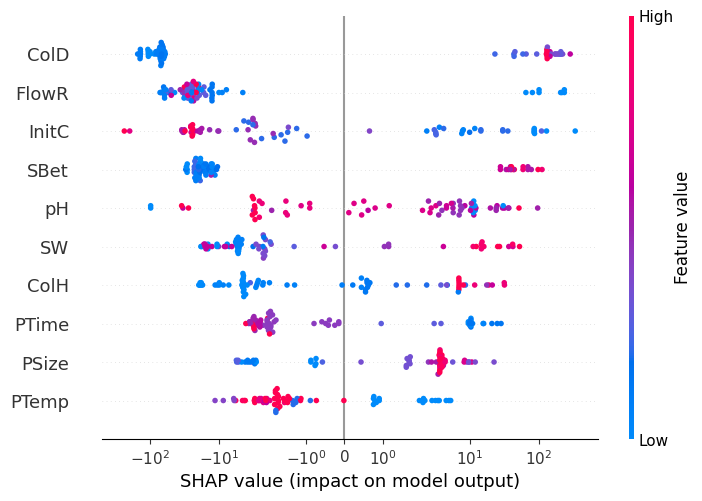

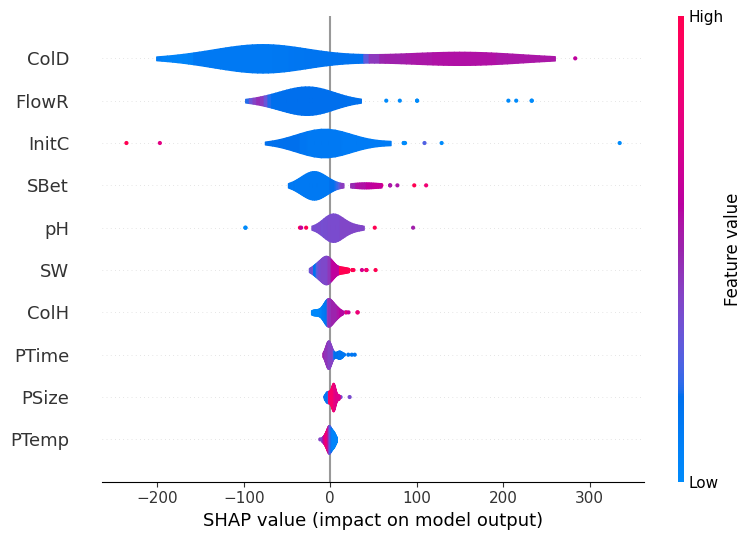

In [42]:
estimator = est
explainer = shap.Explainer(estimator, seed = 30, algorithm ='tree')
shap_values = explainer(X_train) 
ax=shap.plots.bar(shap_values, max_display=12, order=shap.Explanation.abs, show=True)
ax1=shap.plots.beeswarm(shap_values, max_display=12, log_scale=True)
ax2=shap.summary_plot(shap_values, X_train, plot_type="violin", color_bar_label='Feature value',layered_violin_max_num_bins=40)


# GBR

In [43]:
# ===== Hyperparameter optimisation: T: GBR =====
DEFAULTS['T_GBR'] = dict(learning_rate=0.018, n_estimators=200, alpha=0.2, random_state=8, max_depth=7)   # original values (hand-set by the authors)
_X = df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW', 'ColD', 'ColH']]
_y = df['T']
_Xtr, _Xte, _ytr, _yte = train_test_split(_X, _y, test_size=0.15, random_state=71)   # same split as the training cell below
tune('T_GBR', GBR, 'gbr', _Xtr, _ytr)

[T_GBR] saved tuned hyperparameters re-used   CV r2: original -1.140 -> tuned 0.418
          {'alpha': 0.5, 'learning_rate': 0.1, 'loss': 'huber', 'max_depth': 2, 'max_features': 'sqrt', 'min_samples_leaf': 6, 'n_estimators': 100, 'subsample': 1.0}


In [44]:

X= df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW', 'ColD', 'ColH']]
y=df['T']
#-------------------------------------------------------------------------------------------------------------

for rs in [71]:                   # 41,71
    print('Random State: ', rs)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = rs) # Split the data

# Train the model on the training set
    est=GBR(**hp('T_GBR'))   # hyperparameters: see the tuning cell above
    est.fit(X_train, y_train)

# Make predictions on the testing set
    y_pred_test = est.predict(X_test).round(2)
    y_pred_train = est.predict(X_train).round(2)
    
       
    r2_a_train = r2_score(y_train, y_pred_train)
    r2_a_test = r2_score(y_test,   y_pred_test)
    CV5_scores = cross_val_score(est, X_train, y_train, cv=5)

    print('train: R2 score for predicting b coeff = ', round(r2_a_train, 3))
    print('test: R2 score for predicting b coeff = ', round(r2_a_test, 3))
    print('cv5: R2 score for predicting b coeff = ', CV5_scores.mean().round(3))
    print('---')
    
    #---------------------------------------------------------------------------------------------------------------
SCORES['T_GBR'] = dict(train=float(r2_a_train), test=float(r2_a_test), cv5=float(CV5_scores.mean()))
joblib.dump(est, 'GBR_G_full.sav')

Random State:  71


train: R2 score for predicting b coeff =  0.534
test: R2 score for predicting b coeff =  0.594
cv5: R2 score for predicting b coeff =  0.264
---


['GBR_G_full.sav']

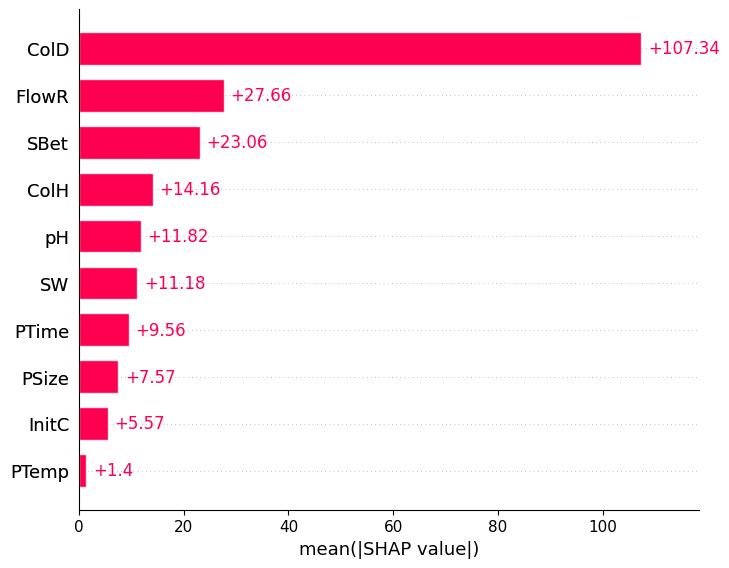

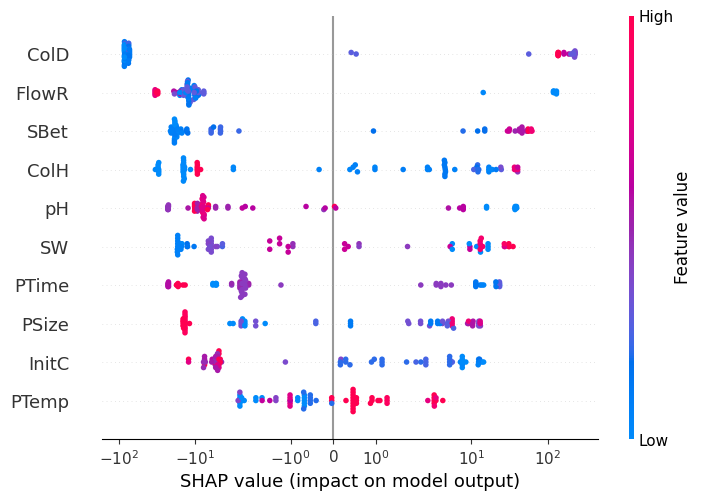

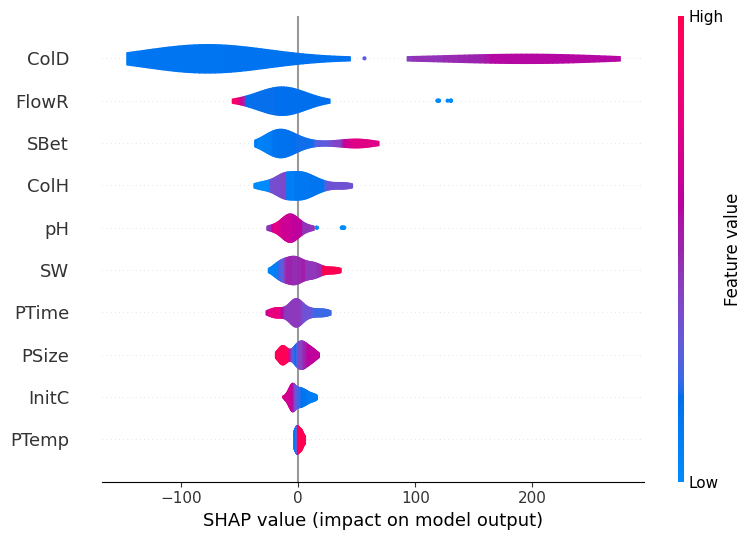

In [45]:
estimator = est
explainer = shap.Explainer(estimator, seed = 30, algorithm ='tree')
shap_values = explainer(X_train) 
ax=shap.plots.bar(shap_values, max_display=12, order=shap.Explanation.abs, show=True)
ax1=shap.plots.beeswarm(shap_values, max_display=12, log_scale=True)
ax2=shap.summary_plot(shap_values, X_train, plot_type="violin", color_bar_label='Feature value',layered_violin_max_num_bins=40)


# RFR

In [46]:
# ===== Hyperparameter optimisation: T: RFR =====
DEFAULTS['T_RF'] = dict(n_estimators=300, max_depth=8, min_samples_leaf=1,criterion='squared_error', random_state=3)   # original values (hand-set by the authors)
_X = df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW', 'ColD', 'ColH']]
_y = df['T']
_Xtr, _Xte, _ytr, _yte = train_test_split(_X, _y, test_size=0.15, random_state=71)   # same split as the training cell below
tune('T_RF', RF, 'rf', _Xtr, _ytr)

[T_RF] grid search: 960 combinations x 10 CV fits = 9600 fits; rough estimate 12 min on 8 cores (the real time can be 1-3x of this)


[T_RF] search finished in 25.7 min   CV r2: original -0.510 -> tuned 0.183
          {'bootstrap': True, 'max_depth': 12, 'max_features': 0.7, 'min_samples_leaf': 10, 'min_samples_split': 2, 'n_estimators': 400}


In [47]:

X= df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW', 'ColD', 'ColH']]
y=df['T']
#-------------------------------------------------------------------------------------------------------------

for rs in [71]:                   # ,201,248,3,13,43,48,71
    print('Random State: ', rs)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = rs) # Split the data

# Train the model on the training set

    est=RF(**hp('T_RF'))   # hyperparameters: see the tuning cell above
    est.fit(X_train, y_train)

# Make predictions on the testing set
    y_pred_test = est.predict(X_test).round(2)
    y_pred_train = est.predict(X_train).round(2)
    
       
    r2_a_train = r2_score(y_train, y_pred_train)
    r2_a_test = r2_score(y_test,   y_pred_test)
    CV5_scores = cross_val_score(est, X_train, y_train, cv=5)

    print('train: R2 score for predicting T coeff = ', round(r2_a_train, 3))
    print('test: R2 score for predicting T coeff = ', round(r2_a_test, 3))
    print('cv5: R2 score for predicting T coeff = ', CV5_scores.mean().round(3))
    print('---')
    
    #---------------------------------------------------------------------------------------------------------------
SCORES['T_RF'] = dict(train=float(r2_a_train), test=float(r2_a_test), cv5=float(CV5_scores.mean()))
joblib.dump(est, 'RFR_G_full.sav')

Random State:  71


train: R2 score for predicting T coeff =  0.478
test: R2 score for predicting T coeff =  0.547
cv5: R2 score for predicting T coeff =  0.251
---


['RFR_G_full.sav']

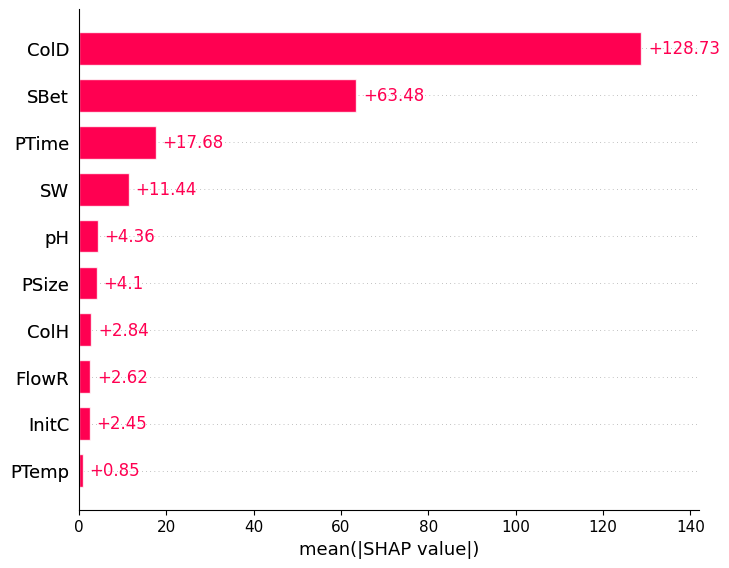

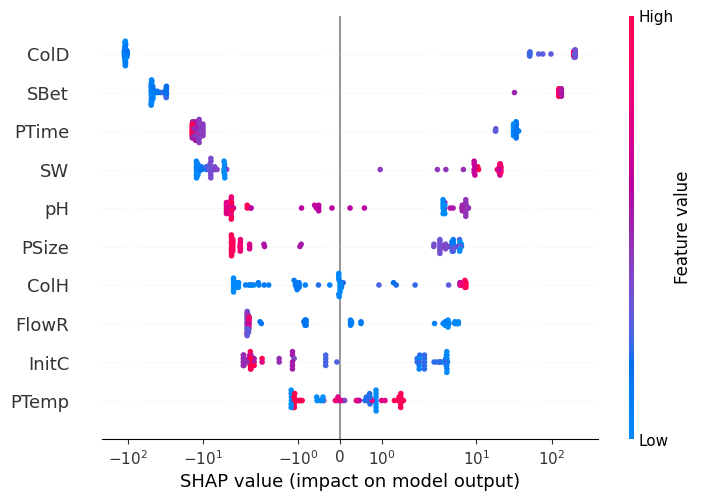

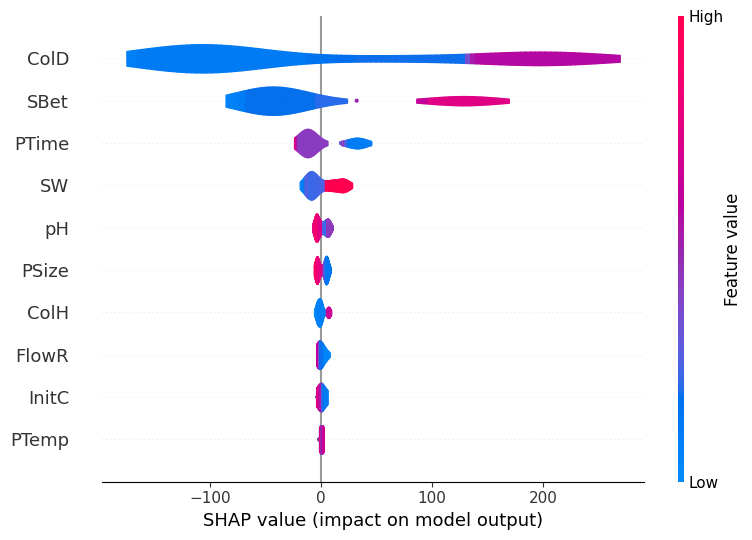

In [48]:
estimator = est
explainer = shap.Explainer(estimator, seed = 30, algorithm ='tree')
shap_values = explainer(X_train) 
ax=shap.plots.bar(shap_values, max_display=12, order=shap.Explanation.abs, show=True)
ax1=shap.plots.beeswarm(shap_values, max_display=12, log_scale=True)
ax2=shap.summary_plot(shap_values, X_train, plot_type="violin", color_bar_label='Feature value',layered_violin_max_num_bins=40)


In [49]:
XGBR_M=joblib.load('XGBR_G_full.sav')
GBR_M= joblib.load('GBR_G_full.sav')
RFR_M= joblib.load('RFR_G_full.sav')

# ploting accuracy

In [50]:
plt.style.use('seaborn-v0_8-white')
# Set the default text font size
plt.rc('font', size=22)
# Set the fig title font size
plt.rc('axes', titlesize=22)
# Set the axes labels font size
plt.rc('axes', labelsize=2)
# Set the font size for x tick labels
plt.rc('xtick', labelsize=20)
# Set the font size for y tick labels
plt.rc('ytick', labelsize=20)
# Set the legend font size
plt.rc('legend', fontsize=22)
# Set the font size of the figure title
plt.rc('figure', titlesize=22)

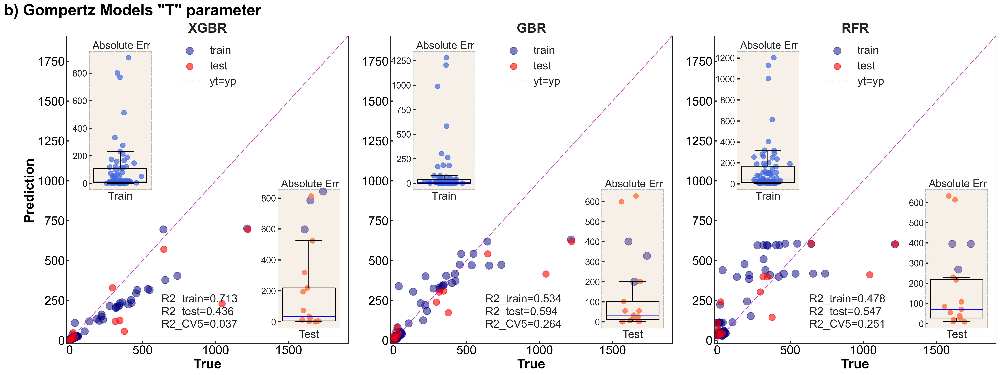

In [51]:
import matplotlib.gridspec as gridspec
 
fontdict1={'fontsize': 12, 'fontweight': 'bold', 'fontfamily': 'arial'}
fontdict2={'fontsize': 24, 'fontweight': 'bold', 'color': 'k', 'fontfamily': 'arial'}
rs=[71,71,71]
XGBR_M=joblib.load('XGBR_G_full.sav')
GBR_M= joblib.load('GBR_G_full.sav')
RFR_M= joblib.load('RFR_G_full.sav')

yp_train_XGBR= XGBR_M.predict(X_train)
yp_train_GBR= GBR_M.predict(X_train)
yp_train_RFR= RFR_M.predict(X_train)

yp_test_XGBR= XGBR_M.predict(X_train)
yp_test_GBR= GBR_M.predict(X_train)
yp_test_RFR= RFR_M.predict(X_train)

fig = plt.figure(figsize=(30,10), dpi=300)
gs  = gridspec.GridSpec(1, 3, wspace=0.15, hspace=0.1, width_ratios=[1, 1, 1], height_ratios=[1])
modelsName=['XGBR', 'GBR', 'RFR']
LIM = 1.1*float(np.max(y))   # axis limit follows the data

YP_train=[yp_train_XGBR,yp_train_GBR,yp_train_RFR]

j=0
for i in range(0,3):
    ax = fig.add_subplot(gs[0,j])
    #------------------------------------------------ Data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = rs[i])
    yp_train_XGBR= XGBR_M.predict(X_train)
    yp_train_GBR= GBR_M.predict(X_train)
    yp_train_RFR= RFR_M.predict(X_train)

    yp_test_XGBR= XGBR_M.predict(X_test)
    yp_test_GBR= GBR_M.predict(X_test)
    yp_test_RFR= RFR_M.predict(X_test)
    YP_train=[yp_train_XGBR, yp_train_GBR, yp_train_RFR]
    YP_test=[yp_test_XGBR, yp_test_GBR, yp_test_RFR]
    
    ax.scatter(y_train, YP_train[i], s=180, color='navy',label='train', alpha=0.5)
    ax.scatter(y_test, YP_test[i], s=140, color='r',label='test', alpha=0.6)
    ax.plot([0, LIM], [0, LIM], 'k-.', lw=1.2, label='yt=yp', alpha=.8, color='m')

    #-----------------------------------------------------------------------------------
    ax2=ax.inset_axes([0.08, .50, 0.22, 0.45])
    ax2.set_xticks([])
    ax2.tick_params(axis='y', labelsize=16)
    ax2.spines[['top', 'bottom','right', 'left' ]].set_color('gray')
    ax2.spines[['top', 'bottom','right', 'left' ]].set_linestyle('--')
    ax2.spines[['top', 'bottom','right', 'left' ]].set_alpha(0.5)
    ax2.set_facecolor('tan')
    ax2.patch.set_alpha(0.2)
    #--------------------------------------------
    # calculate the train eroors
    err_train=abs(y_train-YP_train[i]).round(3)
    #--------------------------------------------
    ax2.boxplot(err_train, widths=0.85,tick_labels=['Train'], meanline =True,vert=True,
                showfliers = False,
                medianprops = {"color": "b", "linewidth": 1.5},
                boxprops = {"color": "k", "linewidth": 1.5},
                whiskerprops = {"color": "k", "linewidth": 1.5},
                capprops = {"color": "k", "linewidth": 1.5})
    xs, names = [], []
    vals=np.asanyarray(err_train)
    #names.append(col)
    xs.append(np.random.normal(1, 0.1, len(err_train)))
    ax2.scatter(xs,err_train, alpha= 0.7, marker='o', s=80, color='royalblue')
    ax2.text(0.55, 1.07*max(err_train), 'Absolute Err', fontsize = 19)
    #-----------------------------------------------------------------------------------------
    #-----------------------------------------------------------------------------------------
    ax3=ax.inset_axes([0.75, .05, 0.22, 0.45])
    ax3.tick_params(axis='y', labelsize=16)
    ax3.set_xticks([])
    ax3.spines[['top', 'bottom','right', 'left' ]].set_color('gray')
    ax3.spines[['top', 'bottom','right', 'left' ]].set_linestyle('--')
    ax3.spines[['top', 'bottom','right', 'left' ]].set_alpha(0.5)
    ax3.set_facecolor('tan')
    ax3.patch.set_alpha(0.2)
    #--------------------------------------------
    # calculate the train eroors
    err_test=abs(y_test-YP_test[i]).round(3)
    #--------------------------------------------
    ax3.boxplot(err_test, widths=0.85,tick_labels=['Test'], meanline =True,vert=True,
                showfliers = False,
                medianprops = {"color": "b", "linewidth": 1.5},
                boxprops = {"color": "k", "linewidth": 1.5},
                whiskerprops = {"color": "k", "linewidth": 1.5},
                capprops = {"color": "k", "linewidth": 1.5})
    xs, names = [], []
    vals=np.asanyarray(err_train)
    #names.append(col)
    xs.append(np.random.normal(1, 0.1, len(err_test)))
    ax3.scatter(xs,err_test, alpha= 0.9, marker='o', s=80, color='coral')
    ax3.text(0.55, 1.07*max(err_test), 'Absolute Err', fontsize = 19)
    #------------------------------------------------------------------------------------------
    #------------------------------------------------------------------------------------------

    ax.set_xlim([-0.01*LIM, LIM])
    ax.set_ylim([-0.01*LIM, LIM])
    ax.set_xlabel('True', fontdict=fontdict2)
    if j==0:
        ax.set_ylabel('Prediction', fontdict=fontdict2)
    ax.set_title(modelsName[j]  , loc= 'center', fontdict = fontdict1, fontsize=24)
    ax.tick_params(labelcolor='k', labelsize='medium', width=3)
    ax.legend(loc= 'upper center', fontsize=20)
    ax.tick_params(axis='x', which='both', direction='in', length=5, width=2)
    ax.tick_params(axis='y', which='both', direction='in', length=5, width=2)
    ax2.tick_params(axis='y', which='both', direction='in', length=5, width=2)
    ax3.tick_params(axis='y', which='both', direction='in', length=5, width=2)
    #------------------------------------------------------------------------------------------
    _models=[XGBR_M, GBR_M, RFR_M]
    R2TR=['R2_train='+str(round(r2_score(y_train, m.predict(X_train)), 3)) for m in _models]
    R2TE=['R2_test='+str(round(r2_score(y_test, m.predict(X_test)), 3)) for m in _models]
    CV5R2=['R2_CV5='+str(round(cross_val_score(m, X_train, y_train, cv=5).mean(), 3)) for m in _models]
    ax.text(0.33*LIM, 0.125*LIM, R2TR[j], fontsize = 20)
    ax.text(0.33*LIM, 0.083*LIM,  R2TE[j], fontsize = 20)
    ax.text(0.33*LIM, 0.042*LIM,  CV5R2[j], fontsize = 20)
    j=j+1
fig.suptitle('b) Gompertz Models "T" parameter', fontsize=28, fontweight='bold', color='k', x=.18, y=0.96)
plt.savefig('G_b_errors_full', dpi=300)
plt.show()

In [52]:
T_xgbr=XGBR_M.predict(X)
T_gbr=GBR_M.predict(X)
T_rfr=RFR_M.predict(X)

In [53]:
Results_df=df.copy()
Results_df['T_xgbr']=0.0
Results_df['T_gbr']=0.0
Results_df['T_rfr']=0.0
for i in range(0, len(Results_df)):
    Results_df.iat[i, Results_df.columns.get_loc('T_xgbr')] = float(T_xgbr[i].round(3))
    Results_df.iat[i, Results_df.columns.get_loc('T_gbr')] = float(T_gbr[i].round(3))
    Results_df.iat[i, Results_df.columns.get_loc('T_rfr')] = float(T_rfr[i].round(3))

Results_df.head(5)    

,pH,InitC,FlowR,PTemp,PTime,SBet,PSize,SW,ColD,ColH,a,b,K,T,T_xgbr,T_gbr,T_rfr
0,6.0,50.0,1.206642,600.0,60.0,154.25,0.25,0.3,16.998275,38.733061,1.687546,273.903085,268.300685,218.662858,150.022995,221.878,385.272
1,6.0,50.0,0.600000,600.0,60.0,170.34,0.25,0.3,17.816205,38.679527,3.865591,1885.907647,749.893442,1609.155347,695.895020,620.279,605.301
2,3.0,50.0,0.845751,600.0,60.0,170.34,0.25,0.3,30.367346,27.083182,2.165379,582.503009,411.388211,464.210519,316.425995,542.600,606.695
3,4.0,50.0,0.845751,600.0,60.0,170.34,0.25,0.3,30.367346,27.083182,2.139914,690.175718,507.811152,547.794338,316.425995,542.600,606.695
4,5.0,50.0,0.845751,600.0,60.0,170.34,0.25,0.3,30.367346,27.083182,1.775402,842.165158,799.791750,645.288674,571.651001,542.600,606.695


# Finding k

In [54]:
def dose_response(t, a, b):
    return (1-1/(1+(t/b)**(a)))

def Gompertz(t, K, T):
    return (np.exp(-1*np.exp((1/K)*(T-t))))

Optimized parameters: [2.17738213 0.8001962 ]


Text(1.7351606619823123, 457.17059271015546, 'R2: 0.652')

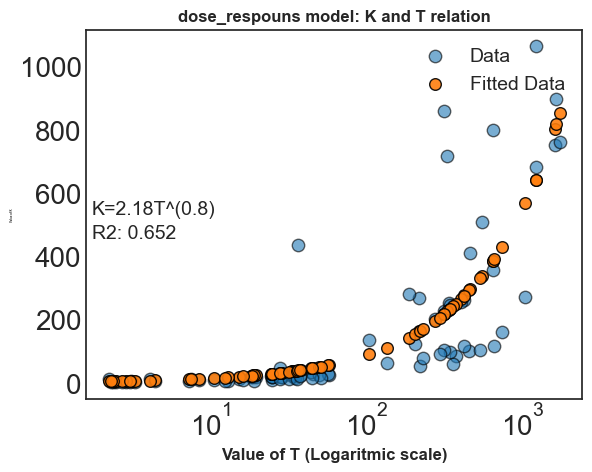

In [55]:
# Define the model function to fit
def model_func(x, c_1, c_2):
    return c_1*(x**c_2)
xx=np.asanyarray(df['T'])
yy=np.asanyarray(df['K'])
# Perform curve fitting

popt, pcov = curve_fit(model_func, xx, yy, method='lm', p0=[1.66,-0.9])
equation='K={:.3}T^({:.3})'.format(popt[0], popt[1])

# Print the optimized parameters
print('Optimized parameters:', popt)

plt.scatter(xx, yy, label='Data', marker='o', alpha=0.6, edgecolors='k', s=80)
plt.scatter(xx, np.asanyarray((model_func(xx, *popt))), label='Fitted Data', marker='o', alpha=0.9, edgecolors='k', s=70)
plt.xscale('log')
plt.legend(loc='upper right', fontsize=14)
plt.xlabel("Value of T (Logaritmic scale)", fontdict=fontdict1)
plt.ylabel("Value of K", fontweight='bold')
plt.title('dose_respouns model: K and T relation', fontdict=fontdict1)
R2_score= r2_score(yy, model_func(xx, *popt))
plt.text(xx.max()*0.001, yy.max()*0.5,equation,fontsize=14 )
plt.text(xx.max()*0.001, yy.max()*0.43,'R2: ' + str(round(R2_score, 3)), fontsize=14)


In [56]:
# ===== Hyperparameter optimisation: K: XGBR =====
DEFAULTS['K_XGBR'] = dict(learning_rate =0.015, n_estimators=250, reg_alpha=0.060, reg_lambda=0.07, max_depth =5, random_state =7, tree_method='exact', base_score=0.5)   # original values (hand-set by the authors)
_X = df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW',  'T']]
_y = df['K']
_Xtr, _Xte, _ytr, _yte = train_test_split(_X, _y, test_size=0.15, random_state=71)   # same split as the training cell below
tune('K_XGBR', XGBR, 'xgb', _Xtr, _ytr)

[K_XGBR] grid search: 16200 combinations x 10 CV fits = 162000 fits; rough estimate 15 min on 8 cores (the real time can be 1-3x of this)


[K_XGBR] search finished in 54.3 min   CV r2: original 0.544 -> tuned 0.825
          {'colsample_bytree': 0.5, 'learning_rate': 0.1, 'max_depth': 6, 'min_child_weight': 3, 'n_estimators': 200, 'reg_alpha': 0.01, 'reg_lambda': 5.0, 'subsample': 1.0}


In [57]:

X= df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW',  'T']]

y=df['K']


#-------------------------------------------------------------------------------------------------------------

for rs in [71]:                   # 64
    print('Random State: ', rs)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = rs) # Split the data

# Train the model on the training set
#    est=GBR(learning_rate=0.0235, n_estimators=260, alpha=0.1, random_state=10, max_depth=5 )
    est=XGBR(**hp('K_XGBR'))   # hyperparameters: see the tuning cell above
#    est=RF(n_estimators=600, max_depth=5, min_samples_leaf=2,criterion='squared_error', random_state=14 )
#    est = KNN(n_neighbors=5, leaf_size=20)
#    est=MLPRegressor(hidden_layer_sizes=(300, 30), activation='relu', solver='adam', max_iter=5000, random_state=0)
    
    est.fit(X_train, y_train)

# Make predictions on the testing set
    y_pred_test = est.predict(X_test).round(2)
    y_pred_train = est.predict(X_train).round(2)
          
    r2_a_train = r2_score(y_train, y_pred_train)
    r2_a_test = r2_score(y_test,   y_pred_test)
    CV5_scores = cross_val_score(est, X_train, y_train, cv=5)

    print('train: R2 score for predicting a coeff = ', round(r2_a_train, 3))
    print('test: R2 score for predicting a coeff = ', round(r2_a_test, 3))
    print('cv5: R2 score for predicting a coeff = ', CV5_scores.mean().round(3))
    print('---')
    
    #---------------------------------------------------------------------------------------------------------------
SCORES['K_XGBR'] = dict(train=float(r2_a_train), test=float(r2_a_test), cv5=float(CV5_scores.mean()))
joblib.dump(est, 'RFR_K_G_full.sav')

Random State:  71


train: R2 score for predicting a coeff =  0.997
test: R2 score for predicting a coeff =  0.734
cv5: R2 score for predicting a coeff =  0.883
---


['RFR_K_G_full.sav']

In [58]:
y

0     268.300685
1     749.893442
2     411.388211
3     507.811152
4     799.791750
         ...    
79      1.210640
80      1.668134
81      2.176828
82      1.843150
83      1.431235
Name: K, Length: 84, dtype: float64

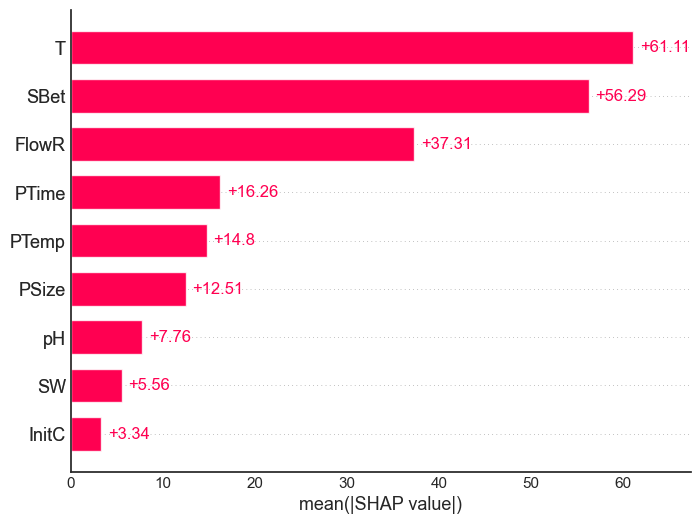

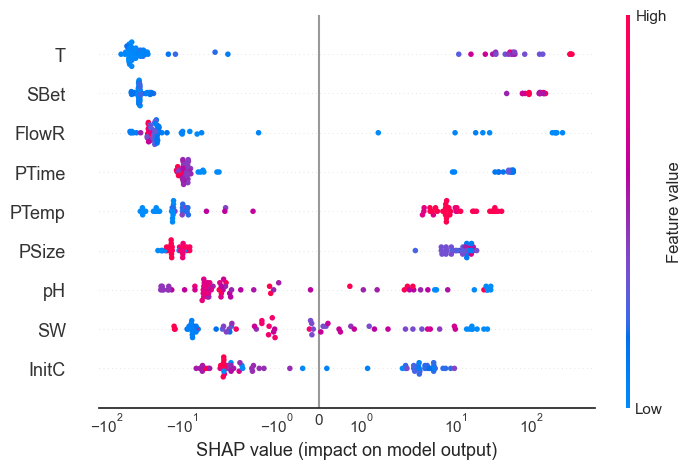

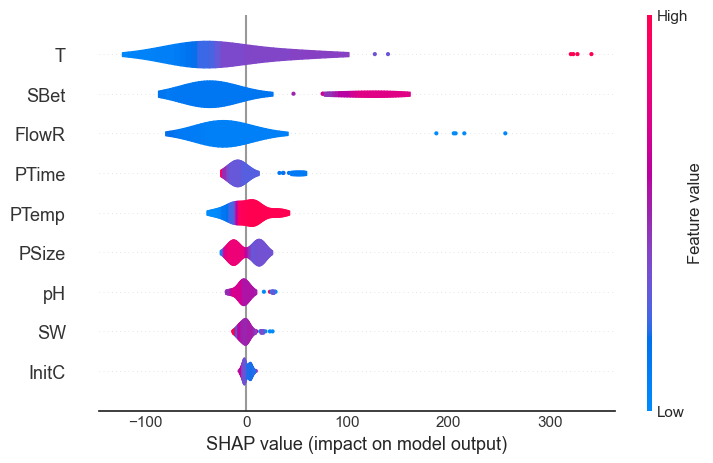

In [59]:
estimator = est
explainer = shap.Explainer(estimator, seed = 30, algorithm ='tree')
shap_values = explainer(X_train) 
ax=shap.plots.bar(shap_values, max_display=12, order=shap.Explanation.abs, show=True)
ax1=shap.plots.beeswarm(shap_values, max_display=12, log_scale=True)
ax2=shap.summary_plot(shap_values, X_train, plot_type="violin", color_bar_label='Feature value',layered_violin_max_num_bins=40)


# GBR

In [60]:
# ===== Hyperparameter optimisation: K: GBR =====
DEFAULTS['K_GBR'] = dict(learning_rate=0.0235, n_estimators=260, alpha=0.1, random_state=10, max_depth=5)   # original values
_X = df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW',  'T']]
_y = df['K']
_Xtr, _Xte, _ytr, _yte = train_test_split(_X, _y, test_size=0.15, random_state=71)   # same split as the training cell below
tune('K_GBR', GBR, 'gbr', _Xtr, _ytr)

[K_GBR] grid search: 3456 combinations x 10 CV fits = 34560 fits; rough estimate 27 min on 8 cores (the real time can be 1-3x of this)


[K_GBR] search finished in 49.0 min   CV r2: original 0.516 -> tuned 0.810
          {'alpha': 0.5, 'learning_rate': 0.05, 'loss': 'huber', 'max_depth': 2, 'max_features': 0.5, 'min_samples_leaf': 3, 'n_estimators': 200, 'subsample': 1.0}


In [61]:

X= df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW',  'T']]
y=df['K']
#-------------------------------------------------------------------------------------------------------------

for rs in [71]:
    print('Random State: ', rs)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = rs) # Split the data

# Train the model on the training set
    est=GBR(**hp('K_GBR'))   # hyperparameters: see the tuning cell above
    est.fit(X_train, y_train)

# Make predictions on the testing set
    y_pred_test = est.predict(X_test).round(2)
    y_pred_train = est.predict(X_train).round(2)

    r2_a_train = r2_score(y_train, y_pred_train)
    r2_a_test = r2_score(y_test,   y_pred_test)
    CV5_scores = cross_val_score(est, X_train, y_train, cv=5)

    print('train: R2 score for predicting K coeff = ', round(r2_a_train, 3))
    print('test: R2 score for predicting K coeff = ', round(r2_a_test, 3))
    print('cv5: R2 score for predicting K coeff = ', CV5_scores.mean().round(3))
    print('---')

    #-------------------------------------------------------------------------------------------------------------
SCORES['K_GBR'] = dict(train=float(r2_a_train), test=float(r2_a_test), cv5=float(CV5_scores.mean()))
joblib.dump(est, 'GBR_K_G_full.sav')

Random State:  71


train: R2 score for predicting K coeff =  0.939
test: R2 score for predicting K coeff =  0.771
cv5: R2 score for predicting K coeff =  0.841
---


['GBR_K_G_full.sav']

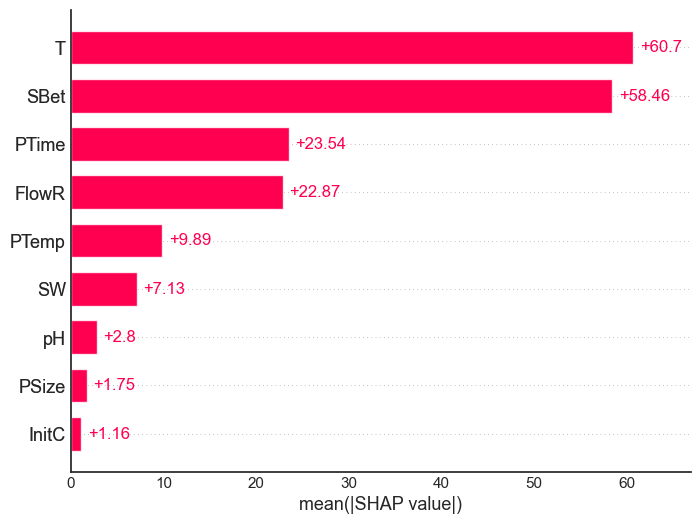

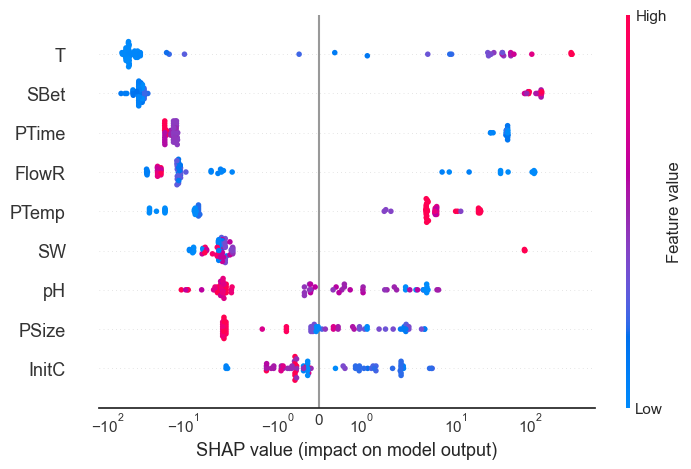

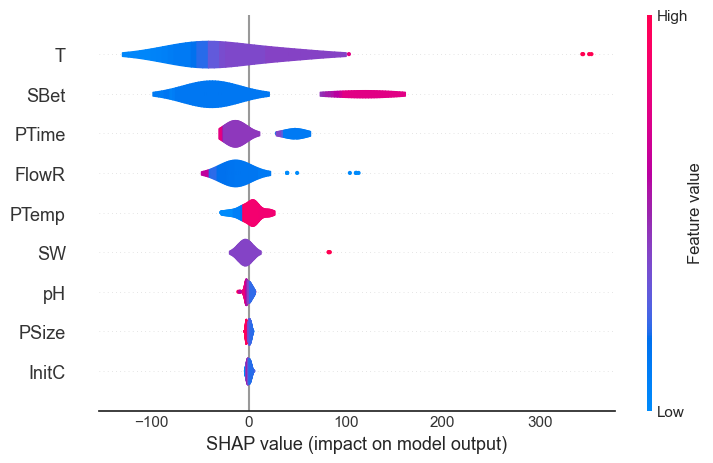

In [62]:
estimator = est
explainer = shap.Explainer(estimator, seed = 30, algorithm ='tree')
shap_values = explainer(X_train) 
ax=shap.plots.bar(shap_values, max_display=12, order=shap.Explanation.abs, show=True)
ax1=shap.plots.beeswarm(shap_values, max_display=12, log_scale=True)
ax2=shap.summary_plot(shap_values, X_train, plot_type="violin", color_bar_label='Feature value',layered_violin_max_num_bins=40)


# RFR

In [63]:
# ===== Hyperparameter optimisation: K: RFR =====
DEFAULTS['K_RF'] = dict(n_estimators=600, max_depth=5, min_samples_leaf=2, criterion='squared_error', random_state=14)   # original values
_X = df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW',  'T']]
_y = df['K']
_Xtr, _Xte, _ytr, _yte = train_test_split(_X, _y, test_size=0.15, random_state=71)   # same split as the training cell below
tune('K_RF', RF, 'rf', _Xtr, _ytr)

[K_RF] grid search: 960 combinations x 10 CV fits = 9600 fits; rough estimate 26 min on 8 cores (the real time can be 1-3x of this)


[K_RF] search finished in 23.1 min   CV r2: original 0.669 -> tuned 0.694
          {'bootstrap': True, 'max_depth': 8, 'max_features': 0.7, 'min_samples_leaf': 1, 'min_samples_split': 6, 'n_estimators': 200}


In [64]:

X= df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW',  'T']]
y=df['K']
#-------------------------------------------------------------------------------------------------------------

for rs in [71]:
    print('Random State: ', rs)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = rs) # Split the data

# Train the model on the training set
    est=RF(**hp('K_RF'))   # hyperparameters: see the tuning cell above
    est.fit(X_train, y_train)

# Make predictions on the testing set
    y_pred_test = est.predict(X_test).round(2)
    y_pred_train = est.predict(X_train).round(2)

    r2_a_train = r2_score(y_train, y_pred_train)
    r2_a_test = r2_score(y_test,   y_pred_test)
    CV5_scores = cross_val_score(est, X_train, y_train, cv=5)

    print('train: R2 score for predicting K coeff = ', round(r2_a_train, 3))
    print('test: R2 score for predicting K coeff = ', round(r2_a_test, 3))
    print('cv5: R2 score for predicting K coeff = ', CV5_scores.mean().round(3))
    print('---')

    #-------------------------------------------------------------------------------------------------------------
SCORES['K_RF'] = dict(train=float(r2_a_train), test=float(r2_a_test), cv5=float(CV5_scores.mean()))
joblib.dump(est, 'RFR_K_RF_full.sav')

Random State:  71


train: R2 score for predicting K coeff =  0.93
test: R2 score for predicting K coeff =  0.815
cv5: R2 score for predicting K coeff =  0.773
---


['RFR_K_RF_full.sav']

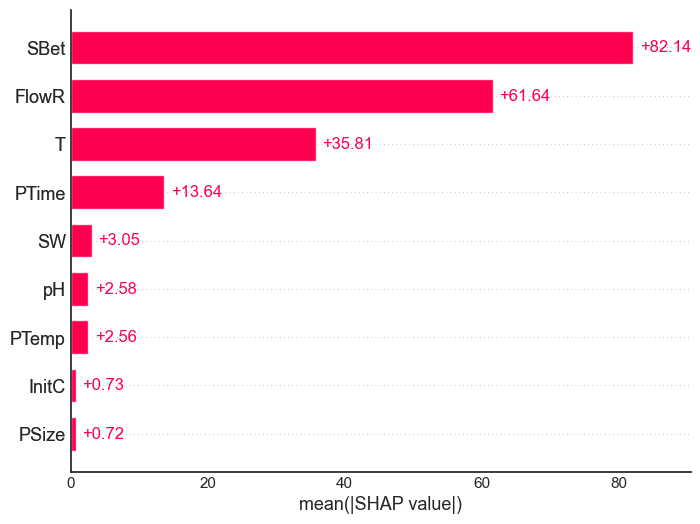

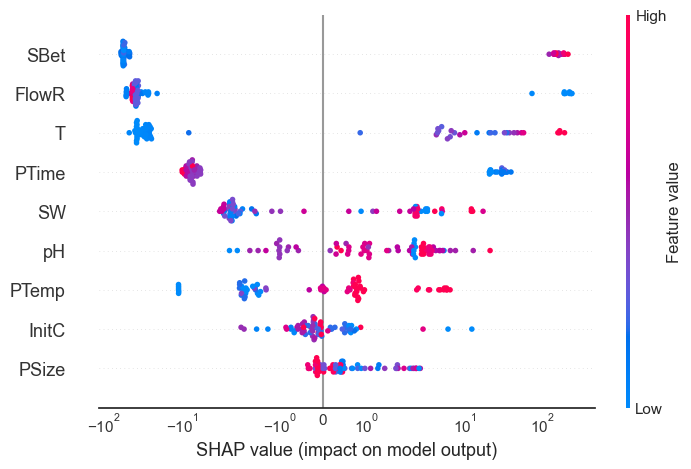

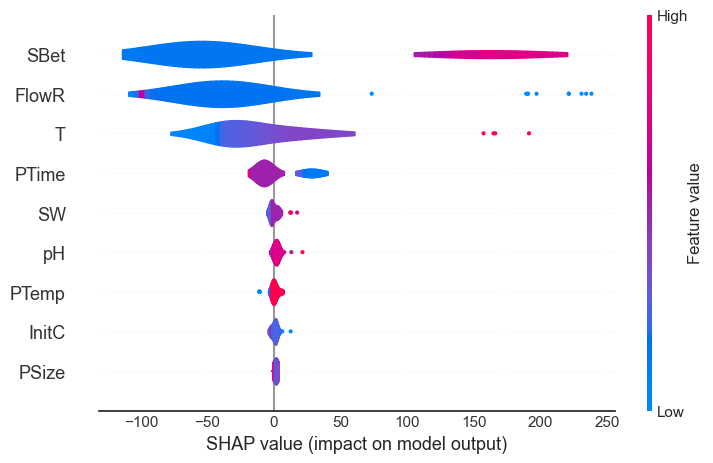

In [65]:
estimator = est
explainer = shap.Explainer(estimator, seed = 30, algorithm ='tree')
shap_values = explainer(X_train) 
ax=shap.plots.bar(shap_values, max_display=12, order=shap.Explanation.abs, show=True)
ax1=shap.plots.beeswarm(shap_values, max_display=12, log_scale=True)
ax2=shap.summary_plot(shap_values, X_train, plot_type="violin", color_bar_label='Feature value',layered_violin_max_num_bins=40)


In [66]:
RFR_K_G=joblib.load('RFR_K_G_full.sav')
K_pred=RFR_K_G.predict(X)

Results_df['K_pred']=0.0
for i in range(0, len(Results_df)):
    Results_df.iat[i, Results_df.columns.get_loc('K_pred')] = float(K_pred[i].round(3))

In [67]:
# predictions of the three K models (K_pred above is the original XGBR column)
XGBR_K = joblib.load('RFR_K_G_full.sav'); GBR_K = joblib.load('GBR_K_G_full.sav'); RFR_K = joblib.load('RFR_K_RF_full.sav')
Results_df['K_xgbr'] = XGBR_K.predict(X).round(3)
Results_df['K_gbr'] = GBR_K.predict(X).round(3)
Results_df['K_rfr'] = RFR_K.predict(X).round(3)

In [68]:
Results_df['K_pred_teor']=0.0
for i in range(0, len(Results_df)):
    Results_df.iat[i, Results_df.columns.get_loc('K_pred_teor')] = popt[0]*(Results_df['T'].iloc[i])**popt[1]

In [69]:
Results_df.head(10)

,pH,InitC,FlowR,PTemp,PTime,SBet,PSize,SW,ColD,ColH,...,K,T,T_xgbr,T_gbr,T_rfr,K_pred,K_xgbr,K_gbr,K_rfr,K_pred_teor
0,6.0,50.0,1.206642,600.0,60.0,154.25,0.25,0.3,16.998275,38.733061,...,268.300685,218.662858,150.022995,221.878,385.272,271.542999,271.542999,268.083,386.650,162.260843
1,6.0,50.0,0.600000,600.0,60.0,170.34,0.25,0.3,17.816205,38.679527,...,749.893442,1609.155347,695.895020,620.279,605.301,748.333008,748.333008,749.740,721.063,801.386751
2,3.0,50.0,0.845751,600.0,60.0,170.34,0.25,0.3,30.367346,27.083182,...,411.388211,464.210519,316.425995,542.600,606.695,448.511993,448.511993,436.681,543.619,296.366996
3,4.0,50.0,0.845751,600.0,60.0,170.34,0.25,0.3,30.367346,27.083182,...,507.811152,547.794338,316.425995,542.600,606.695,453.289001,453.289001,436.681,547.076,338.349855
4,5.0,50.0,0.845751,600.0,60.0,170.34,0.25,0.3,30.367346,27.083182,...,799.791750,645.288674,571.651001,542.600,606.695,401.628998,401.628998,436.512,547.375,385.735096
5,6.0,50.0,0.600000,600.0,60.0,170.34,0.25,0.3,17.816205,38.679527,...,681.021303,1219.624424,695.895020,620.279,605.301,762.015015,762.015015,749.740,721.063,641.979342
6,7.0,50.0,0.990999,600.0,60.0,170.34,0.25,0.3,17.489728,29.809319,...,1063.187425,1215.686059,701.922974,632.535,602.035,1017.791992,1017.791992,793.397,799.970,640.319955
7,6.0,50.0,0.600000,600.0,60.0,170.34,0.25,0.3,17.816205,38.679527,...,355.809410,643.025308,695.895020,620.279,605.301,406.453003,406.453003,434.739,557.950,384.652070
8,6.0,50.0,1.200000,600.0,60.0,170.34,0.25,0.3,17.019630,38.453083,...,858.983934,316.278617,203.279999,320.059,509.449,830.825989,830.825989,477.287,585.266,218.012315
9,6.0,50.0,2.000000,600.0,60.0,170.34,0.25,0.3,16.723996,36.423303,...,281.220666,186.216587,135.141998,233.247,478.647,298.317993,298.317993,299.364,305.020,142.690387


In [70]:
Results_df.to_pickle('Results_df_full.pkl')

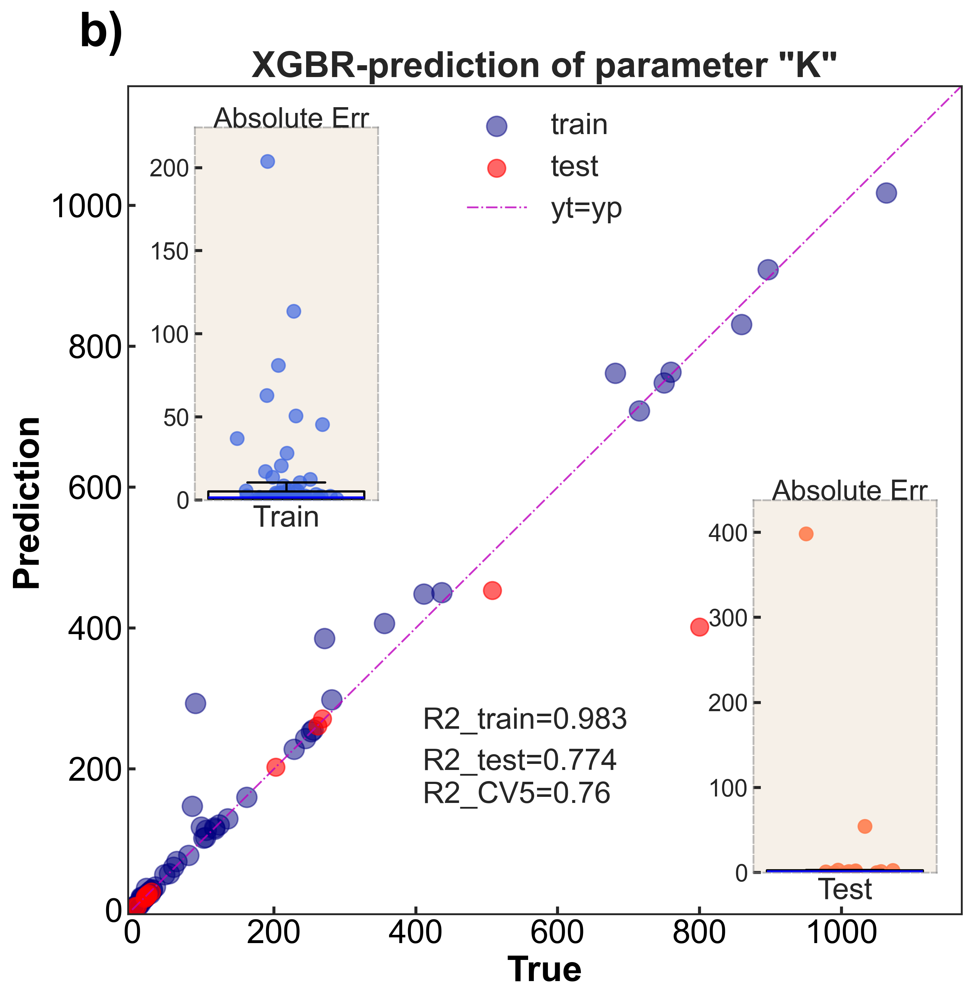

In [71]:
import matplotlib.gridspec as gridspec
 
fontdict1={'fontsize': 12, 'fontweight': 'bold', 'fontfamily': 'arial'}
fontdict2={'fontsize': 24, 'fontweight': 'bold', 'color': 'k', 'fontfamily': 'arial'}
rs=[60]
LIM = 1.1*float(np.max(y))   # axis limit follows the data

RFR= joblib.load('RFR_K_G_full.sav')


yp_train_RFR= RFR.predict(X_train)
yp_test_RFR= RFR.predict(X_test)

fig = plt.figure(figsize=(10,10), dpi=300)
gs  = gridspec.GridSpec(1, 1, wspace=0.15, hspace=0.1, width_ratios=[1], height_ratios=[1])
modelsName=['XGBR-prediction of parameter "K"']

YP_train=[yp_train_RFR]

j=0
for i in range(0,1):
    ax = fig.add_subplot(gs[0,j])
    #------------------------------------------------ Data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = rs[i])

    yp_train_RFR= RFR.predict(X_train)
    yp_test_RFR= RFR.predict(X_test)
    YP_train=[yp_train_RFR]
    YP_test=[yp_test_RFR]
    
    ax.scatter(y_train, YP_train[i], s=180, color='navy',label='train', alpha=0.5)
    ax.scatter(y_test, YP_test[i], s=140, color='r',label='test', alpha=0.6)
    ax.plot([0, LIM], [0, LIM], 'k-.', lw=1.2, label='yt=yp', alpha=.8, color='m')

    #-----------------------------------------------------------------------------------
    ax2=ax.inset_axes([0.08, .50, 0.22, 0.45])
    ax2.set_xticks([])
    ax2.tick_params(axis='y', labelsize=16)
    ax2.spines[['top', 'bottom','right', 'left' ]].set_color('gray')
    ax2.spines[['top', 'bottom','right', 'left' ]].set_linestyle('--')
    ax2.spines[['top', 'bottom','right', 'left' ]].set_alpha(0.5)
    ax2.set_facecolor('tan')
    ax2.patch.set_alpha(0.2)
    #--------------------------------------------
    # calculate the train eroors
    err_train=abs(y_train-YP_train[i]).round(3)
    #--------------------------------------------
    ax2.boxplot(err_train, widths=0.85,tick_labels=['Train'], meanline =True,vert=True,
                showfliers = False,
                medianprops = {"color": "b", "linewidth": 1.5},
                boxprops = {"color": "k", "linewidth": 1.5},
                whiskerprops = {"color": "k", "linewidth": 1.5},
                capprops = {"color": "k", "linewidth": 1.5})
    xs, names = [], []
    vals=np.asanyarray(err_train)
    #names.append(col)
    xs.append(np.random.normal(1, 0.1, len(err_train)))
    ax2.scatter(xs,err_train, alpha= 0.7, marker='o', s=80, color='royalblue')
    ax2.text(0.6, 1.1*max(err_train), 'Absolute Err', fontsize = 19)
    ax2.set_ylim([0, 1.1*max(err_train)])
    #-----------------------------------------------------------------------------------------
    #-----------------------------------------------------------------------------------------
    ax3=ax.inset_axes([0.75, .05, 0.22, 0.45])
    ax3.tick_params(axis='y', labelsize=16)
    ax3.set_xticks([])
    ax3.spines[['top', 'bottom','right', 'left' ]].set_color('gray')
    ax3.spines[['top', 'bottom','right', 'left' ]].set_linestyle('--')
    ax3.spines[['top', 'bottom','right', 'left' ]].set_alpha(0.5)
    ax3.set_facecolor('tan')
    ax3.patch.set_alpha(0.2)
    #--------------------------------------------
    # calculate the train eroors
    err_test=abs(y_test-YP_test[i]).round(3)
    #--------------------------------------------
    ax3.boxplot(err_test, widths=0.85,tick_labels=['Test'], meanline =True,vert=True,
                showfliers = False,
                medianprops = {"color": "b", "linewidth": 1.5},
                boxprops = {"color": "k", "linewidth": 1.5},
                whiskerprops = {"color": "k", "linewidth": 1.5},
                capprops = {"color": "k", "linewidth": 1.5})
    xs, names = [], []
    vals=np.asanyarray(err_train)
    #names.append(col)
    xs.append(np.random.normal(1, 0.1, len(err_test)))
    ax3.scatter(xs,err_test, alpha= 0.9, marker='o', s=80, color='coral')
    ax3.text(0.6, 1.1*max(err_test), 'Absolute Err', fontsize = 19)
    ax3.set_ylim([0, 1.1*max(err_test)])
    
    #------------------------------------------------------------------------------------------
    #------------------------------------------------------------------------------------------

    ax.set_xlim([-0.005*LIM, LIM])
    ax.set_ylim([-0.005*LIM, LIM])
    ax.set_xlabel('True', fontdict=fontdict2)
    if j==0:
        ax.set_ylabel('Prediction', fontdict=fontdict2)
    ax.set_title(modelsName[j]  , loc= 'center', fontdict = fontdict1, fontsize=24)
    ax.tick_params(labelcolor='k', labelsize='medium', width=3)
    ax.legend(loc= 'upper center', fontsize=20)
    ax.tick_params(axis='x', which='both', direction='in', length=5, width=2)
    ax.tick_params(axis='y', which='both', direction='in', length=5, width=2)
    ax2.tick_params(axis='y', which='both', direction='in', length=5, width=2)
    ax3.tick_params(axis='y', which='both', direction='in', length=5, width=2)
    #------------------------------------------------------------------------------------------

    ax.text(0.35*LIM, 0.22*LIM, 'R2_train='+str(round(r2_score(y_train, RFR.predict(X_train)), 3)), fontsize = 20)
    ax.text(0.35*LIM, 0.17*LIM,  'R2_test='+str(round(r2_score(y_test, RFR.predict(X_test)), 3)), fontsize = 20)
    ax.text(0.35*LIM, 0.13*LIM,  'R2_CV5='+str(round(cross_val_score(RFR, X_train, y_train, cv=5).mean(), 3)), fontsize = 20)
    j=j+1
fig.suptitle('b)', fontsize=32, fontweight='bold', color='k', x=.1, y=0.95)
plt.savefig('dr_k_errors_full', dpi=300)
plt.show()

# plotting accuracy (all three models) - K

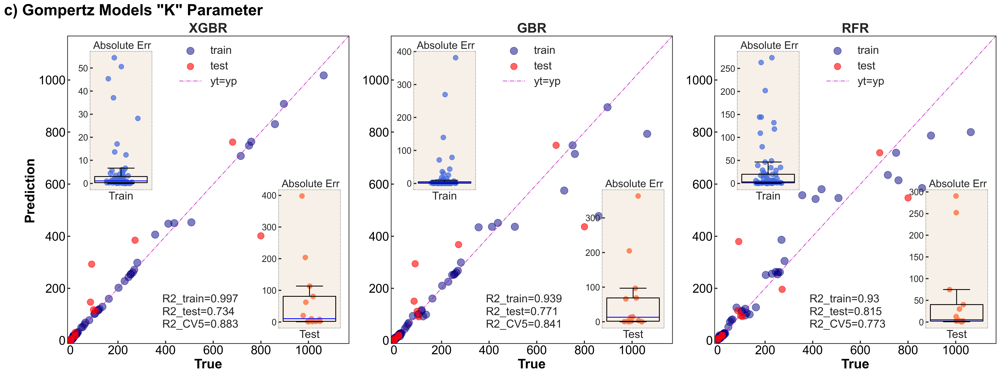

In [72]:
import matplotlib.gridspec as gridspec
 
fontdict1={'fontsize': 12, 'fontweight': 'bold', 'fontfamily': 'arial'}
fontdict2={'fontsize': 24, 'fontweight': 'bold', 'color': 'k', 'fontfamily': 'arial'}
rs=[71,71,71]
X = df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW',  'T']]
y = df['K']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = 71)
XGBR_M=joblib.load('RFR_K_G_full.sav')
GBR_M= joblib.load('GBR_K_G_full.sav')
RFR_M= joblib.load('RFR_K_RF_full.sav')

yp_train_XGBR= XGBR_M.predict(X_train)
yp_train_GBR= GBR_M.predict(X_train)
yp_train_RFR= RFR_M.predict(X_train)

yp_test_XGBR= XGBR_M.predict(X_train)
yp_test_GBR= GBR_M.predict(X_train)
yp_test_RFR= RFR_M.predict(X_train)

fig = plt.figure(figsize=(30,10), dpi=300)
gs  = gridspec.GridSpec(1, 3, wspace=0.15, hspace=0.1, width_ratios=[1, 1, 1], height_ratios=[1])
modelsName=['XGBR', 'GBR', 'RFR']
LIM = 1.1*float(np.max(y))   # axis limit follows the data

YP_train=[yp_train_XGBR,yp_train_GBR,yp_train_RFR]

j=0
for i in range(0,3):
    ax = fig.add_subplot(gs[0,j])
    #------------------------------------------------ Data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = rs[i])
    yp_train_XGBR= XGBR_M.predict(X_train)
    yp_train_GBR= GBR_M.predict(X_train)
    yp_train_RFR= RFR_M.predict(X_train)

    yp_test_XGBR= XGBR_M.predict(X_test)
    yp_test_GBR= GBR_M.predict(X_test)
    yp_test_RFR= RFR_M.predict(X_test)
    YP_train=[yp_train_XGBR, yp_train_GBR, yp_train_RFR]
    YP_test=[yp_test_XGBR, yp_test_GBR, yp_test_RFR]
    
    ax.scatter(y_train, YP_train[i], s=180, color='navy',label='train', alpha=0.5)
    ax.scatter(y_test, YP_test[i], s=140, color='r',label='test', alpha=0.6)
    ax.plot([0, LIM], [0, LIM], 'k-.', lw=1.2, label='yt=yp', alpha=.8, color='m')

    #-----------------------------------------------------------------------------------
    ax2=ax.inset_axes([0.08, .50, 0.22, 0.45])
    ax2.set_xticks([])
    ax2.tick_params(axis='y', labelsize=16)
    ax2.spines[['top', 'bottom','right', 'left' ]].set_color('gray')
    ax2.spines[['top', 'bottom','right', 'left' ]].set_linestyle('--')
    ax2.spines[['top', 'bottom','right', 'left' ]].set_alpha(0.5)
    ax2.set_facecolor('tan')
    ax2.patch.set_alpha(0.2)
    #--------------------------------------------
    # calculate the train eroors
    err_train=abs(y_train-YP_train[i]).round(3)
    #--------------------------------------------
    ax2.boxplot(err_train, widths=0.85,tick_labels=['Train'], meanline =True,vert=True,
                showfliers = False,
                medianprops = {"color": "b", "linewidth": 1.5},
                boxprops = {"color": "k", "linewidth": 1.5},
                whiskerprops = {"color": "k", "linewidth": 1.5},
                capprops = {"color": "k", "linewidth": 1.5})
    xs, names = [], []
    vals=np.asanyarray(err_train)
    #names.append(col)
    xs.append(np.random.normal(1, 0.1, len(err_train)))
    ax2.scatter(xs,err_train, alpha= 0.7, marker='o', s=80, color='royalblue')
    ax2.text(0.55, 1.07*max(err_train), 'Absolute Err', fontsize = 19)
    #-----------------------------------------------------------------------------------------
    #-----------------------------------------------------------------------------------------
    ax3=ax.inset_axes([0.75, .05, 0.22, 0.45])
    ax3.tick_params(axis='y', labelsize=16)
    ax3.set_xticks([])
    ax3.spines[['top', 'bottom','right', 'left' ]].set_color('gray')
    ax3.spines[['top', 'bottom','right', 'left' ]].set_linestyle('--')
    ax3.spines[['top', 'bottom','right', 'left' ]].set_alpha(0.5)
    ax3.set_facecolor('tan')
    ax3.patch.set_alpha(0.2)
    #--------------------------------------------
    # calculate the train eroors
    err_test=abs(y_test-YP_test[i]).round(3)
    #--------------------------------------------
    ax3.boxplot(err_test, widths=0.85,tick_labels=['Test'], meanline =True,vert=True,
                showfliers = False,
                medianprops = {"color": "b", "linewidth": 1.5},
                boxprops = {"color": "k", "linewidth": 1.5},
                whiskerprops = {"color": "k", "linewidth": 1.5},
                capprops = {"color": "k", "linewidth": 1.5})
    xs, names = [], []
    vals=np.asanyarray(err_train)
    #names.append(col)
    xs.append(np.random.normal(1, 0.1, len(err_test)))
    ax3.scatter(xs,err_test, alpha= 0.9, marker='o', s=80, color='coral')
    ax3.text(0.55, 1.07*max(err_test), 'Absolute Err', fontsize = 19)
    #------------------------------------------------------------------------------------------
    #------------------------------------------------------------------------------------------

    ax.set_xlim([-0.01*LIM, LIM])
    ax.set_ylim([-0.01*LIM, LIM])
    ax.set_xlabel('True', fontdict=fontdict2)
    if j==0:
        ax.set_ylabel('Prediction', fontdict=fontdict2)
    ax.set_title(modelsName[j]  , loc= 'center', fontdict = fontdict1, fontsize=24)
    ax.tick_params(labelcolor='k', labelsize='medium', width=3)
    ax.legend(loc= 'upper center', fontsize=20)
    ax.tick_params(axis='x', which='both', direction='in', length=5, width=2)
    ax.tick_params(axis='y', which='both', direction='in', length=5, width=2)
    ax2.tick_params(axis='y', which='both', direction='in', length=5, width=2)
    ax3.tick_params(axis='y', which='both', direction='in', length=5, width=2)
    #------------------------------------------------------------------------------------------
    _models=[XGBR_M, GBR_M, RFR_M]
    R2TR=['R2_train='+str(round(r2_score(y_train, m.predict(X_train)), 3)) for m in _models]
    R2TE=['R2_test='+str(round(r2_score(y_test, m.predict(X_test)), 3)) for m in _models]
    CV5R2=['R2_CV5='+str(round(cross_val_score(m, X_train, y_train, cv=5).mean(), 3)) for m in _models]
    ax.text(0.33*LIM, 0.125*LIM, R2TR[j], fontsize = 20)
    ax.text(0.33*LIM, 0.083*LIM,  R2TE[j], fontsize = 20)
    ax.text(0.33*LIM, 0.042*LIM,  CV5R2[j], fontsize = 20)
    j=j+1
fig.suptitle('c) Gompertz Models "K" Parameter', fontsize=28, fontweight='bold', color='k', x=.18, y=0.96)
plt.savefig('G_K_errors_full', dpi=300)
plt.show()

---
# Step 3 — Dose-Response model parameter prediction (b and a)

In [73]:
import pandas as pd
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from xgboost import XGBRegressor as XGBR
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import GradientBoostingRegressor as GBR
from sklearn.ensemble import RandomForestRegressor as RF
from sklearn.neighbors import KNeighborsRegressor as KNN
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression
import math
import shap
import joblib
import mlxtend
from mlxtend.feature_selection import ExhaustiveFeatureSelector
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

In [74]:
mdf = pd.read_pickle("df_coeff.pkl")
mdf = mdf.reset_index()
mdf=mdf.drop('index', axis=1)

In [75]:
Results_df = pd.read_pickle("Results_df_full.pkl")

In [76]:
ddis=Results_df[['a', 'b' , 'K', 'T']]

In [77]:
fontdict1={'fontsize': 12, 'fontweight': 'bold', 'fontfamily': 'arial'}
fontdict2={'fontsize': 12, 'fontweight': 'bold', 'fontstyle': 'oblique', 'color': 'b', 'fontfamily': 'arial'}

In [78]:
mdf= mdf[['ph_sol', 'initial_concentration', 'flowrate', 'pyrolysis_temp', 'pyrolysis_time',
            'S_Bet', 'particle_size', 'bc_weight', 'col_d', 'col_h', 'a', 'b', 'K', 'T']]
Features= mdf[['ph_sol', 'initial_concentration', 'flowrate', 'pyrolysis_temp', 'pyrolysis_time',
            'S_Bet', 'particle_size', 'bc_weight', 'col_d', 'col_h']]
Target= mdf[['a', 'b', 'K', 'T']]
df=mdf[['ph_sol', 'initial_concentration', 'flowrate', 'pyrolysis_temp', 'pyrolysis_time',
            'S_Bet', 'particle_size', 'bc_weight', 'col_d', 'col_h', 'a', 'b', 'K', 'T']]
df = df.rename(columns={'ph_sol': 'pH'})
df = df.rename(columns={'initial_concentration': 'InitC'})
df = df.rename(columns={'flowrate': 'FlowR'})
df = df.rename(columns={'pyrolysis_temp': 'PTemp'})
df = df.rename(columns={'pyrolysis_time': 'PTime'})
df = df.rename(columns={'S_Bet': 'SBet'})
df = df.rename(columns={'particle_size': 'PSize'})
df = df.rename(columns={'bc_weight': 'SW'})
df = df.rename(columns={'col_d': 'ColD'})
df = df.rename(columns={'col_h': 'ColH'})
#df=(df-df.min())/(df.max()-df.min())

# Determining b

In [79]:
# ===== Hyperparameter optimisation: b: XGBR =====
DEFAULTS['b_XGBR'] = dict(learning_rate =0.013, n_estimators=300, reg_alpha=0.1, reg_lambda=0.04, max_depth =6, random_state =8, tree_method='exact', base_score=0.5)   # original values (hand-set by the authors)
_X = df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW', 'ColD', 'ColH']]
_y = df['b']
_Xtr, _Xte, _ytr, _yte = train_test_split(_X, _y, test_size=0.15, random_state=71)   # same split as the training cell below
tune('b_XGBR', XGBR, 'xgb', _Xtr, _ytr)

[b_XGBR] grid search: 16200 combinations x 10 CV fits = 162000 fits; rough estimate 19 min on 8 cores (the real time can be 1-3x of this)


[b_XGBR] search finished in 50.8 min   CV r2: original -1.656 -> tuned 0.422
          {'colsample_bytree': 1.0, 'learning_rate': 0.005, 'max_depth': 6, 'min_child_weight': 5, 'n_estimators': 400, 'reg_alpha': 0.01, 'reg_lambda': 5.0, 'subsample': 0.6}


In [80]:

X= df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW', 'ColD', 'ColH']]
y=df['b']
#-------------------------------------------------------------------------------------------------------------

for rs in [71]:                   # ,201,248,3,13,43,48,71
    print('Random State: ', rs)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = rs) # Split the data
    X_train.to_csv('X_train_XGBR_full.csv', index=False)
    X_test.to_csv('X_test_XGBR_full.csv', index=False)
    y_train.to_csv('y_train_XGBR_full.csv', index=False)
    y_test.to_csv('y_test_XGBR_full.csv', index=False)

# Train the model on the training set

    est=XGBR(**hp('b_XGBR'))   # hyperparameters: see the tuning cell above
    est.fit(X_train, y_train)

# Make predictions on the testing set
    y_pred_test = est.predict(X_test).round(2)
    y_pred_train = est.predict(X_train).round(2)
          
    r2_a_train = r2_score(y_train, y_pred_train)
    r2_a_test = r2_score(y_test,   y_pred_test)
    CV5_scores = cross_val_score(est, X_train, y_train, cv=5)

    print('train: R2 score for predicting b coeff = ', round(r2_a_train, 3))
    print('test: R2 score for predicting b coeff = ', round(r2_a_test, 3))
    print('cv5: R2 score for predicting b coeff = ', CV5_scores.mean().round(3))
    print('---')
    
    #---------------------------------------------------------------------------------------------------------------
SCORES['b_XGBR'] = dict(train=float(r2_a_train), test=float(r2_a_test), cv5=float(CV5_scores.mean()))
joblib.dump(est, 'XGBR_dr_full.sav')

Random State:  71


train: R2 score for predicting b coeff =  0.526
test: R2 score for predicting b coeff =  0.529
cv5: R2 score for predicting b coeff =  0.356
---


['XGBR_dr_full.sav']

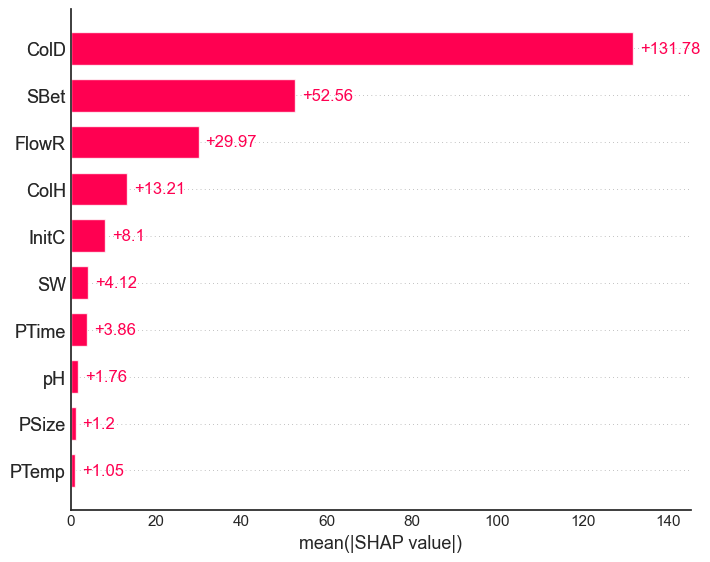

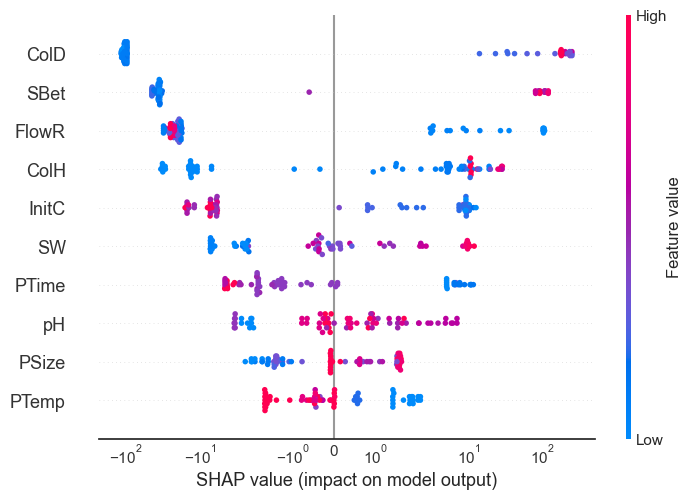

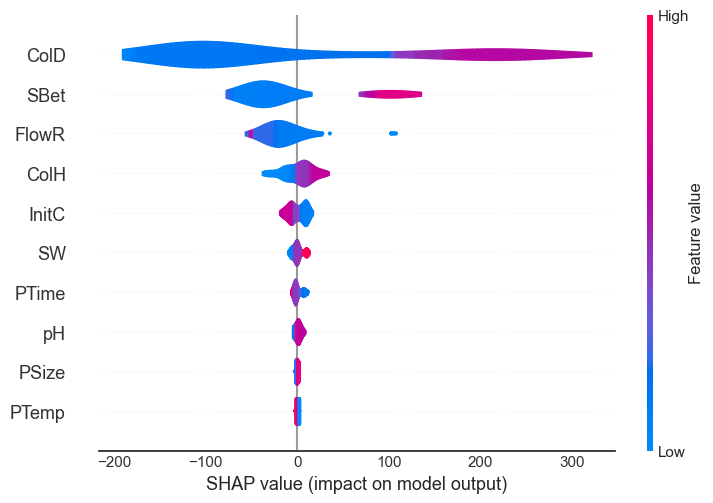

In [81]:
estimator = est
explainer = shap.Explainer(estimator, seed = 30, algorithm ='tree')
shap_values = explainer(X_train) 
ax=shap.plots.bar(shap_values, max_display=12, order=shap.Explanation.abs, show=True)
ax1=shap.plots.beeswarm(shap_values, max_display=12, log_scale=True)
ax2=shap.summary_plot(shap_values, X_train, plot_type="violin", color_bar_label='Feature value',layered_violin_max_num_bins=40)



In [82]:
# ===== Hyperparameter optimisation: b: GBR =====
DEFAULTS['b_GBR'] = dict(learning_rate=0.018, n_estimators=200, alpha=0.1, random_state=8, max_depth=6)   # original values (hand-set by the authors)
_X = df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW', 'ColD', 'ColH']]
_y = df['b']
_Xtr, _Xte, _ytr, _yte = train_test_split(_X, _y, test_size=0.15, random_state=71)   # same split as the training cell below
tune('b_GBR', GBR, 'gbr', _Xtr, _ytr)

[b_GBR] grid search: 3456 combinations x 10 CV fits = 34560 fits; rough estimate 9 min on 8 cores (the real time can be 1-3x of this)


[b_GBR] search finished in 54.3 min   CV r2: original -0.757 -> tuned 0.481
          {'alpha': 0.3, 'learning_rate': 0.1, 'loss': 'huber', 'max_depth': 2, 'max_features': 'sqrt', 'min_samples_leaf': 6, 'n_estimators': 100, 'subsample': 1.0}


In [83]:
X= df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW', 'ColD', 'ColH']]
y=df['b']
#-------------------------------------------------------------------------------------------------------------

for rs in [71]:                   # 41,71
    print('Random State: ', rs)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = rs) # Split the data

# Train the model on the training set
    est=GBR(**hp('b_GBR'))   # hyperparameters: see the tuning cell above
    est.fit(X_train, y_train)

# Make predictions on the testing set
    y_pred_test = est.predict(X_test).round(2)
    y_pred_train = est.predict(X_train).round(2)
          
    r2_a_train = r2_score(y_train, y_pred_train)
    r2_a_test = r2_score(y_test,   y_pred_test)
    CV5_scores = cross_val_score(est, X_train, y_train, cv=5)

    print('train: R2 score for predicting b coeff = ', round(r2_a_train, 3))
    print('test: R2 score for predicting b coeff = ', round(r2_a_test, 3))
    print('cv5: R2 score for predicting b coeff = ', CV5_scores.mean().round(3))
    print('---')
    
    #---------------------------------------------------------------------------------------------------------------
SCORES['b_GBR'] = dict(train=float(r2_a_train), test=float(r2_a_test), cv5=float(CV5_scores.mean()))
joblib.dump(est, 'GBR_dr_full.sav')

Random State:  71


train: R2 score for predicting b coeff =  0.547
test: R2 score for predicting b coeff =  0.606
cv5: R2 score for predicting b coeff =  0.384
---


['GBR_dr_full.sav']

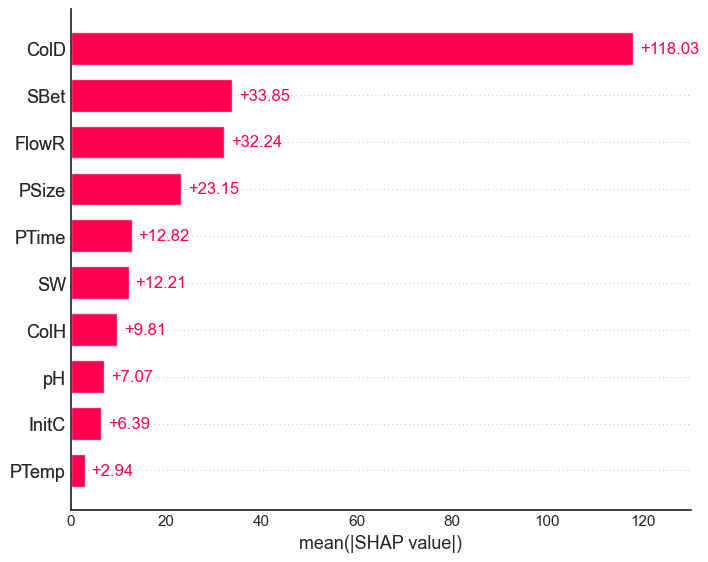

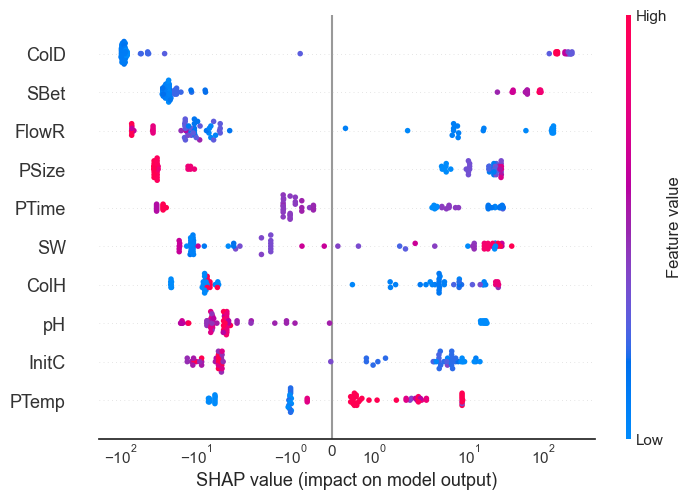

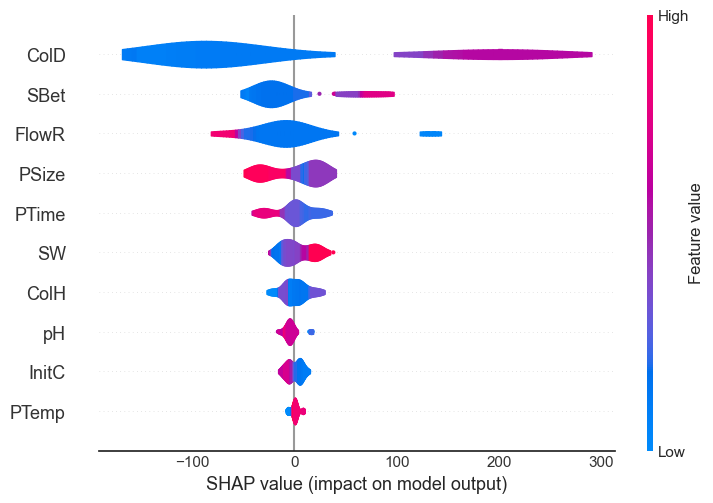

In [84]:
estimator = est
explainer = shap.Explainer(estimator, seed = 30, algorithm ='tree')
shap_values = explainer(X_train) 
ax=shap.plots.bar(shap_values, max_display=12, order=shap.Explanation.abs, show=True)
ax1=shap.plots.beeswarm(shap_values, max_display=12, log_scale=True)
ax2=shap.summary_plot(shap_values, X_train, plot_type="violin", color_bar_label='Feature value',layered_violin_max_num_bins=40)


In [85]:
# ===== Hyperparameter optimisation: b: RFR =====
DEFAULTS['b_RF'] = dict(n_estimators=500, max_depth=7, min_samples_leaf=1,criterion='squared_error', random_state=3)   # original values (hand-set by the authors)
_X = df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW', 'ColD', 'ColH']]
_y = df['b']
_Xtr, _Xte, _ytr, _yte = train_test_split(_X, _y, test_size=0.15, random_state=71)   # same split as the training cell below
tune('b_RF', RF, 'rf', _Xtr, _ytr)

[b_RF] grid search: 960 combinations x 10 CV fits = 9600 fits; rough estimate 12 min on 8 cores (the real time can be 1-3x of this)


[b_RF] search finished in 29.4 min   CV r2: original -0.339 -> tuned 0.236
          {'bootstrap': True, 'max_depth': 3, 'max_features': 0.7, 'min_samples_leaf': 10, 'min_samples_split': 6, 'n_estimators': 400}


In [86]:

X= df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW', 'ColD', 'ColH']]
y=df['b']
#-------------------------------------------------------------------------------------------------------------

for rs in [71]:                   # ,201,248,3,13,43,48,71
    print('Random State: ', rs)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = rs) # Split the data

# Train the model on the training set
#    est=GBR(learning_rate=0.0235, n_estimators=260, alpha=0.1, random_state=10, max_depth=5 )
#    est=XGBR(learning_rate =0.012, n_estimators=340, reg_alpha=0.071, reg_lambda=0.04, max_depth =6, random_state =5)
    est=RF(**hp('b_RF'))   # hyperparameters: see the tuning cell above
#    est = KNN(n_neighbors=3, leaf_size=20)
#    est=MLPRegressor(hidden_layer_sizes=(600, 80), activation='relu', solver='adam', max_iter=10000, random_state=0)
    
    est.fit(X_train, y_train)

# Make predictions on the testing set
    y_pred_test = est.predict(X_test).round(2)
    y_pred_train = est.predict(X_train).round(2)
          
    r2_a_train = r2_score(y_train, y_pred_train)
    r2_a_test = r2_score(y_test,   y_pred_test)
    CV5_scores = cross_val_score(est, X_train, y_train, cv=5)

    print('train: R2 score for predicting b coeff = ', round(r2_a_train, 3))
    print('test: R2 score for predicting b coeff = ', round(r2_a_test, 3))
    print('cv5: R2 score for predicting b coeff = ', CV5_scores.mean().round(3))
    print('---')
    
    #---------------------------------------------------------------------------------------------------------------
SCORES['b_RF'] = dict(train=float(r2_a_train), test=float(r2_a_test), cv5=float(CV5_scores.mean()))
joblib.dump(est, 'RFR_dr_full.sav')

Random State:  71


train: R2 score for predicting b coeff =  0.504
test: R2 score for predicting b coeff =  0.57
cv5: R2 score for predicting b coeff =  0.304
---


['RFR_dr_full.sav']

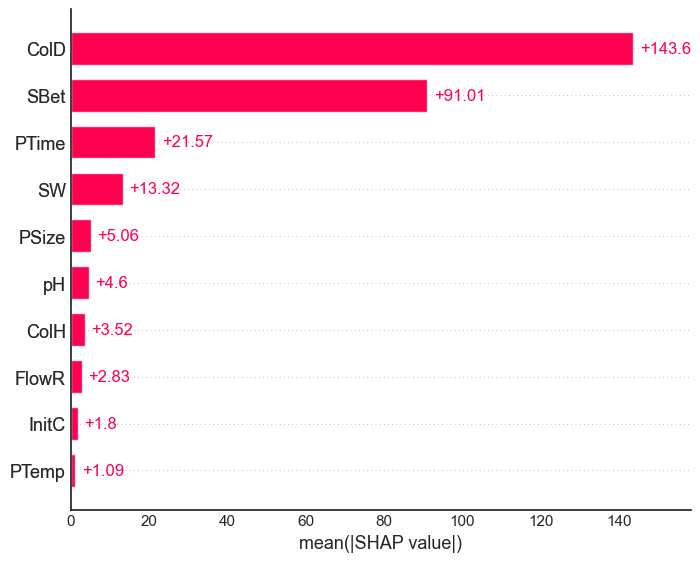

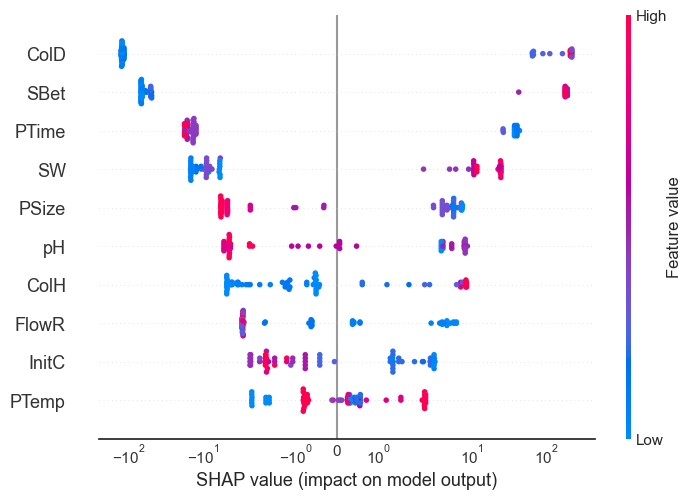

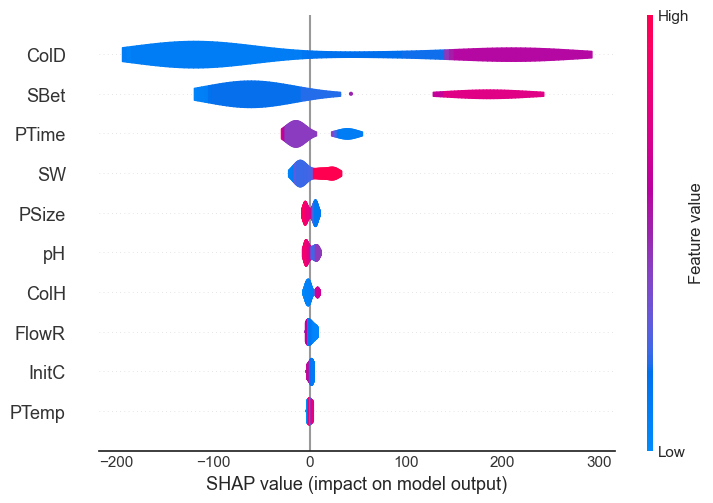

In [87]:
estimator = est
explainer = shap.Explainer(estimator, seed = 30, algorithm ='tree')
shap_values = explainer(X_train) 
ax=shap.plots.bar(shap_values, max_display=12, order=shap.Explanation.abs, show=True)
ax1=shap.plots.beeswarm(shap_values, max_display=12, log_scale=True)
ax2=shap.summary_plot(shap_values, X_train, plot_type="violin", color_bar_label='Feature value',layered_violin_max_num_bins=40)


In [88]:
XGBR_M=joblib.load('XGBR_dr_full.sav')
GBR_M= joblib.load('GBR_dr_full.sav')
RFR_M= joblib.load('RFR_dr_full.sav')

# ploting accuracy

In [89]:
plt.style.use('seaborn-v0_8-white')
# Set the default text font size
plt.rc('font', size=22)
# Set the fig title font size
plt.rc('axes', titlesize=22)
# Set the axes labels font size
plt.rc('axes', labelsize=2)
# Set the font size for x tick labels
plt.rc('xtick', labelsize=20)
# Set the font size for y tick labels
plt.rc('ytick', labelsize=20)
# Set the legend font size
plt.rc('legend', fontsize=22)
# Set the font size of the figure title
plt.rc('figure', titlesize=22)

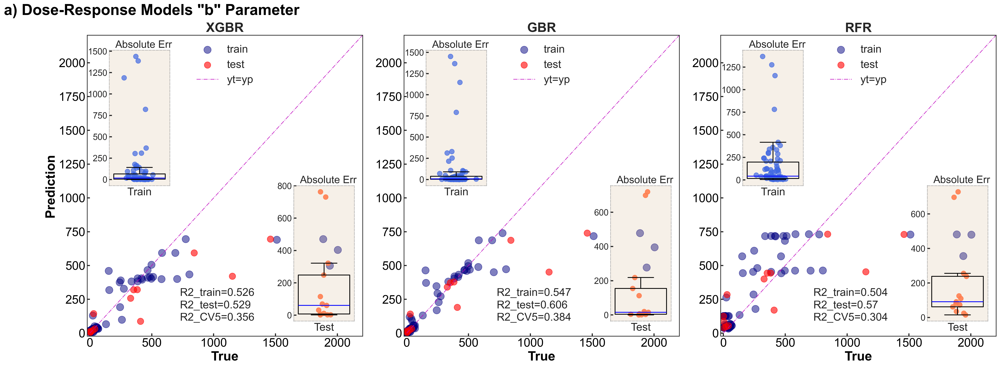

In [90]:
import matplotlib.gridspec as gridspec
 
fontdict1={'fontsize': 12, 'fontweight': 'bold', 'fontfamily': 'arial'}
fontdict2={'fontsize': 24, 'fontweight': 'bold', 'color': 'k', 'fontfamily': 'arial'}
rs=[71,71,71]
XGBR=joblib.load('XGBR_dr_full.sav')
GBR= joblib.load('GBR_dr_full.sav')
RFR= joblib.load('RFR_dr_full.sav')

yp_train_XGBR= XGBR.predict(X_train)
yp_train_GBR= GBR.predict(X_train)
yp_train_RFR= RFR.predict(X_train)

yp_test_XGBR= XGBR.predict(X_train)
yp_test_GBR= GBR.predict(X_train)
yp_test_RFR= RFR.predict(X_train)

fig = plt.figure(figsize=(30,10), dpi=300)
gs  = gridspec.GridSpec(1, 3, wspace=0.15, hspace=0.1, width_ratios=[1, 1, 1], height_ratios=[1])
modelsName=['XGBR', 'GBR', 'RFR']
LIM = 1.1*float(np.max(y))   # axis limit follows the data

YP_train=[yp_train_XGBR,yp_train_GBR,yp_train_RFR]

j=0
for i in range(0,3):
    ax = fig.add_subplot(gs[0,j])
    #------------------------------------------------ Data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = rs[i])
    yp_train_XGBR= XGBR.predict(X_train)
    yp_train_GBR= GBR.predict(X_train)
    yp_train_RFR= RFR.predict(X_train)

    yp_test_XGBR= XGBR.predict(X_test)
    yp_test_GBR= GBR.predict(X_test)
    yp_test_RFR= RFR.predict(X_test)
    YP_train=[yp_train_XGBR, yp_train_GBR, yp_train_RFR]
    YP_test=[yp_test_XGBR, yp_test_GBR, yp_test_RFR]
    
    ax.scatter(y_train, YP_train[i], s=180, color='navy',label='train', alpha=0.5)
    ax.scatter(y_test, YP_test[i], s=140, color='r',label='test', alpha=0.6)
    ax.plot([0, LIM], [0, LIM], 'k-.', lw=1.2, label='yt=yp', alpha=.8, color='m')

    #-----------------------------------------------------------------------------------
    ax2=ax.inset_axes([0.08, .50, 0.22, 0.45])
    ax2.set_xticks([])
    ax2.tick_params(axis='y', labelsize=16)
    ax2.spines[['top', 'bottom','right', 'left' ]].set_color('gray')
    ax2.spines[['top', 'bottom','right', 'left' ]].set_linestyle('--')
    ax2.spines[['top', 'bottom','right', 'left' ]].set_alpha(0.5)
    ax2.set_facecolor('tan')
    ax2.patch.set_alpha(0.2)
    #--------------------------------------------
    # calculate the train eroors
    err_train=abs(y_train-YP_train[i]).round(3)
    #--------------------------------------------
    ax2.boxplot(err_train, widths=0.85,tick_labels=['Train'], meanline =True,vert=True,
                showfliers = False,
                medianprops = {"color": "b", "linewidth": 1.5},
                boxprops = {"color": "k", "linewidth": 1.5},
                whiskerprops = {"color": "k", "linewidth": 1.5},
                capprops = {"color": "k", "linewidth": 1.5})
    xs, names = [], []
    vals=np.asanyarray(err_train)
    #names.append(col)
    xs.append(np.random.normal(1, 0.1, len(err_train)))
    ax2.scatter(xs,err_train, alpha= 0.7, marker='o', s=80, color='royalblue')
    ax2.text(0.6, 1.07*max(err_train), 'Absolute Err', fontsize = 19)
    #-----------------------------------------------------------------------------------------
    #-----------------------------------------------------------------------------------------
    ax3=ax.inset_axes([0.75, .05, 0.22, 0.45])
    ax3.tick_params(axis='y', labelsize=16)
    ax3.set_xticks([])
    ax3.spines[['top', 'bottom','right', 'left' ]].set_color('gray')
    ax3.spines[['top', 'bottom','right', 'left' ]].set_linestyle('--')
    ax3.spines[['top', 'bottom','right', 'left' ]].set_alpha(0.5)
    ax3.set_facecolor('tan')
    ax3.patch.set_alpha(0.2)
    #--------------------------------------------
    # calculate the train eroors
    err_test=abs(y_test-YP_test[i]).round(3)
    #--------------------------------------------
    ax3.boxplot(err_test, widths=0.85,tick_labels=['Test'], meanline =True,vert=True,
                showfliers = False,
                medianprops = {"color": "b", "linewidth": 1.5},
                boxprops = {"color": "k", "linewidth": 1.5},
                whiskerprops = {"color": "k", "linewidth": 1.5},
                capprops = {"color": "k", "linewidth": 1.5})
    xs, names = [], []
    vals=np.asanyarray(err_train)
    #names.append(col)
    xs.append(np.random.normal(1, 0.1, len(err_test)))
    ax3.scatter(xs,err_test, alpha= 0.9, marker='o', s=80, color='coral')
    ax3.text(0.6, 1.07*max(err_test), 'Absolute Err', fontsize = 19)
    #------------------------------------------------------------------------------------------
    #------------------------------------------------------------------------------------------

    ax.set_xlim([-0.01*LIM, LIM])
    ax.set_ylim([-0.01*LIM, LIM])
    ax.set_xlabel('True', fontdict=fontdict2)
    if j==0:
        ax.set_ylabel('Prediction', fontdict=fontdict2)
    ax.set_title(modelsName[j]  , loc= 'center', fontdict = fontdict1, fontsize=24)
    ax.tick_params(labelcolor='k', labelsize='medium', width=3)
    ax.legend(loc= 'upper center', fontsize=20)
    ax.tick_params(axis='x', which='both', direction='in', length=5, width=2)
    ax.tick_params(axis='y', which='both', direction='in', length=5, width=2)
    ax2.tick_params(axis='y', which='both', direction='in', length=5, width=2)
    ax3.tick_params(axis='y', which='both', direction='in', length=5, width=2)
    #------------------------------------------------------------------------------------------
    _models=[XGBR, GBR, RFR]
    R2TR=['R2_train='+str(round(r2_score(y_train, m.predict(X_train)), 3)) for m in _models]
    R2TE=['R2_test='+str(round(r2_score(y_test, m.predict(X_test)), 3)) for m in _models]
    CV5R2=['R2_CV5='+str(round(cross_val_score(m, X_train, y_train, cv=5).mean(), 3)) for m in _models]
    ax.text(0.33*LIM, 0.125*LIM, R2TR[j], fontsize = 20)
    ax.text(0.33*LIM, 0.083*LIM,  R2TE[j], fontsize = 20)
    ax.text(0.33*LIM, 0.042*LIM,  CV5R2[j], fontsize = 20)
    j=j+1
fig.suptitle('a) Dose-Response Models "b" Parameter', fontsize=28, fontweight='bold', color='k', x=.18, y=0.96)
plt.savefig('dr_b_errors_full', dpi=300)
plt.show()

In [91]:
b_xgbr=XGBR_M.predict(X)
b_gbr=GBR_M.predict(X)
b_rfr=RFR_M.predict(X)

In [92]:
Results_df['b_xgbr']=0.0
Results_df['b_gbr']=0.0
Results_df['b_rfr']=0.0
for i in range(0, len(Results_df)):
    Results_df.iat[i, Results_df.columns.get_loc('b_xgbr')] = float(b_xgbr[i].round(3))
    Results_df.iat[i, Results_df.columns.get_loc('b_gbr')] = float(b_gbr[i].round(3))
    Results_df.iat[i, Results_df.columns.get_loc('b_rfr')] = float(b_rfr[i].round(3))
Results_df.head(5)  

,pH,InitC,FlowR,PTemp,PTime,SBet,PSize,SW,ColD,ColH,...,T_gbr,T_rfr,K_pred,K_xgbr,K_gbr,K_rfr,K_pred_teor,b_xgbr,b_gbr,b_rfr
0,6.0,50.0,1.206642,600.0,60.0,154.25,0.25,0.3,16.998275,38.733061,...,221.878,385.272,271.542999,271.542999,268.083,386.650,162.260843,328.402008,272.281,481.532
1,6.0,50.0,0.600000,600.0,60.0,170.34,0.25,0.3,17.816205,38.679527,...,620.279,605.301,748.333008,748.333008,749.740,721.063,801.386751,696.081970,739.776,730.525
2,3.0,50.0,0.845751,600.0,60.0,170.34,0.25,0.3,30.367346,27.083182,...,542.600,606.695,448.511993,448.511993,436.681,543.619,296.366996,593.494019,687.342,732.325
3,4.0,50.0,0.845751,600.0,60.0,170.34,0.25,0.3,30.367346,27.083182,...,542.600,606.695,453.289001,453.289001,436.681,547.076,338.349855,593.494019,687.342,732.325
4,5.0,50.0,0.845751,600.0,60.0,170.34,0.25,0.3,30.367346,27.083182,...,542.600,606.695,401.628998,401.628998,436.512,547.375,385.735096,593.494019,687.342,732.325


# Finding a

In [93]:
def dose_response(t, a, b):
    return (1-1/(1+(t/b)**(a)))

def Gompertz(t, K, T):
    return (np.exp(-1*np.exp((1/K)*(T-t))))

In [94]:
# ===== Hyperparameter optimisation: a: RFR =====
DEFAULTS['a_RF'] = dict(n_estimators=300, max_depth=8, min_samples_leaf=1,criterion='squared_error', random_state=14)   # original values (hand-set by the authors)
_X = df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW', 'ColD', 'ColH','b']]
_y = df['a']
_Xtr, _Xte, _ytr, _yte = train_test_split(_X, _y, test_size=0.15, random_state=71)   # same split as the training cell below
tune('a_RF', RF, 'rf', _Xtr, _ytr)

[a_RF] grid search: 960 combinations x 10 CV fits = 9600 fits; rough estimate 11 min on 8 cores (the real time can be 1-3x of this)


[a_RF] search finished in 26.3 min   CV r2: original 0.520 -> tuned 0.606
          {'bootstrap': False, 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 400}


In [95]:
from xgboost import XGBRegressor as XGBR
X= df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW', 'ColD', 'ColH','b']]
y=df['a']


#-------------------------------------------------------------------------------------------------------------

for rs in [71]:                   # ,201,248,3,13,43,48,71
    print('Random State: ', rs)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = rs) # Split the data

# Train the model on the training set
#    est=GBR(learning_rate=0.0235, n_estimators=260, alpha=0.1, random_state=10, max_depth=5 )
#    est=XGBR(learning_rate =0.012, n_estimators=350, reg_alpha=0.12, reg_lambda=0.06, max_depth =7, random_state =5)
    est=RF(**hp('a_RF'))   # hyperparameters: see the tuning cell above

    
    est.fit(X_train, y_train)

# Make predictions on the testing set
    y_pred_test = est.predict(X_test).round(2)
    y_pred_train = est.predict(X_train).round(2)
    
       
    r2_a_train = r2_score(y_train, y_pred_train)
    r2_a_test = r2_score(y_test,   y_pred_test)
    CV5_scores = cross_val_score(est, X_train, y_train, cv=4)

    print('train: R2 score for predicting a coeff = ', round(r2_a_train, 3))
    print('test: R2 score for predicting a coeff = ', round(r2_a_test, 3))
    print('cv5: R2 score for predicting a coeff = ', CV5_scores.mean().round(3))
    print('---')
    
    #---------------------------------------------------------------------------------------------------------------
SCORES['a_RF'] = dict(train=float(r2_a_train), test=float(r2_a_test), cv5=float(CV5_scores.mean()))
joblib.dump(est, 'RFR_a_dr_full.sav')

Random State:  71


train: R2 score for predicting a coeff =  0.997
test: R2 score for predicting a coeff =  0.576
cv5: R2 score for predicting a coeff =  0.656
---


['RFR_a_dr_full.sav']

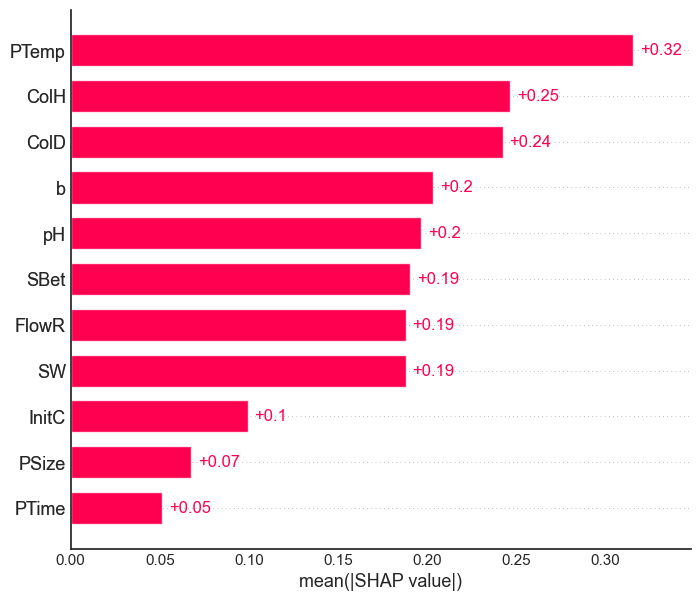

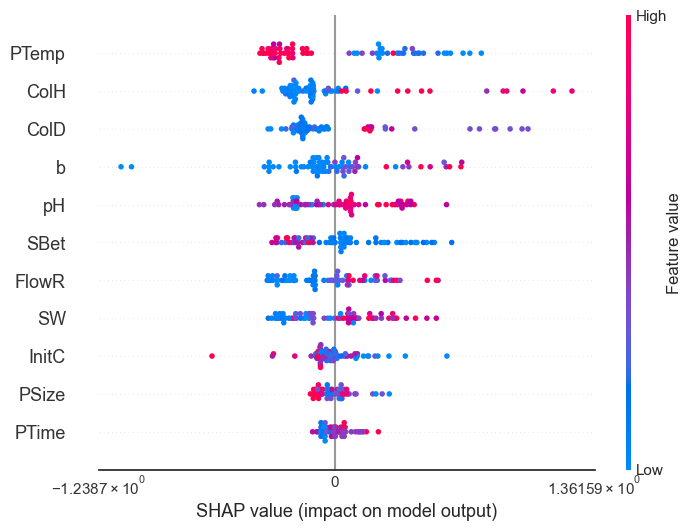

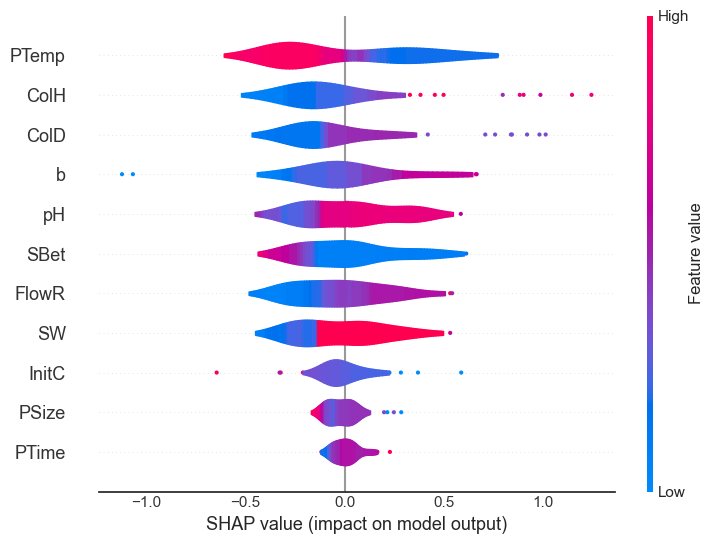

In [96]:
estimator = est
explainer = shap.Explainer(estimator, seed = 30, algorithm ='tree')
shap_values = explainer(X_train) 
ax=shap.plots.bar(shap_values, max_display=12, order=shap.Explanation.abs, show=True)
ax1=shap.plots.beeswarm(shap_values, max_display=12, log_scale=True)
ax2=shap.summary_plot(shap_values, X_train, plot_type="violin", color_bar_label='Feature value',layered_violin_max_num_bins=40)


# XGBR

In [97]:
# (the plot cell above uses the names XGBR / GBR for loaded models, so the classes are imported again)
from xgboost import XGBRegressor as XGBR
from sklearn.ensemble import GradientBoostingRegressor as GBR
from sklearn.ensemble import RandomForestRegressor as RF

In [98]:
# ===== Hyperparameter optimisation: a: XGBR =====
DEFAULTS['a_XGBR'] = dict(learning_rate =0.012, n_estimators=350, reg_alpha=0.12, reg_lambda=0.06, max_depth =7, random_state =5, tree_method='exact', base_score=0.5)   # original values
_X = df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW', 'ColD', 'ColH','b']]
_y = df['a']
_Xtr, _Xte, _ytr, _yte = train_test_split(_X, _y, test_size=0.15, random_state=71)   # same split as the training cell below
tune('a_XGBR', XGBR, 'xgb', _Xtr, _ytr)

[a_XGBR] grid search: 16200 combinations x 10 CV fits = 162000 fits; rough estimate 68 min on 8 cores (the real time can be 1-3x of this)


[a_XGBR] search finished in 46.8 min   CV r2: original 0.398 -> tuned 0.592
          {'colsample_bytree': 0.5, 'learning_rate': 0.02, 'max_depth': 8, 'min_child_weight': 1, 'n_estimators': 700, 'reg_alpha': 0.01, 'reg_lambda': 0.1, 'subsample': 0.8}


In [99]:

X= df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW', 'ColD', 'ColH','b']]
y=df['a']
#-------------------------------------------------------------------------------------------------------------

for rs in [71]:
    print('Random State: ', rs)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = rs) # Split the data

# Train the model on the training set
    est=XGBR(**hp('a_XGBR'))   # hyperparameters: see the tuning cell above
    est.fit(X_train, y_train)

# Make predictions on the testing set
    y_pred_test = est.predict(X_test).round(2)
    y_pred_train = est.predict(X_train).round(2)

    r2_a_train = r2_score(y_train, y_pred_train)
    r2_a_test = r2_score(y_test,   y_pred_test)
    CV5_scores = cross_val_score(est, X_train, y_train, cv=4)

    print('train: R2 score for predicting a coeff = ', round(r2_a_train, 3))
    print('test: R2 score for predicting a coeff = ', round(r2_a_test, 3))
    print('cv5: R2 score for predicting a coeff = ', CV5_scores.mean().round(3))
    print('---')

    #-------------------------------------------------------------------------------------------------------------
SCORES['a_XGBR'] = dict(train=float(r2_a_train), test=float(r2_a_test), cv5=float(CV5_scores.mean()))
joblib.dump(est, 'XGBR_a_dr_full.sav')

Random State:  71


train: R2 score for predicting a coeff =  1.0
test: R2 score for predicting a coeff =  0.577
cv5: R2 score for predicting a coeff =  0.628
---


['XGBR_a_dr_full.sav']

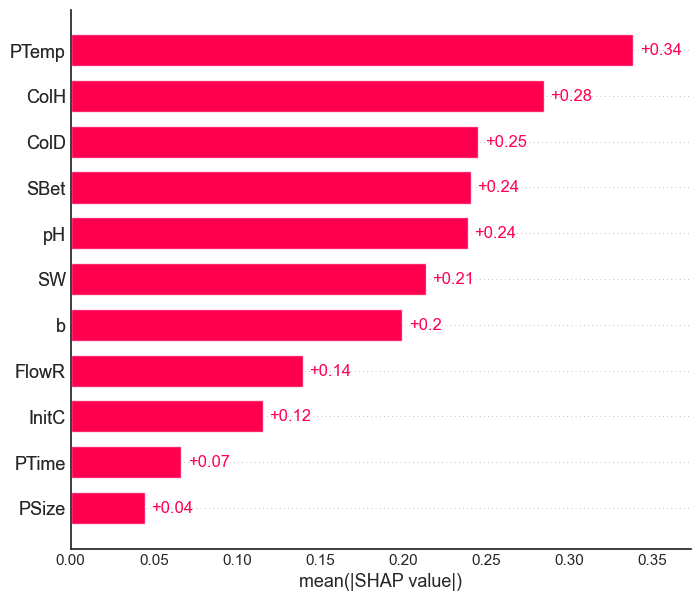

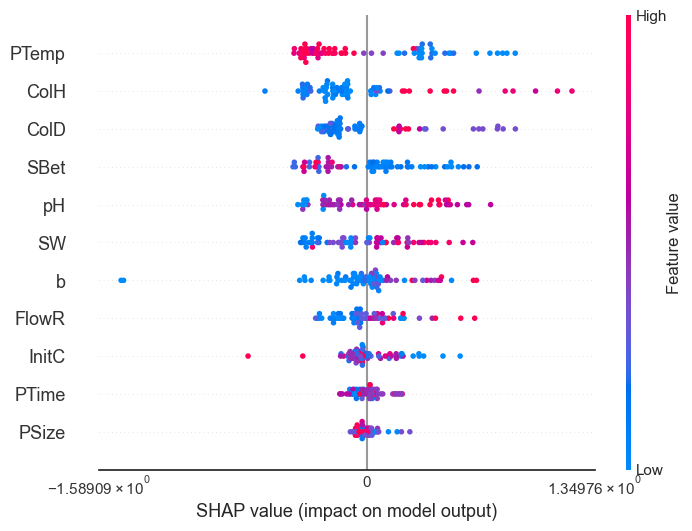

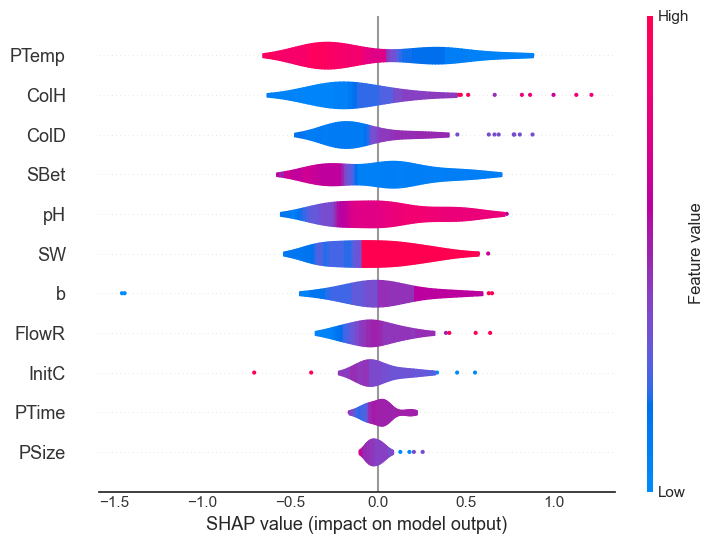

In [100]:
estimator = est
explainer = shap.Explainer(estimator, seed = 30, algorithm ='tree')
shap_values = explainer(X_train) 
ax=shap.plots.bar(shap_values, max_display=12, order=shap.Explanation.abs, show=True)
ax1=shap.plots.beeswarm(shap_values, max_display=12, log_scale=True)
ax2=shap.summary_plot(shap_values, X_train, plot_type="violin", color_bar_label='Feature value',layered_violin_max_num_bins=40)


# GBR

In [101]:
# ===== Hyperparameter optimisation: a: GBR =====
DEFAULTS['a_GBR'] = dict(learning_rate=0.0235, n_estimators=260, alpha=0.1, random_state=10, max_depth=5)   # original values
_X = df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW', 'ColD', 'ColH','b']]
_y = df['a']
_Xtr, _Xte, _ytr, _yte = train_test_split(_X, _y, test_size=0.15, random_state=71)   # same split as the training cell below
tune('a_GBR', GBR, 'gbr', _Xtr, _ytr)

[a_GBR] grid search: 3456 combinations x 10 CV fits = 34560 fits; rough estimate 22 min on 8 cores (the real time can be 1-3x of this)


[a_GBR] search finished in 44.3 min   CV r2: original 0.404 -> tuned 0.573
          {'learning_rate': 0.05, 'loss': 'squared_error', 'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 6, 'n_estimators': 200, 'subsample': 0.7}


In [102]:

X= df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW', 'ColD', 'ColH','b']]
y=df['a']
#-------------------------------------------------------------------------------------------------------------

for rs in [71]:
    print('Random State: ', rs)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = rs) # Split the data

# Train the model on the training set
    est=GBR(**hp('a_GBR'))   # hyperparameters: see the tuning cell above
    est.fit(X_train, y_train)

# Make predictions on the testing set
    y_pred_test = est.predict(X_test).round(2)
    y_pred_train = est.predict(X_train).round(2)

    r2_a_train = r2_score(y_train, y_pred_train)
    r2_a_test = r2_score(y_test,   y_pred_test)
    CV5_scores = cross_val_score(est, X_train, y_train, cv=4)

    print('train: R2 score for predicting a coeff = ', round(r2_a_train, 3))
    print('test: R2 score for predicting a coeff = ', round(r2_a_test, 3))
    print('cv5: R2 score for predicting a coeff = ', CV5_scores.mean().round(3))
    print('---')

    #-------------------------------------------------------------------------------------------------------------
SCORES['a_GBR'] = dict(train=float(r2_a_train), test=float(r2_a_test), cv5=float(CV5_scores.mean()))
joblib.dump(est, 'GBR_a_dr_full.sav')

Random State:  71


train: R2 score for predicting a coeff =  0.937
test: R2 score for predicting a coeff =  0.55
cv5: R2 score for predicting a coeff =  0.636
---


['GBR_a_dr_full.sav']

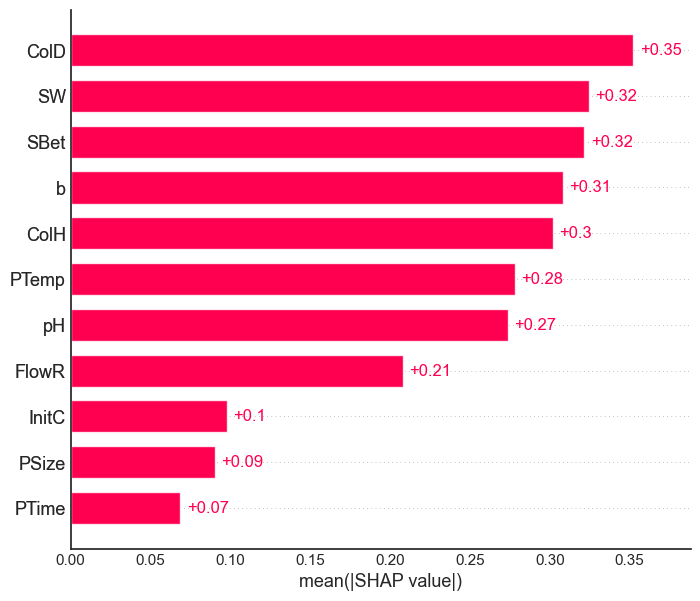

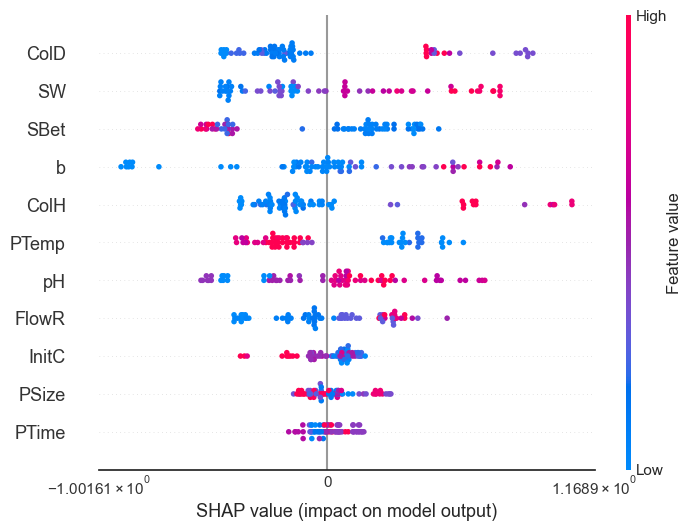

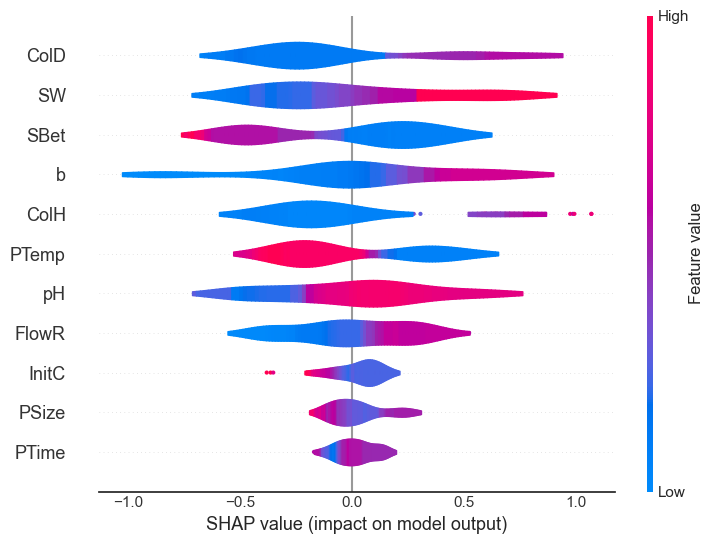

In [103]:
estimator = est
explainer = shap.Explainer(estimator, seed = 30, algorithm ='tree')
shap_values = explainer(X_train) 
ax=shap.plots.bar(shap_values, max_display=12, order=shap.Explanation.abs, show=True)
ax1=shap.plots.beeswarm(shap_values, max_display=12, log_scale=True)
ax2=shap.summary_plot(shap_values, X_train, plot_type="violin", color_bar_label='Feature value',layered_violin_max_num_bins=40)


In [104]:
RFR_a_dr=joblib.load('RFR_a_dr_full.sav')
a_pred=RFR_a_dr.predict(X)

Results_df['a_pred']=0.0
for i in range(0, len(Results_df)):
    Results_df.iat[i, Results_df.columns.get_loc('a_pred')] = float(a_pred[i].round(3))
Results_df

,pH,InitC,FlowR,PTemp,PTime,SBet,PSize,SW,ColD,ColH,...,T_rfr,K_pred,K_xgbr,K_gbr,K_rfr,K_pred_teor,b_xgbr,b_gbr,b_rfr,a_pred
0,6.0,50.00,1.206642,600.0,60.0,154.25,0.25,0.3,16.998275,38.733061,...,385.272,271.542999,271.542999,268.083,386.650,162.260843,328.402008,272.281,481.532,1.632
1,6.0,50.00,0.600000,600.0,60.0,170.34,0.25,0.3,17.816205,38.679527,...,605.301,748.333008,748.333008,749.740,721.063,801.386751,696.081970,739.776,730.525,3.833
2,3.0,50.00,0.845751,600.0,60.0,170.34,0.25,0.3,30.367346,27.083182,...,606.695,448.511993,448.511993,436.681,543.619,296.366996,593.494019,687.342,732.325,2.150
3,4.0,50.00,0.845751,600.0,60.0,170.34,0.25,0.3,30.367346,27.083182,...,606.695,453.289001,453.289001,436.681,547.076,338.349855,593.494019,687.342,732.325,2.133
4,5.0,50.00,0.845751,600.0,60.0,170.34,0.25,0.3,30.367346,27.083182,...,606.695,401.628998,401.628998,436.512,547.375,385.735096,593.494019,687.342,732.325,2.447
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,5.9,112.41,15.000000,350.0,150.0,72.70,0.46,6.8,6.000000,300.000000,...,110.811,1.774000,1.774000,1.109,3.742,5.110461,19.143000,0.233,125.891,3.899
80,5.9,224.82,15.000000,350.0,150.0,72.70,0.46,6.8,6.000000,300.000000,...,110.811,0.679000,0.679000,1.109,3.841,4.855845,18.587000,0.233,125.891,0.623
81,5.9,112.41,15.000000,350.0,150.0,72.70,0.46,2.5,6.000000,100.000000,...,73.968,-0.012000,-0.012000,1.917,4.821,5.315801,6.680000,4.497,84.816,2.661
82,5.9,112.41,15.000000,350.0,150.0,72.70,0.46,4.5,6.000000,200.000000,...,110.257,3.224000,3.224000,1.917,4.417,4.336962,11.987000,15.946,125.307,1.130


In [105]:
# predictions of the three a models (a_pred above is the original RFR column)
XGBR_a = joblib.load('XGBR_a_dr_full.sav'); GBR_a = joblib.load('GBR_a_dr_full.sav'); RFR_a = joblib.load('RFR_a_dr_full.sav')
Results_df['a_xgbr'] = XGBR_a.predict(X).round(3)
Results_df['a_gbr'] = GBR_a.predict(X).round(3)
Results_df['a_rfr'] = RFR_a.predict(X).round(3)

In [106]:
Results_df.to_pickle('Results_df2_full.pkl')

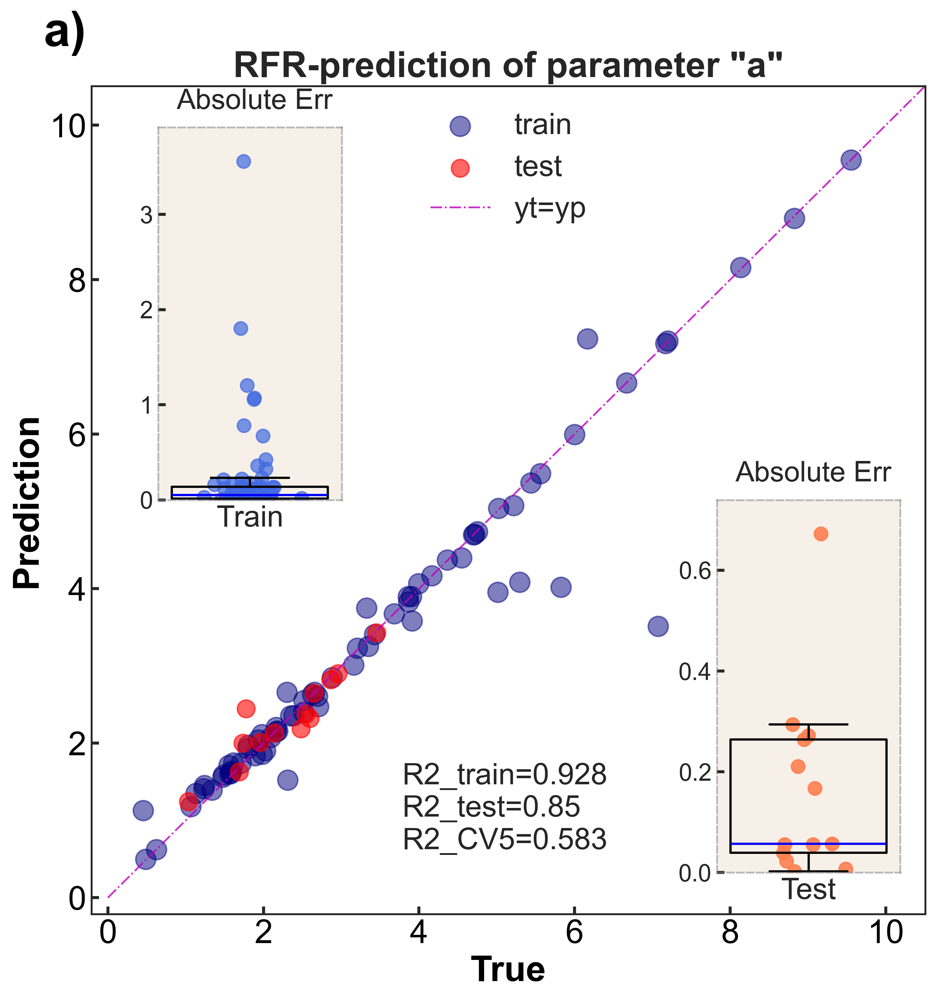

In [107]:
import matplotlib.gridspec as gridspec
 
fontdict1={'fontsize': 12, 'fontweight': 'bold', 'fontfamily': 'arial'}
fontdict2={'fontsize': 24, 'fontweight': 'bold', 'color': 'k', 'fontfamily': 'arial'}
rs=[60]
LIM = 1.1*float(np.max(y))   # axis limit follows the data

RFR= joblib.load('RFR_a_dr_full.sav')


yp_train_RFR= RFR.predict(X_train)
yp_test_RFR= RFR.predict(X_train)

fig = plt.figure(figsize=(10,10), dpi=300)
gs  = gridspec.GridSpec(1, 1, wspace=0.15, hspace=0.1, width_ratios=[1], height_ratios=[1])
modelsName=['RFR-prediction of parameter "a"']

YP_train=[yp_train_RFR]

j=0
for i in range(0,1):
    ax = fig.add_subplot(gs[0,j])
    #------------------------------------------------ Data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = rs[i])

    yp_train_RFR= RFR.predict(X_train)
    yp_test_RFR= RFR.predict(X_test)
    YP_train=[yp_train_RFR]
    YP_test=[yp_test_RFR]
    
    ax.scatter(y_train, YP_train[i], s=180, color='navy',label='train', alpha=0.5)
    ax.scatter(y_test, YP_test[i], s=140, color='r',label='test', alpha=0.6)
    ax.plot([0, LIM], [0, LIM], 'k-.', lw=1.2, label='yt=yp', alpha=.8, color='m')

    #-----------------------------------------------------------------------------------
    ax2=ax.inset_axes([0.08, .50, 0.22, 0.45])
    ax2.set_xticks([])
    ax2.tick_params(axis='y', labelsize=16)
    ax2.spines[['top', 'bottom','right', 'left' ]].set_color('gray')
    ax2.spines[['top', 'bottom','right', 'left' ]].set_linestyle('--')
    ax2.spines[['top', 'bottom','right', 'left' ]].set_alpha(0.5)
    ax2.set_facecolor('tan')
    ax2.patch.set_alpha(0.2)
    #--------------------------------------------
    # calculate the train eroors
    err_train=abs(y_train-YP_train[i]).round(3)
    #--------------------------------------------
    ax2.boxplot(err_train, widths=0.85,tick_labels=['Train'], meanline =True,vert=True,
                showfliers = False,
                medianprops = {"color": "b", "linewidth": 1.5},
                boxprops = {"color": "k", "linewidth": 1.5},
                whiskerprops = {"color": "k", "linewidth": 1.5},
                capprops = {"color": "k", "linewidth": 1.5})
    xs, names = [], []
    vals=np.asanyarray(err_train)
    #names.append(col)
    xs.append(np.random.normal(1, 0.1, len(err_train)))
    ax2.scatter(xs,err_train, alpha= 0.7, marker='o', s=80, color='royalblue')
    ax2.text(0.6, 1.05*(1.1*max(err_train)), 'Absolute Err', fontsize = 19)
    ax2.set_ylim([0, 1.1*max(err_train)])
    #-----------------------------------------------------------------------------------------
    #-----------------------------------------------------------------------------------------
    ax3=ax.inset_axes([0.75, .05, 0.22, 0.45])
    ax3.tick_params(axis='y', labelsize=16)
    ax3.set_xticks([])
    ax3.spines[['top', 'bottom','right', 'left' ]].set_color('gray')
    ax3.spines[['top', 'bottom','right', 'left' ]].set_linestyle('--')
    ax3.spines[['top', 'bottom','right', 'left' ]].set_alpha(0.5)
    ax3.set_facecolor('tan')
    ax3.patch.set_alpha(0.2)
    #--------------------------------------------
    # calculate the train eroors
    err_test=abs(y_test-YP_test[i]).round(3)
    #--------------------------------------------
    ax3.boxplot(err_test, widths=0.85,tick_labels=['Test'], meanline =True,vert=True,
                showfliers = False,
                medianprops = {"color": "b", "linewidth": 1.5},
                boxprops = {"color": "k", "linewidth": 1.5},
                whiskerprops = {"color": "k", "linewidth": 1.5},
                capprops = {"color": "k", "linewidth": 1.5})
    xs, names = [], []
    vals=np.asanyarray(err_train)
    #names.append(col)
    xs.append(np.random.normal(1, 0.1, len(err_test)))
    ax3.scatter(xs,err_test, alpha= 0.9, marker='o', s=80, color='coral')
    ax3.text(0.6, 1.05*(1.1*max(err_test)), 'Absolute Err', fontsize = 19)
    ax3.set_ylim([0, 1.1*max(err_test)])
    
    #------------------------------------------------------------------------------------------
    #------------------------------------------------------------------------------------------

    ax.set_xlim([-0.02*LIM, LIM])
    ax.set_ylim([-0.02*LIM, LIM])
    ax.set_xlabel('True', fontdict=fontdict2)
    if j==0:
        ax.set_ylabel('Prediction', fontdict=fontdict2)
    ax.set_title(modelsName[j]  , loc= 'center', fontdict = fontdict1, fontsize=24)
    ax.tick_params(labelcolor='k', labelsize='medium', width=3)
    ax.legend(loc= 'upper center', fontsize=20)
    ax.tick_params(axis='x', which='both', direction='in', length=5, width=2)
    ax.tick_params(axis='y', which='both', direction='in', length=5, width=2)
    ax2.tick_params(axis='y', which='both', direction='in', length=5, width=2)
    ax3.tick_params(axis='y', which='both', direction='in', length=5, width=2)
    #------------------------------------------------------------------------------------------

    ax.text(0.36*LIM, 0.14*LIM, 'R2_train='+str(round(r2_score(y_train, RFR.predict(X_train)), 3)), fontsize = 20)
    ax.text(0.36*LIM, 0.10*LIM,  'R2_test='+str(round(r2_score(y_test, RFR.predict(X_test)), 3)), fontsize = 20)
    ax.text(0.36*LIM, 0.06*LIM,  'R2_CV5='+str(round(cross_val_score(RFR, X_train, y_train, cv=5).mean(), 3)), fontsize = 20)
    j=j+1
fig.suptitle('a)', fontsize=32, fontweight='bold', color='k', x=.1, y=0.95)
plt.savefig('dr_a_errors_full', dpi=300)
plt.show()

# plotting accuracy (all three models) - a

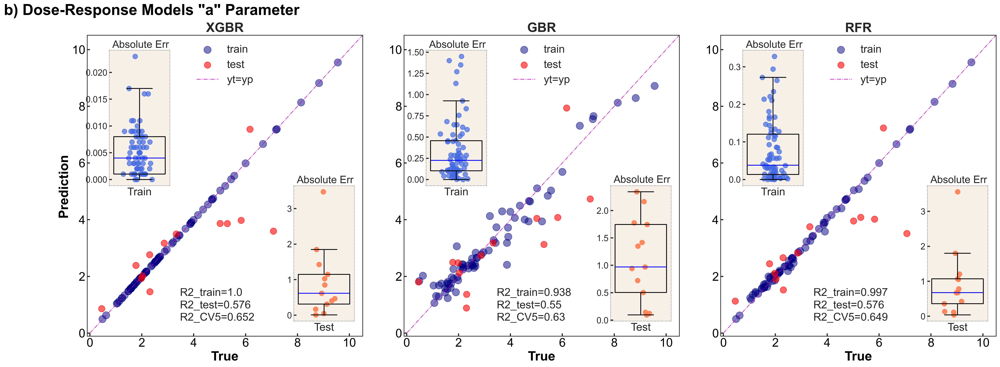

In [108]:
import matplotlib.gridspec as gridspec
 
fontdict1={'fontsize': 12, 'fontweight': 'bold', 'fontfamily': 'arial'}
fontdict2={'fontsize': 24, 'fontweight': 'bold', 'color': 'k', 'fontfamily': 'arial'}
rs=[71,71,71]
X = df[['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW', 'ColD', 'ColH','b']]
y = df['a']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = 71)
XGBR_M=joblib.load('XGBR_a_dr_full.sav')
GBR_M= joblib.load('GBR_a_dr_full.sav')
RFR_M= joblib.load('RFR_a_dr_full.sav')

yp_train_XGBR= XGBR_M.predict(X_train)
yp_train_GBR= GBR_M.predict(X_train)
yp_train_RFR= RFR_M.predict(X_train)

yp_test_XGBR= XGBR_M.predict(X_train)
yp_test_GBR= GBR_M.predict(X_train)
yp_test_RFR= RFR_M.predict(X_train)

fig = plt.figure(figsize=(30,10), dpi=300)
gs  = gridspec.GridSpec(1, 3, wspace=0.15, hspace=0.1, width_ratios=[1, 1, 1], height_ratios=[1])
modelsName=['XGBR', 'GBR', 'RFR']
LIM = 1.1*float(np.max(y))   # axis limit follows the data

YP_train=[yp_train_XGBR,yp_train_GBR,yp_train_RFR]

j=0
for i in range(0,3):
    ax = fig.add_subplot(gs[0,j])
    #------------------------------------------------ Data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = rs[i])
    yp_train_XGBR= XGBR_M.predict(X_train)
    yp_train_GBR= GBR_M.predict(X_train)
    yp_train_RFR= RFR_M.predict(X_train)

    yp_test_XGBR= XGBR_M.predict(X_test)
    yp_test_GBR= GBR_M.predict(X_test)
    yp_test_RFR= RFR_M.predict(X_test)
    YP_train=[yp_train_XGBR, yp_train_GBR, yp_train_RFR]
    YP_test=[yp_test_XGBR, yp_test_GBR, yp_test_RFR]
    
    ax.scatter(y_train, YP_train[i], s=180, color='navy',label='train', alpha=0.5)
    ax.scatter(y_test, YP_test[i], s=140, color='r',label='test', alpha=0.6)
    ax.plot([0, LIM], [0, LIM], 'k-.', lw=1.2, label='yt=yp', alpha=.8, color='m')

    #-----------------------------------------------------------------------------------
    ax2=ax.inset_axes([0.08, .50, 0.22, 0.45])
    ax2.set_xticks([])
    ax2.tick_params(axis='y', labelsize=16)
    ax2.spines[['top', 'bottom','right', 'left' ]].set_color('gray')
    ax2.spines[['top', 'bottom','right', 'left' ]].set_linestyle('--')
    ax2.spines[['top', 'bottom','right', 'left' ]].set_alpha(0.5)
    ax2.set_facecolor('tan')
    ax2.patch.set_alpha(0.2)
    #--------------------------------------------
    # calculate the train eroors
    err_train=abs(y_train-YP_train[i]).round(3)
    #--------------------------------------------
    ax2.boxplot(err_train, widths=0.85,tick_labels=['Train'], meanline =True,vert=True,
                showfliers = False,
                medianprops = {"color": "b", "linewidth": 1.5},
                boxprops = {"color": "k", "linewidth": 1.5},
                whiskerprops = {"color": "k", "linewidth": 1.5},
                capprops = {"color": "k", "linewidth": 1.5})
    xs, names = [], []
    vals=np.asanyarray(err_train)
    #names.append(col)
    xs.append(np.random.normal(1, 0.1, len(err_train)))
    ax2.scatter(xs,err_train, alpha= 0.7, marker='o', s=80, color='royalblue')
    ax2.text(0.55, 1.07*max(err_train), 'Absolute Err', fontsize = 19)
    #-----------------------------------------------------------------------------------------
    #-----------------------------------------------------------------------------------------
    ax3=ax.inset_axes([0.75, .05, 0.22, 0.45])
    ax3.tick_params(axis='y', labelsize=16)
    ax3.set_xticks([])
    ax3.spines[['top', 'bottom','right', 'left' ]].set_color('gray')
    ax3.spines[['top', 'bottom','right', 'left' ]].set_linestyle('--')
    ax3.spines[['top', 'bottom','right', 'left' ]].set_alpha(0.5)
    ax3.set_facecolor('tan')
    ax3.patch.set_alpha(0.2)
    #--------------------------------------------
    # calculate the train eroors
    err_test=abs(y_test-YP_test[i]).round(3)
    #--------------------------------------------
    ax3.boxplot(err_test, widths=0.85,tick_labels=['Test'], meanline =True,vert=True,
                showfliers = False,
                medianprops = {"color": "b", "linewidth": 1.5},
                boxprops = {"color": "k", "linewidth": 1.5},
                whiskerprops = {"color": "k", "linewidth": 1.5},
                capprops = {"color": "k", "linewidth": 1.5})
    xs, names = [], []
    vals=np.asanyarray(err_train)
    #names.append(col)
    xs.append(np.random.normal(1, 0.1, len(err_test)))
    ax3.scatter(xs,err_test, alpha= 0.9, marker='o', s=80, color='coral')
    ax3.text(0.55, 1.07*max(err_test), 'Absolute Err', fontsize = 19)
    #------------------------------------------------------------------------------------------
    #------------------------------------------------------------------------------------------

    ax.set_xlim([-0.01*LIM, LIM])
    ax.set_ylim([-0.01*LIM, LIM])
    ax.set_xlabel('True', fontdict=fontdict2)
    if j==0:
        ax.set_ylabel('Prediction', fontdict=fontdict2)
    ax.set_title(modelsName[j]  , loc= 'center', fontdict = fontdict1, fontsize=24)
    ax.tick_params(labelcolor='k', labelsize='medium', width=3)
    ax.legend(loc= 'upper center', fontsize=20)
    ax.tick_params(axis='x', which='both', direction='in', length=5, width=2)
    ax.tick_params(axis='y', which='both', direction='in', length=5, width=2)
    ax2.tick_params(axis='y', which='both', direction='in', length=5, width=2)
    ax3.tick_params(axis='y', which='both', direction='in', length=5, width=2)
    #------------------------------------------------------------------------------------------
    _models=[XGBR_M, GBR_M, RFR_M]
    R2TR=['R2_train='+str(round(r2_score(y_train, m.predict(X_train)), 3)) for m in _models]
    R2TE=['R2_test='+str(round(r2_score(y_test, m.predict(X_test)), 3)) for m in _models]
    CV5R2=['R2_CV5='+str(round(cross_val_score(m, X_train, y_train, cv=5).mean(), 3)) for m in _models]
    ax.text(0.33*LIM, 0.125*LIM, R2TR[j], fontsize = 20)
    ax.text(0.33*LIM, 0.083*LIM,  R2TE[j], fontsize = 20)
    ax.text(0.33*LIM, 0.042*LIM,  CV5R2[j], fontsize = 20)
    j=j+1
fig.suptitle('b) Dose-Response Models "a" Parameter', fontsize=28, fontweight='bold', color='k', x=.18, y=0.96)
plt.savefig('dr_a_errors3_full', dpi=300)
plt.show()

---
# Step 4 - Final pipeline: the best model of every stage
The best model of each parameter (by cross-validation on the training part) is chained exactly as in the workflow: **T -> K** (K uses the predicted T) and **b -> a** (a uses the predicted b). The test part (13 samples) is evaluated with the same split as every model above.

In [109]:
# ===== STEP 4 - final pipeline: the best model of every stage =====
PICK_BY = 'cv5'      # how "best" is decided: 'cv5' = cross-validation on the training part (recommended, the test part is not used for choosing)
                     #                       'test' = R2 of the test part (only 13 samples: noisy, optimistic)   |   'train'
FILES = {
    'T': {'XGBR': ('T_XGBR', 'XGBR_G_full.sav'),      'GBR': ('T_GBR', 'GBR_G_full.sav'),      'RF': ('T_RF', 'RFR_G_full.sav')},
    'K': {'XGBR': ('K_XGBR', 'RFR_K_G_full.sav'),     'GBR': ('K_GBR', 'GBR_K_G_full.sav'),    'RF': ('K_RF', 'RFR_K_RF_full.sav')},
    'b': {'XGBR': ('b_XGBR', 'XGBR_dr_full.sav'),     'GBR': ('b_GBR', 'GBR_dr_full.sav'),     'RF': ('b_RF', 'RFR_dr_full.sav')},
    'a': {'XGBR': ('a_XGBR', 'XGBR_a_dr_full.sav'),   'GBR': ('a_GBR', 'GBR_a_dr_full.sav'),   'RF': ('a_RF', 'RFR_a_dr_full.sav')},
}
BEST = {}
for _p, _d in FILES.items():
    _sc = {m: SCORES[k][PICK_BY] for m, (k, f) in _d.items()}
    BEST[_p] = max(_sc, key=_sc.get)
    print(f"{_p}: " + ',  '.join(f"{m} {v:.3f}" for m, v in _sc.items()) + f"   ->  best ({PICK_BY}): {BEST[_p]}")
print()
print('Pipeline:  [features] -> T:', BEST['T'], ' -> K:', BEST['K'], '(uses predicted T)')
print('           [features] -> b:', BEST['b'], ' -> a:', BEST['a'], '(uses predicted b)')

T: XGBR 0.037,  GBR 0.264,  RF 0.251   ->  best (cv5): GBR
K: XGBR 0.883,  GBR 0.841,  RF 0.773   ->  best (cv5): XGBR
b: XGBR 0.356,  GBR 0.384,  RF 0.304   ->  best (cv5): GBR
a: XGBR 0.628,  GBR 0.636,  RF 0.656   ->  best (cv5): RF

Pipeline:  [features] -> T: GBR  -> K: XGBR (uses predicted T)
           [features] -> b: GBR  -> a: RF (uses predicted b)


In [110]:
# ===== STEP 4 - chains: one chain per model family (XGBR / GBR / RF at EVERY stage) and the chain of the best model of every stage =====
# In every chain K uses the PREDICTED T and a uses the PREDICTED b. The curve is rebuilt from the predicted parameters.
_idx = np.arange(len(df))
_tr, _te = train_test_split(_idx, test_size=0.15, random_state=71)        # exactly the same split as all models above
_te_set = set(_te)
F10 = ['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW', 'ColD', 'ColH']
FK  = ['pH', 'InitC', 'FlowR', 'PTemp', 'PTime', 'SBet', 'PSize', 'SW', 'T']
FA  = F10 + ['b']
_full = pd.read_pickle('df_coeff.pkl').reset_index(drop=True)
_BC = [(_full['Modified_BC'].iloc[i]['t'].values.astype(float), _full['Modified_BC'].iloc[i]['C'].values.astype(float)) for i in range(len(df))]
CHAINS = {'XGBR': {p: 'XGBR' for p in 'TKba'}, 'GBR': {p: 'GBR' for p in 'TKba'}, 'RF': {p: 'RF' for p in 'TKba'}, 'BEST': dict(BEST)}
_cats = [(-np.inf, 0.6, 'Low'), (0.6, 0.8, 'Medium'), (0.8, 0.9, 'High'), (0.9, np.inf, 'Very High')]     # the classes of the paper (Fig. 4)
par_rows, curve_rows, preds = [], [], {}
for cname, pick in CHAINS.items():
    M = {_p: joblib.load(FILES[_p][pick[_p]][1]) for _p in FILES}
    T_hat = M['T'].predict(df[F10]);  b_hat = M['b'].predict(df[F10])
    XK = df[FK].copy(); XK['T'] = T_hat;  K_hat = M['K'].predict(XK)
    Xa = df[FA].copy(); Xa['b'] = b_hat;  a_hat = M['a'].predict(Xa)
    pr = {'T': T_hat, 'K': K_hat, 'b': b_hat, 'a': a_hat};  preds[cname] = pr
    for _p in ['T', 'K', 'b', 'a']:
        _y = df[_p].values
        par_rows.append(dict(chain=cname, step1=STEP1_MODEL, parameter=_p, model=pick[_p], R2_train=r2_score(_y[_tr], pr[_p][_tr]),
                             R2_test=r2_score(_y[_te], pr[_p][_te]), MAE_test=float(np.abs(_y[_te] - pr[_p][_te]).mean())))
    for _p, _par in (('K', 'T'), ('a', 'b')):                                    # same model but with the TRUE T / b as input
        _o = M[_p].predict(df[FK] if _p == 'K' else df[FA]);  _y = df[_p].values
        par_rows.append(dict(chain=cname, step1=STEP1_MODEL, parameter=_p + ' (true ' + _par + ' as input)', model=pick[_p],
                             R2_train=r2_score(_y[_tr], _o[_tr]), R2_test=r2_score(_y[_te], _o[_te]), MAE_test=float(np.abs(_y[_te] - _o[_te]).mean())))
    for i in range(len(df)):
        t_, c_ = _BC[i]
        Gt = Gompertz(t_, df['K'].iloc[i], df['T'].iloc[i]);  Gp = Gompertz(t_, max(K_hat[i], 1e-6), T_hat[i])
        Dt = dose_response(t_, df['a'].iloc[i], df['b'].iloc[i]);  Dp = dose_response(t_, max(a_hat[i], 1e-6), max(b_hat[i], 1e-6))
        curve_rows.append(dict(chain=cname, step1=STEP1_MODEL, row=i, split='test' if i in _te_set else 'train',
                               R2_Gompertz_pred_vs_true=r2_score(Gt, Gp), R2_DoseResponse_pred_vs_true=r2_score(Dt, Dp),
                               R2_Gompertz_pred_vs_measured=r2_score(c_, Gp), R2_DoseResponse_pred_vs_measured=r2_score(c_, Dp)))
par = pd.DataFrame(par_rows);  cur = pd.DataFrame(curve_rows)
print('Pipeline of the best model of every stage:', BEST)
print('\nR2 of every parameter in every chain (K and a use the PREDICTED T and b unless written otherwise):')
print(par.round(3).to_string(index=False))
print('\nCurves rebuilt from the predicted parameters (median R2; "true" = curve from the fitted true parameters, as in Fig. 4 of the paper):')
print(cur.groupby(['chain', 'split'])[['R2_Gompertz_pred_vs_true', 'R2_DoseResponse_pred_vs_true',
                                       'R2_Gompertz_pred_vs_measured', 'R2_DoseResponse_pred_vs_measured']].median().round(3).to_string())
print('\nShare of curves in each accuracy class (R2 pred vs true curve), test part:')
_t = cur[cur.split == 'test']
for _f, _col in (('Gompertz', 'R2_Gompertz_pred_vs_true'), ('Dose-Response', 'R2_DoseResponse_pred_vs_true')):
    _tab = pd.DataFrame({ch: {n: 100 * ((g[_col] >= lo) & (g[_col] < hi)).mean() for lo, hi, n in _cats} for ch, g in _t.groupby('chain')}).round(1)
    print(_f, '(%)'); print(_tab.to_string())
par.to_csv(f'Chains_parameters_step1_{STEP1_MODEL}.csv', index=False)
cur.to_csv(f'Chains_curves_step1_{STEP1_MODEL}.csv', index=False)
_pp = pd.DataFrame({'row': _idx, 'split': np.where(np.isin(_idx, _te), 'test', 'train'), 'T': df['T'], 'K': df['K'], 'b': df['b'], 'a': df['a']})
for cname, pr in preds.items():
    for _p in 'TKba':
        _pp[f'{_p}_{cname}'] = pr[_p]
_pp.to_csv(f'Chains_predictions_step1_{STEP1_MODEL}.csv', index=False)
with open(f'SCORES_step1_{STEP1_MODEL}.json', 'w') as _f:
    json.dump({'step1_model': STEP1_MODEL, 'scores': SCORES, 'best_per_stage': BEST, 'pick_by': PICK_BY, 'tuned': TUNED}, _f, indent=1, default=str)
print('\nsaved: Chains_parameters/curves/predictions_step1_' + STEP1_MODEL + '.csv and SCORES_step1_' + STEP1_MODEL + '.json')

Pipeline of the best model of every stage: {'T': 'GBR', 'K': 'XGBR', 'b': 'GBR', 'a': 'RF'}

R2 of every parameter in every chain (K and a use the PREDICTED T and b unless written otherwise):
chain step1           parameter model  R2_train  R2_test  MAE_test
 XGBR   GBR                   T  XGBR     0.713    0.436   170.902
 XGBR   GBR                   K  XGBR     0.873    0.513   103.853
 XGBR   GBR                   b  XGBR     0.526    0.529   182.193
 XGBR   GBR                   a  XGBR     0.948    0.378     1.105
 XGBR   GBR K (true T as input)  XGBR     0.997    0.734    69.879
 XGBR   GBR a (true b as input)  XGBR     1.000    0.576     0.908
  GBR   GBR                   T   GBR     0.534    0.594   133.878
  GBR   GBR                   K   GBR     0.790    0.673    82.989
  GBR   GBR                   b   GBR     0.547    0.606   151.432
  GBR   GBR                   a   GBR     0.919    0.413     1.197
  GBR   GBR K (true T as input)   GBR     0.939    0.771    64.273
  GB


saved: Chains_parameters/curves/predictions_step1_GBR.csv and SCORES_step1_GBR.json


---
# Plot — distribution of the parameters (plot_df)

In [111]:
import matplotlib.pyplot as plt
import matplotlib as mp
import pandas as pd
import numpy as np
import joblib
import matplotlib.gridspec as gridspec
%matplotlib inline

In [112]:
mdf = pd.read_pickle("df_coeff.pkl")

In [113]:
mdf= mdf[['ph_sol', 'initial_concentration', 'flowrate', 'pyrolysis_temp', 'pyrolysis_time',
            'S_Bet', 'particle_size', 'bc_weight', 'col_d', 'col_h', 'a', 'b', 'K', 'T']]
Features= mdf[['ph_sol', 'initial_concentration', 'flowrate', 'pyrolysis_temp', 'pyrolysis_time',
            'S_Bet', 'particle_size', 'bc_weight', 'col_d', 'col_h']]
Target= mdf[['a', 'b', 'K', 'T']]
df=mdf[['ph_sol', 'initial_concentration', 'flowrate', 'pyrolysis_temp', 'pyrolysis_time',
            'S_Bet', 'particle_size', 'bc_weight', 'col_d', 'col_h', 'a', 'b', 'K', 'T']]
df = df.rename(columns={'ph_sol': 'pH'})
df = df.rename(columns={'initial_concentration': 'InitC'})
df = df.rename(columns={'flowrate': 'FlowR'})
df = df.rename(columns={'pyrolysis_temp': 'PTemp'})
df = df.rename(columns={'pyrolysis_time': 'PTime'})
df = df.rename(columns={'S_Bet': 'SBet'})
df = df.rename(columns={'particle_size': 'PSize'})
df = df.rename(columns={'bc_weight': 'SW'})
df = df.rename(columns={'col_d': 'ColD'})
df = df.rename(columns={'col_h': 'ColH'})

In [114]:
df

,pH,InitC,FlowR,PTemp,PTime,SBet,PSize,SW,ColD,ColH,a,b,K,T
0,6.0,50.00,1.206642,600.0,60.0,154.25,0.25,0.3,16.998275,38.733061,1.687546,273.903085,268.300685,218.662858
1,6.0,50.00,0.600000,600.0,60.0,170.34,0.25,0.3,17.816205,38.679527,3.865591,1885.907647,749.893442,1609.155347
2,3.0,50.00,0.845751,600.0,60.0,170.34,0.25,0.3,30.367346,27.083182,2.165379,582.503009,411.388211,464.210519
3,4.0,50.00,0.845751,600.0,60.0,170.34,0.25,0.3,30.367346,27.083182,2.139914,690.175718,507.811152,547.794338
4,5.0,50.00,0.845751,600.0,60.0,170.34,0.25,0.3,30.367346,27.083182,1.775402,842.165158,799.791750,645.288674
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66,5.9,112.41,15.000000,350.0,150.0,72.70,0.46,6.8,6.000000,300.000000,3.861663,3.324086,1.210640,2.904311
67,5.9,224.82,15.000000,350.0,150.0,72.70,0.46,6.8,6.000000,300.000000,0.622808,0.280867,1.668134,2.724620
68,5.9,112.41,15.000000,350.0,150.0,72.70,0.46,2.5,6.000000,100.000000,2.299687,3.687101,2.176828,3.050870
69,5.9,112.41,15.000000,350.0,150.0,72.70,0.46,4.5,6.000000,200.000000,0.454282,0.287079,1.843150,2.365767


In [115]:
print(plt.style.available)

['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


# Dataframe Plot




In [116]:
df_col=df.columns
cdf=df.describe()

plt.style.use('seaborn-v0_8-white')   # default

font1 = {'family':'serif','color':'black'}
font2 = {'family':'serif','color':'darkred'}

# Set the default text font size
plt.rc('font', size=22)
# Set the fig title font size
plt.rc('axes', titlesize=26)
# Set the axes labels font size
plt.rc('axes', labelsize=26)
# Set the font size for x tick labels
plt.rc('xtick', labelsize=30)
# Set the font size for y tick labels
plt.rc('ytick', labelsize=24)
# Set the legend font size
plt.rc('legend', fontsize=22)
# Set the font size of the figure title
plt.rc('figure', titlesize=22)

fig = plt.figure(figsize=(45,10), dpi=300)
gs  = gridspec.GridSpec(2, len(df_col), wspace=0.25, hspace=0.04, height_ratios=[0.22, 1])

cl=['m', 'g', 'b', 'r', 'k', 'c', 'green', 'peru', 'darkred', 'navy', 
       'k', 'indigo', 'teal','darkblue', 'skyblue', 'brown','purple', 'gold', 'brown', 'lime',  'olive', 'purple', 'silver']
j=0
for col in df_col:
    ax = fig.add_subplot(gs[1,j])
    ax=plt.boxplot(df[col], widths=0.75, tick_labels=[col], meanline =True,vert=True,
                showfliers = False,
                medianprops = {"color": "b", "linewidth": 2.5},
                boxprops = {"color": "k", "linewidth": 2},
                whiskerprops = {"color": "k", "linewidth": 2},
                capprops = {"color": "k", "linewidth": 2})
    
    xs, names = [], []
    vals=np.asanyarray(df[col])
    names.append(col)
    xs.append(np.random.normal(1, 0.12, len(df[col])))
    ax=plt.scatter(xs,df[col], alpha= 0.6, marker='o', s=170, color=cl[j])
    plt.yticks(rotation=90)
    plt.xticks(rotation=0)
    
    
    ax1 = fig.add_subplot(gs[0,j])
    if j==0:
        text_mean=  'mean:  ' + str(cdf[col]['mean'].round(1))
        text_std=   'std:      ' + str(cdf[col]['std'].round(1))
        text_min=   'min:     ' + str(cdf[col]['min'].round(1))
        text_max=  'max:    ' + str(cdf[col]['max'].round(1))
        ax1=plt.text(-.55, 0.82, text_mean, fontsize = 26)
        ax1=plt.text(-.55, 0.57, text_std, fontsize = 26)
        ax1=plt.text(-.55, 0.32, text_min, fontsize = 26)
        ax1=plt.text(-.55, 0.07, text_max, fontsize = 26)
    else :
        text_mean= str(cdf[col]['mean'].round(1))
        text_std= str(cdf[col]['std'].round(1))
        text_min= str(cdf[col]['min'].round(1))
        text_max= str(cdf[col]['max'].round(1))            
        ax1=plt.text(0.1, 0.82, text_mean, fontsize = 26)
        ax1=plt.text(0.1, 0.57, text_std, fontsize = 26)
        ax1=plt.text(0.1, 0.32, text_min, fontsize = 26)
        ax1=plt.text(0.1, 0.07, text_max, fontsize = 26)

    plt.yticks([])
    plt.xticks([])
    j=j+1
